# Pipeline Completo - Cáncer de estómago

## 1. Configuración y carga de datos

In [1]:
from pathlib import Path
import sys
from matplotlib.colors import LogNorm
from matplotlib.patches import Patch
from libpysal.weights import Queen
from esda.moran import Moran

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pyreadstat
import geopandas as gpd
import mapclassify
import cmdstanpy
from cmdstanpy import CmdStanModel

cmdstanpy.set_cmdstan_path(
    r"C:\Users\USER\anaconda3\envs\EEG_EDA_ML\Library\bin\cmdstan"
)

from IPython.display import display, HTML

RUTA_PROYECTO = Path(r"C:\Users\USER\Desktop\Tesis")
RUTA_DATOS = RUTA_PROYECTO / "Data"
RUTA_DIRECTORIOS = RUTA_PROYECTO / "Directorios"
RUTA_SRC = RUTA_PROYECTO / "src"
RUTA_POBLACION = RUTA_DATOS / "Poblacion"
RUTA_COVARIABLES = RUTA_DATOS / "Covariables"
RUTA_POBREZA = RUTA_COVARIABLES / "Pobreza_Monetaria"
RUTA_IPM = RUTA_COVARIABLES / "IPM"
RUTA_CALIDAD_AGUA = RUTA_COVARIABLES / "Calidad_Agua"

if str(RUTA_SRC) not in sys.path:
    sys.path.append(str(RUTA_SRC))

from eda_toolkit import *

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

sns.set_theme(style="whitegrid")

if "poblacion_mun" not in globals():
    poblacion_mun = pd.read_excel(
        RUTA_POBLACION / "poblacion_mun.xlsx"
    )
    print("Población municipal cargada.")
else:
    print("Población municipal ya disponible en memoria.")

if "poblacion_dpto_hombres" not in globals():
    poblacion_dpto_hombres = pd.read_excel(
        RUTA_POBLACION / "poblacion_dpto_hombres.xlsx"
    )
    print("Población departamental de hombres cargada.")
else:
    print("Población departamental de hombres ya disponible en memoria.")

if "poblacion_dpto_mujeres" not in globals():
    poblacion_dpto_mujeres = pd.read_excel(
        RUTA_POBLACION / "poblacion_dpto_mujeres.xlsx"
    )
    print("Población departamental de mujeres cargada.")
else:
    print("Población departamental de mujeres ya disponible en memoria.")

if "df_estomago" not in globals():
    df_estomago, meta_estomago = pyreadstat.read_sav(
        RUTA_DATOS / "ESTOMAGO2008_2024.sav"
    )
    print("Dataset de cáncer de estómago cargado correctamente.")
else:
    print("Dataset de cáncer de estómago ya disponible en memoria.")

if "ipm_2018" not in globals():
    ipm_2018 = gpd.read_file(
        RUTA_IPM / "MPM_FuenteCensal_2018.dbf"
    )
    print("IPM 2018 cargado correctamente.")
    print("Dimensiones:", ipm_2018.shape)
else:
    print("IPM 2018 ya disponible en memoria.")

if "ipm_2018_2024" not in globals():
    ipm_2018_2024 = pd.read_csv(
        RUTA_IPM / "IPM_2018_2024_CLEAN.csv"
    )
    print("IPM 2018–2024 cargado correctamente.")
    print("Dimensiones:", ipm_2018_2024.shape)
else:
    print("IPM 2018–2024 ya disponible en memoria.")

if "calidad_agua" not in globals():
    calidad_agua = pd.read_csv(
        RUTA_CALIDAD_AGUA / "Calidad_del_Agua_para_Consumo_Humano_en_Colombia_20260523.csv"
    )
    print("Calidad del agua cargada correctamente.")
    print("Dimensiones:", calidad_agua.shape)
else:
    print("Calidad del agua ya disponible en memoria.")

Población municipal cargada.
Población departamental de hombres cargada.
Población departamental de mujeres cargada.
Dataset de cáncer de estómago cargado correctamente.
IPM 2018 cargado correctamente.
Dimensiones: (1122, 53)
IPM 2018–2024 cargado correctamente.
Dimensiones: (621148, 28)
Calidad del agua cargada correctamente.
Dimensiones: (19160, 11)


## 2. Razón Estandarizada de Mortalidad (SMR)

La Razón Estandarizada de Mortalidad (SMR) permite comparar la mortalidad observada en una población con la mortalidad que se esperaría si dicha población experimentara las mismas tasas de mortalidad de una población de referencia.

Para el cáncer de estómago, el SMR se calcula mediante estandarización indirecta por edad y sexo. Primero se estiman las tasas específicas de mortalidad de la población de referencia y, posteriormente, estas tasas se aplican a la estructura poblacional de cada territorio para obtener el número esperado de defunciones.

El SMR se define como:


$$
SMR_i = \frac{O_i}{E_i}
$$

donde $O_i$ corresponde al número de defunciones observadas y $E_i$ al número de defunciones esperadas en el territorio $i$.

Un valor de $SMR_i = 1$ indica que la mortalidad observada coincide con la esperada, mientras que valores superiores a 1 representan un exceso de mortalidad y valores inferiores a 1 indican una mortalidad menor a la esperada.

### 2.1 SMR departamental anual

El análisis anual permite evaluar la evolución de la mortalidad relativa por cáncer de estómago en cada departamento entre 2010 y 2024. Para cada año se calcula la Razón Estandarizada de Mortalidad mediante estandarización indirecta por edad y sexo, utilizando las tasas nacionales específicas como población de referencia.

De esta forma, para cada departamento $i$ y año $t$:

$$
SMR_{it} = \frac{O_{it}}{E_{it}}
$$

donde $O_{it}$ representa las defunciones observadas y $E_{it}$ las defunciones esperadas según la estructura poblacional del departamento.

In [2]:
mapa_edad = {
    7: "menor_40",
    8: "menor_40",
    9: "menor_40",
    10: "menor_40",
    11: "menor_40",
    12: "menor_40",
    13: "menor_40",
    14: "menor_40",
    15: "menor_40",
    16: "40_44",
    17: "45_49",
    18: "50_54",
    19: "55_59",
    20: "60_64",
    21: "65_69",
    22: "70_74",
    23: "75_79",
    24: "80_84",
    25: "mayor_84",
    26: "mayor_84",
    27: "mayor_84",
    28: "mayor_84"
}

estomago_estratos = df_estomago.copy()

estomago_estratos["ANO"] = pd.to_numeric(
    estomago_estratos["ANO"],
    errors="coerce"
)

estomago_estratos["GRU_ED1"] = pd.to_numeric(
    estomago_estratos["GRU_ED1"],
    errors="coerce"
)

estomago_estratos["SEXO"] = pd.to_numeric(
    estomago_estratos["SEXO"],
    errors="coerce"
)

estomago_estratos["Grupo_edad"] = (
    estomago_estratos["GRU_ED1"].map(mapa_edad)
)

estomago_estratos["Sexo"] = estomago_estratos["SEXO"].map({
    1: "Hombres",
    2: "Mujeres"
})

estomago_estratos = estomago_estratos[
    estomago_estratos["ANO"].between(2010, 2024)
    & estomago_estratos["Grupo_edad"].notna()
    & estomago_estratos["Sexo"].notna()
].copy()

print("Registros utilizados:", len(estomago_estratos))

Registros utilizados: 76121


In [3]:
estomago_smr = df_estomago.copy()

estomago_smr["ANO"] = pd.to_numeric(
    estomago_smr["ANO"],
    errors="coerce"
)

estomago_smr["COD_DPTO"] = pd.to_numeric(
    estomago_smr["COD_DPTO"],
    errors="coerce"
)

estomago_smr = estomago_smr[
    estomago_smr["ANO"].between(2010, 2024)
    & estomago_smr["COD_DPTO"].notna()
].copy()

estomago_smr["dpto_ccdgo"] = (
    estomago_smr["COD_DPTO"]
    .astype(int)
    .astype(str)
    .str.zfill(2)
)

observadas_departamento_anual = (
    estomago_smr
    .groupby(["dpto_ccdgo", "ANO"], as_index=False)
    .size()
    .rename(columns={"size": "Observadas"})
)

In [4]:
poblacion_dpto = pd.read_excel(
    RUTA_POBLACION / "poblacion_dpto.xlsx"
)

In [5]:
casos_nacionales_anuales = (
    estomago_smr
    .groupby("ANO", as_index=False)
    .size()
    .rename(columns={"size": "Observadas_nacionales"})
)

poblacion_nacional_anual = (
    poblacion_dpto[
        poblacion_dpto["ANO"].between(2010, 2024)
    ]
    .groupby("ANO", as_index=False)
    .agg(Poblacion_nacional=("Total", "sum"))
)

riesgo_nacional_anual = casos_nacionales_anuales.merge(
    poblacion_nacional_anual,
    on="ANO",
    how="left",
    validate="one_to_one"
)

riesgo_nacional_anual["Riesgo_nacional"] = (
    riesgo_nacional_anual["Observadas_nacionales"]
    / riesgo_nacional_anual["Poblacion_nacional"]
)

In [6]:
esperadas_departamento_anual = (
    poblacion_dpto[
        poblacion_dpto["ANO"].between(2010, 2024)
    ]
    .merge(
        riesgo_nacional_anual[
            ["ANO", "Riesgo_nacional"]
        ],
        on="ANO",
        how="left",
        validate="many_to_one"
    )
)

esperadas_departamento_anual["Esperadas"] = (
    esperadas_departamento_anual["Total"]
    * esperadas_departamento_anual["Riesgo_nacional"]
)

esperadas_departamento_anual["dpto_ccdgo"] = (
    pd.to_numeric(
        esperadas_departamento_anual["dpto_ccdgo"],
        errors="coerce"
    )
    .astype("Int64")
    .astype(str)
    .str.zfill(2)
)

In [7]:
smr_departamento_anual = esperadas_departamento_anual[
    ["dpto_ccdgo", "DPNOM", "ANO", "Esperadas"]
].merge(
    observadas_departamento_anual,
    on=["dpto_ccdgo", "ANO"],
    how="left",
    validate="one_to_one"
)

smr_departamento_anual["Observadas"] = (
    smr_departamento_anual["Observadas"]
    .fillna(0)
    .astype(int)
)

smr_departamento_anual["SMR"] = (
    smr_departamento_anual["Observadas"]
    / smr_departamento_anual["Esperadas"]
)

smr_departamento_anual = (
    smr_departamento_anual[
        [
            "ANO",
            "dpto_ccdgo",
            "DPNOM",
            "Observadas",
            "Esperadas",
            "SMR"
        ]
    ]
    .sort_values(["ANO", "dpto_ccdgo"])
    .reset_index(drop=True)
)

In [8]:
tabla_smr_anual = (
    smr_departamento_anual[
        smr_departamento_anual["ANO"] == 2010
    ]
    .copy()
    .sort_values("SMR", ascending=False)
)

tabla_smr_anual["ANO"] = tabla_smr_anual["ANO"].astype(int)
tabla_smr_anual["Esperadas"] = tabla_smr_anual["Esperadas"].round(2)
tabla_smr_anual["SMR"] = tabla_smr_anual["SMR"].round(2)

styled_smr_anual = tabla_smr_anual.style.hide(axis="index").set_table_styles([
    {
        "selector": "",
        "props": [
            ("margin-left", "auto"),
            ("margin-right", "auto"),
            ("width", "auto"),
            ("border-collapse", "collapse")
        ]
    },
    {
        "selector": "th",
        "props": [
            ("text-align", "center"),
            ("background-color", "#f2f2f2"),
            ("color", "black"),
            ("font-weight", "bold"),
            ("border", "1px solid black"),
            ("padding", "10px")
        ]
    },
    {
        "selector": "td",
        "props": [
            ("text-align", "center"),
            ("border", "1px solid black"),
            ("padding", "10px")
        ]
    }
])

styled_smr_anual = styled_smr_anual.set_properties(
    subset=["DPNOM"],
    **{"text-align": "left"}
)

display(
    HTML(
        "<div style='text-align: center; width: 100%;'>"
        + styled_smr_anual.to_html()
        + "</div>"
    )
)

ANO,dpto_ccdgo,DPNOM,Observadas,Esperadas,SMR
2010,63,Quindio,129,53.110000,2.430000
2010,17,Caldas,160,101.050000,1.580000
2010,66,Risaralda,142,92.700000,1.530000
2010,19,Cauca,201,138.900000,1.450000
2010,15,Boyacá,172,119.620000,1.440000
2010,52,Nariño,231,161.120000,1.430000
2010,41,Huila,142,102.800000,1.380000
2010,54,Norte de Santander,185,140.020000,1.320000
2010,73,Tolima,177,134.770000,1.310000
2010,11,"Bogotá, D.C.",868,728.580000,1.190000


### 2.2 SMR departamental quinquenal

Además del análisis anual, se calcula el SMR para tres quinquenios: 2010–2014, 2015–2019 y 2020–2024. Esta agrupación permite reducir la variabilidad anual y observar con mayor claridad la persistencia espacial de la mortalidad por cáncer de estómago.

Para cada departamento $i$ y quinquenio $q$, se agregan las defunciones observadas y esperadas correspondientes a los años que conforman el periodo:

$$
O_{iq} = \sum_{t \in q} O_{it}
$$

$$
E_{iq} = \sum_{t \in q} E_{it}
$$

El SMR quinquenal se obtiene mediante:

$$
SMR_{iq} = \frac{O_{iq}}{E_{iq}}
$$

De esta manera, un SMR superior a 1 indica que durante el quinquenio el número de defunciones observadas fue mayor al esperado según el riesgo nacional.

In [9]:
smr_departamento_quinquenal = smr_departamento_anual.copy()

smr_departamento_quinquenal["Quinquenio"] = pd.cut(
    smr_departamento_quinquenal["ANO"],
    bins=[2009, 2014, 2019, 2024],
    labels=["2010-2014", "2015-2019", "2020-2024"]
)

In [10]:
smr_departamento_quinquenal = (
    smr_departamento_quinquenal
    .groupby(
        ["dpto_ccdgo", "Quinquenio"],
        observed=True,
        as_index=False
    )
    .agg(
        Observadas=("Observadas", "sum"),
        Esperadas=("Esperadas", "sum")
    )
)

nombres_departamentos = (
    smr_departamento_anual[
        ["dpto_ccdgo", "DPNOM"]
    ]
    .drop_duplicates("dpto_ccdgo", keep="last")
)

smr_departamento_quinquenal = smr_departamento_quinquenal.merge(
    nombres_departamentos,
    on="dpto_ccdgo",
    how="left",
    validate="many_to_one"
)

smr_departamento_quinquenal["SMR"] = (
    smr_departamento_quinquenal["Observadas"]
    / smr_departamento_quinquenal["Esperadas"]
)

smr_departamento_quinquenal = (
    smr_departamento_quinquenal[
        [
            "Quinquenio",
            "dpto_ccdgo",
            "DPNOM",
            "Observadas",
            "Esperadas",
            "SMR"
        ]
    ]
    .sort_values(["Quinquenio", "SMR"], ascending=[True, False])
    .reset_index(drop=True)
)

In [11]:
tabla_smr_quinquenal = smr_departamento_quinquenal.copy()

tabla_smr_quinquenal["Esperadas"] = tabla_smr_quinquenal["Esperadas"].round(2)
tabla_smr_quinquenal["SMR"] = tabla_smr_quinquenal["SMR"].round(2)

styled_smr_quinquenal = tabla_smr_quinquenal.style.hide(axis="index").set_table_styles([
    {
        "selector": "",
        "props": [
            ("margin-left", "auto"),
            ("margin-right", "auto"),
            ("width", "auto"),
            ("border-collapse", "collapse")
        ]
    },
    {
        "selector": "th",
        "props": [
            ("text-align", "center"),
            ("background-color", "#f2f2f2"),
            ("color", "black"),
            ("font-weight", "bold"),
            ("border", "1px solid black"),
            ("padding", "10px")
        ]
    },
    {
        "selector": "td",
        "props": [
            ("text-align", "center"),
            ("border", "1px solid black"),
            ("padding", "10px")
        ]
    }
])

styled_smr_quinquenal = styled_smr_quinquenal.set_properties(
    subset=["DPNOM"],
    **{"text-align": "left"}
)

display(
    HTML(
        "<div style='text-align: center; width: 100%;'>"
        + styled_smr_quinquenal.to_html()
        + "</div>"
    )
)

Quinquenio,dpto_ccdgo,DPNOM,Observadas,Esperadas,SMR
2010-2014,63,Quindío,540,272.280000,1.980000
2010-2014,66,Risaralda,787,476.680000,1.650000
2010-2014,41,Huila,789,536.370000,1.470000
2010-2014,17,Caldas,737,514.140000,1.430000
2010-2014,52,Nariño,1166,829.550000,1.410000
2010-2014,73,Tolima,939,688.160000,1.360000
2010-2014,15,Boyacá,824,615.120000,1.340000
2010-2014,54,Norte de Santander,962,723.410000,1.330000
2010-2014,11,"Bogotá, D.C.",4986,3757.950000,1.330000
2010-2014,19,Cauca,908,721.880000,1.260000


### 2.3 SMR municipal anual

El SMR municipal anual permite comparar las defunciones observadas por cáncer de estómago en cada municipio con las defunciones esperadas según el riesgo nacional de mortalidad correspondiente a cada año.

Para cada municipio $j$ y año $t$, el número esperado de defunciones se calcula mediante:

<!-- $$ -->
E_{jt} = P_{jt}r_t
$$

donde $P_{jt}$ corresponde a la población del municipio y $r_t$ al riesgo nacional de mortalidad por cáncer de estómago en el año $t$.

El SMR municipal anual se obtiene mediante:

$$
SMR_{jt} = \frac{O_{jt}}{E_{jt}}
$$


#### 2.3.1 Defunciones observadas por municipio y año

In [12]:
estomago_smr["COD_MUNIC"] = pd.to_numeric(
    estomago_smr["COD_MUNIC"],
    errors="coerce"
)

estomago_smr["mpio_cdpmp"] = (
    estomago_smr["COD_DPTO"]
    .astype(int)
    .astype(str)
    .str.zfill(2)
    +
    estomago_smr["COD_MUNIC"]
    .astype("Int64")
    .astype(str)
    .str.zfill(3)
)

observadas_municipio_anual = (
    estomago_smr[
        estomago_smr["COD_MUNIC"].notna()
    ]
    .groupby(["mpio_cdpmp", "ANO"], as_index=False)
    .size()
    .rename(columns={"size": "Observadas"})
)

#### 2.3.2 Defunciones esperadas

In [13]:
esperadas_municipio_anual = (
    poblacion_mun[
        poblacion_mun["ANO"].between(2010, 2024)
    ]
    .merge(
        riesgo_nacional_anual[
            ["ANO", "Riesgo_nacional"]
        ],
        on="ANO",
        how="left",
        validate="many_to_one"
    )
)

esperadas_municipio_anual["Esperadas"] = (
    esperadas_municipio_anual["Total"]
    * esperadas_municipio_anual["Riesgo_nacional"]
)

esperadas_municipio_anual["mpio_cdpmp"] = (
    pd.to_numeric(
        esperadas_municipio_anual["mpio_cdpmp"],
        errors="coerce"
    )
    .astype("Int64")
    .astype(str)
    .str.zfill(5)
)

#### 2.3.3 SMR municipal anual

In [14]:
smr_municipio_anual = esperadas_municipio_anual[
    ["dpto_ccdgo", "DPNOM", "mpio_cdpmp", "DPMP", "ANO", "Esperadas"]
].merge(
    observadas_municipio_anual,
    on=["mpio_cdpmp", "ANO"],
    how="left",
    validate="one_to_one"
)

smr_municipio_anual["Observadas"] = (
    smr_municipio_anual["Observadas"]
    .fillna(0)
    .astype(int)
)

smr_municipio_anual["SMR"] = (
    smr_municipio_anual["Observadas"]
    / smr_municipio_anual["Esperadas"]
)

smr_municipio_anual = (
    smr_municipio_anual[
        [
            "ANO",
            "dpto_ccdgo",
            "DPNOM",
            "mpio_cdpmp",
            "DPMP",
            "Observadas",
            "Esperadas",
            "SMR"
        ]
    ]
    .sort_values(["ANO", "mpio_cdpmp"])
    .reset_index(drop=True)
)

In [15]:
tabla_smr_municipal_anual = (
    smr_municipio_anual
    .groupby("ANO")
    .agg(
        Municipios=("mpio_cdpmp", "nunique"),
        Observadas=("Observadas", "sum"),
        Esperadas=("Esperadas", "sum"),
        SMR_min=("SMR", "min"),
        SMR_max=("SMR", "max")
    )
    .reset_index()
)

tabla_smr_municipal_anual["ANO"] = tabla_smr_municipal_anual["ANO"].astype(int)

styled = (
    tabla_smr_municipal_anual.style
    .hide(axis="index")
    .format({
        "ANO": "{:.0f}",
        "Municipios": "{:,.0f}",
        "Observadas": "{:,.0f}",
        "Esperadas": "{:,.2f}",
        "SMR_min": "{:.2f}",
        "SMR_max": "{:.2f}"
    })
    .set_table_styles([
        {
            "selector": "table",
            "props": [
                ("margin", "auto"),
                ("width", "auto"),
                ("border-collapse", "collapse")
            ]
        },
        {
            "selector": "th",
            "props": [
                ("text-align", "center"),
                ("background-color", "#f2f2f2"),
                ("color", "black"),
                ("font-weight", "bold"),
                ("border", "1px solid black"),
                ("padding", "10px")
            ]
        },
        {
            "selector": "td",
            "props": [
                ("text-align", "center"),
                ("border", "1px solid black"),
                ("padding", "10px")
            ]
        }
    ])
)

display(
    HTML(
        "<div style='text-align: center; width: 100%;'>"
        + styled.to_html()
        + "</div>"
    )
)

ANO,Municipios,Observadas,Esperadas,SMR_min,SMR_max
2010,"1,122","4,526","4,526.00",0.00,15.62
2011,"1,122","4,509","4,509.00",0.00,8.08
2012,"1,122","4,650","4,650.00",0.00,8.52
2013,"1,122","4,818","4,818.00",0.00,9.30
2014,"1,122","5,030","5,030.00",0.00,9.40
2015,"1,122","5,111","5,111.00",0.00,10.53
2016,"1,122","5,086","5,086.00",0.00,6.80
2017,"1,122","5,201","5,201.00",0.00,6.52
2018,"1,123","5,339","5,339.00",0.00,11.86
2019,"1,123","5,434","5,434.00",0.00,7.51


### 2.4 SMR municipal quinquenal

Para reducir la variabilidad anual y analizar patrones temporales más estables a escala municipal, las defunciones observadas y esperadas se agregan en los quinquenios 2010–2014, 2015–2019 y 2020–2024.

Para cada municipio $j$ y quinquenio $q$, el SMR se calcula mediante:

$$
SMR_{jq} = \frac{\sum_{t \in q} O_{jt}}{\sum_{t \in q} E_{jt}}
$$

De esta manera, el SMR quinquenal compara las defunciones observadas acumuladas en cada municipio con las defunciones esperadas acumuladas durante el mismo periodo.

In [16]:
smr_municipio_quinquenal = smr_municipio_anual.copy()

smr_municipio_quinquenal["Quinquenio"] = pd.cut(
    smr_municipio_quinquenal["ANO"],
    bins=[2009, 2014, 2019, 2024],
    labels=["2010-2014", "2015-2019", "2020-2024"]
)

smr_municipio_quinquenal = (
    smr_municipio_quinquenal
    .groupby(
        ["mpio_cdpmp", "Quinquenio"],
        observed=True,
        as_index=False
    )
    .agg(
        Observadas=("Observadas", "sum"),
        Esperadas=("Esperadas", "sum")
    )
)

In [17]:
nombres_municipios = (
    smr_municipio_anual[
        ["mpio_cdpmp", "dpto_ccdgo", "DPNOM", "DPMP"]
    ]
    .drop_duplicates("mpio_cdpmp", keep="last")
)

smr_municipio_quinquenal = smr_municipio_quinquenal.merge(
    nombres_municipios,
    on="mpio_cdpmp",
    how="left",
    validate="many_to_one"
)

smr_municipio_quinquenal["SMR"] = (
    smr_municipio_quinquenal["Observadas"]
    / smr_municipio_quinquenal["Esperadas"]
)

smr_municipio_quinquenal = (
    smr_municipio_quinquenal[
        [
            "Quinquenio",
            "dpto_ccdgo",
            "DPNOM",
            "mpio_cdpmp",
            "DPMP",
            "Observadas",
            "Esperadas",
            "SMR"
        ]
    ]
    .sort_values(["Quinquenio", "mpio_cdpmp"])
    .reset_index(drop=True)
)

In [18]:
tabla_smr_municipal_quinquenal = (
    smr_municipio_quinquenal
    .groupby(
        "Quinquenio",
        observed=True
    )
    .agg(
        Municipios=("mpio_cdpmp", "nunique"),
        Observadas=("Observadas", "sum"),
        Esperadas=("Esperadas", "sum"),
        SMR_min=("SMR", "min"),
        SMR_max=("SMR", "max")
    )
    .reset_index()
)

styled = (
    tabla_smr_municipal_quinquenal.style
    .hide(axis="index")
    .format({
        "Municipios": "{:,.0f}",
        "Observadas": "{:,.0f}",
        "Esperadas": "{:,.2f}",
        "SMR_min": "{:.2f}",
        "SMR_max": "{:.2f}"
    })
    .set_table_styles([
        {
            "selector": "table",
            "props": [
                ("margin", "auto"),
                ("width", "auto"),
                ("border-collapse", "collapse")
            ]
        },
        {
            "selector": "th",
            "props": [
                ("text-align", "center"),
                ("background-color", "#f2f2f2"),
                ("color", "black"),
                ("font-weight", "bold"),
                ("border", "1px solid black"),
                ("padding", "10px")
            ]
        },
        {
            "selector": "td",
            "props": [
                ("text-align", "center"),
                ("border", "1px solid black"),
                ("padding", "10px")
            ]
        }
    ])
    .set_properties(
        subset=["Quinquenio"],
        **{"text-align": "left"}
    )
)

display(
    HTML(
        "<div style='text-align: center; width: 100%;'>"
        + styled.to_html()
        + "</div>"
    )
)

Quinquenio,Municipios,Observadas,Esperadas,SMR_min,SMR_max
2010-2014,"1,122","23,533","23,533.00",0.00,3.83
2015-2019,"1,123","26,171","26,171.00",0.00,3.70
2020-2024,"1,123","26,418","26,418.00",0.00,3.84


## 3. Distribución espacial del SMR departamental

#### 3.1 Preparación de la información geográfica

Para representar espacialmente los resultados, se integra la información del SMR con la división político-administrativa de Colombia. La correspondencia entre ambas fuentes se realiza mediante el código departamental.

In [19]:
RUTA_GEOGRAFIA = RUTA_DATOS / "Geografia" / "shapefile"

gdf_colombia = gpd.read_file(
    RUTA_GEOGRAFIA / "MPM_FuenteCensal_2018.shp"
)

gdf_colombia = gdf_colombia.to_crs(epsg=4326)

In [20]:
gdf_departamentos = (
    gdf_colombia[
        ["DPTO_CCDGO", "DPTO_CNMBR", "geometry"]
    ]
    .dissolve(
        by="DPTO_CCDGO",
        as_index=False
    )
)

gdf_departamentos["DPTO_CCDGO"] = (
    gdf_departamentos["DPTO_CCDGO"]
    .astype(str)
    .str.zfill(2)
)

tabla_departamentos = gdf_departamentos[
    ["DPTO_CCDGO", "DPTO_CNMBR"]
].head()

styled = (
    tabla_departamentos.style
    .hide(axis="index")
    .set_table_styles([
        {
            "selector": "table",
            "props": [
                ("margin", "auto"),
                ("width", "auto"),
                ("border-collapse", "collapse")
            ]
        },
        {
            "selector": "th",
            "props": [
                ("text-align", "center"),
                ("background-color", "#f2f2f2"),
                ("color", "black"),
                ("font-weight", "bold"),
                ("border", "1px solid black"),
                ("padding", "10px")
            ]
        },
        {
            "selector": "td",
            "props": [
                ("text-align", "center"),
                ("border", "1px solid black"),
                ("padding", "10px")
            ]
        }
    ])
    .set_properties(
        subset=["DPTO_CNMBR"],
        **{"text-align": "left"}
    )
)

display(
    HTML(
        "<div style='text-align: center; width: 100%;'>"
        + styled.to_html()
        + "</div>"
    )
)

DPTO_CCDGO,DPTO_CNMBR
05,ANTIOQUIA
08,ATLÁNTICO
11,"BOGOTÁ, D.C."
13,BOLÍVAR
15,BOYACÁ


In [21]:
gdf_smr_quinquenal = gdf_departamentos.merge(
    smr_departamento_quinquenal,
    left_on="DPTO_CCDGO",
    right_on="dpto_ccdgo",
    how="left",
    validate="one_to_many"
)

gdf_smr_quinquenal[
    [
        "DPTO_CCDGO",
        "DPTO_CNMBR",
        "Quinquenio",
        "Observadas",
        "Esperadas",
        "SMR"
    ]
].head(10)

,DPTO_CCDGO,DPTO_CNMBR,Quinquenio,Observadas,Esperadas,SMR
0,05,ANTIOQUIA,2010-2014,3125,"3,104.50",1.01
1,05,ANTIOQUIA,2015-2019,3663,"3,470.03",1.06
2,05,ANTIOQUIA,2020-2024,3670,"3,467.55",1.06
3,08,ATLÁNTICO,2010-2014,490,"1,210.93",0.40
4,08,ATLÁNTICO,2015-2019,729,"1,366.74",0.53
5,08,ATLÁNTICO,2020-2024,707,"1,418.87",0.50
6,11,"BOGOTÁ, D.C.",2010-2014,4986,"3,757.95",1.33
7,11,"BOGOTÁ, D.C.",2015-2019,5732,"4,048.94",1.42
8,11,"BOGOTÁ, D.C.",2020-2024,5752,"4,013.47",1.43
9,13,BOLÍVAR,2010-2014,345,"1,016.60",0.34


In [22]:
gdf_smr_quinquenal.groupby(
    "Quinquenio",
    observed=True
)["SMR"].agg(["count", "min", "max"])

,count,min,max
Quinquenio,,,
2010-2014,33,0.09,1.98
2015-2019,33,0.03,1.74
2020-2024,33,0.00,1.90


#### 3.2 Clasificación del SMR

Para facilitar la interpretación espacial, los valores del SMR se agrupan en categorías que permiten diferenciar departamentos sin casos, departamentos con mortalidad inferior a la esperada y departamentos con exceso de mortalidad.

In [23]:
def clasificar_smr(row):
    if row["Observadas"] == 0:
        return "Sin casos"
    if row["SMR"] < 0.7:
        return "SMR < 0.7"
    if row["SMR"] < 0.9:
        return "0.7 ≤ SMR < 0.9"
    if row["SMR"] < 1.1:
        return "0.9 ≤ SMR < 1.1"
    if row["SMR"] < 1.4:
        return "1.1 ≤ SMR < 1.4"
    return "SMR ≥ 1.4"

gdf_smr_quinquenal["Categoria_SMR"] = gdf_smr_quinquenal.apply(
    clasificar_smr,
    axis=1
)

In [24]:
colores_smr = {
    "Sin casos": "#f0f0f0",
    "SMR < 0.7": "#fee6ce",
    "0.7 ≤ SMR < 0.9": "#fdd0a2",
    "0.9 ≤ SMR < 1.1": "#fdae6b",
    "1.1 ≤ SMR < 1.4": "#f16913",
    "SMR ≥ 1.4": "#8c2d04"
}

orden_leyenda = [
    "Sin casos",
    "SMR < 0.7",
    "0.7 ≤ SMR < 0.9",
    "0.9 ≤ SMR < 1.1",
    "1.1 ≤ SMR < 1.4",
    "SMR ≥ 1.4"
]

#### 3.3 Mapas anuales del SMR

Los mapas anuales permiten observar la evolución espacial del SMR departamental entre 2010 y 2024, identificando cambios interanuales en la distribución geográfica de la mortalidad por cáncer de estómago.

Para mantener la comparabilidad temporal, se utiliza la misma clasificación del SMR en todos los años analizados.

In [25]:
gdf_smr_anual = gdf_departamentos.merge(
    smr_departamento_anual,
    left_on="DPTO_CCDGO",
    right_on="dpto_ccdgo",
    how="left",
    validate="one_to_many"
)

gdf_smr_anual["Categoria_SMR"] = gdf_smr_anual.apply(
    clasificar_smr,
    axis=1
)

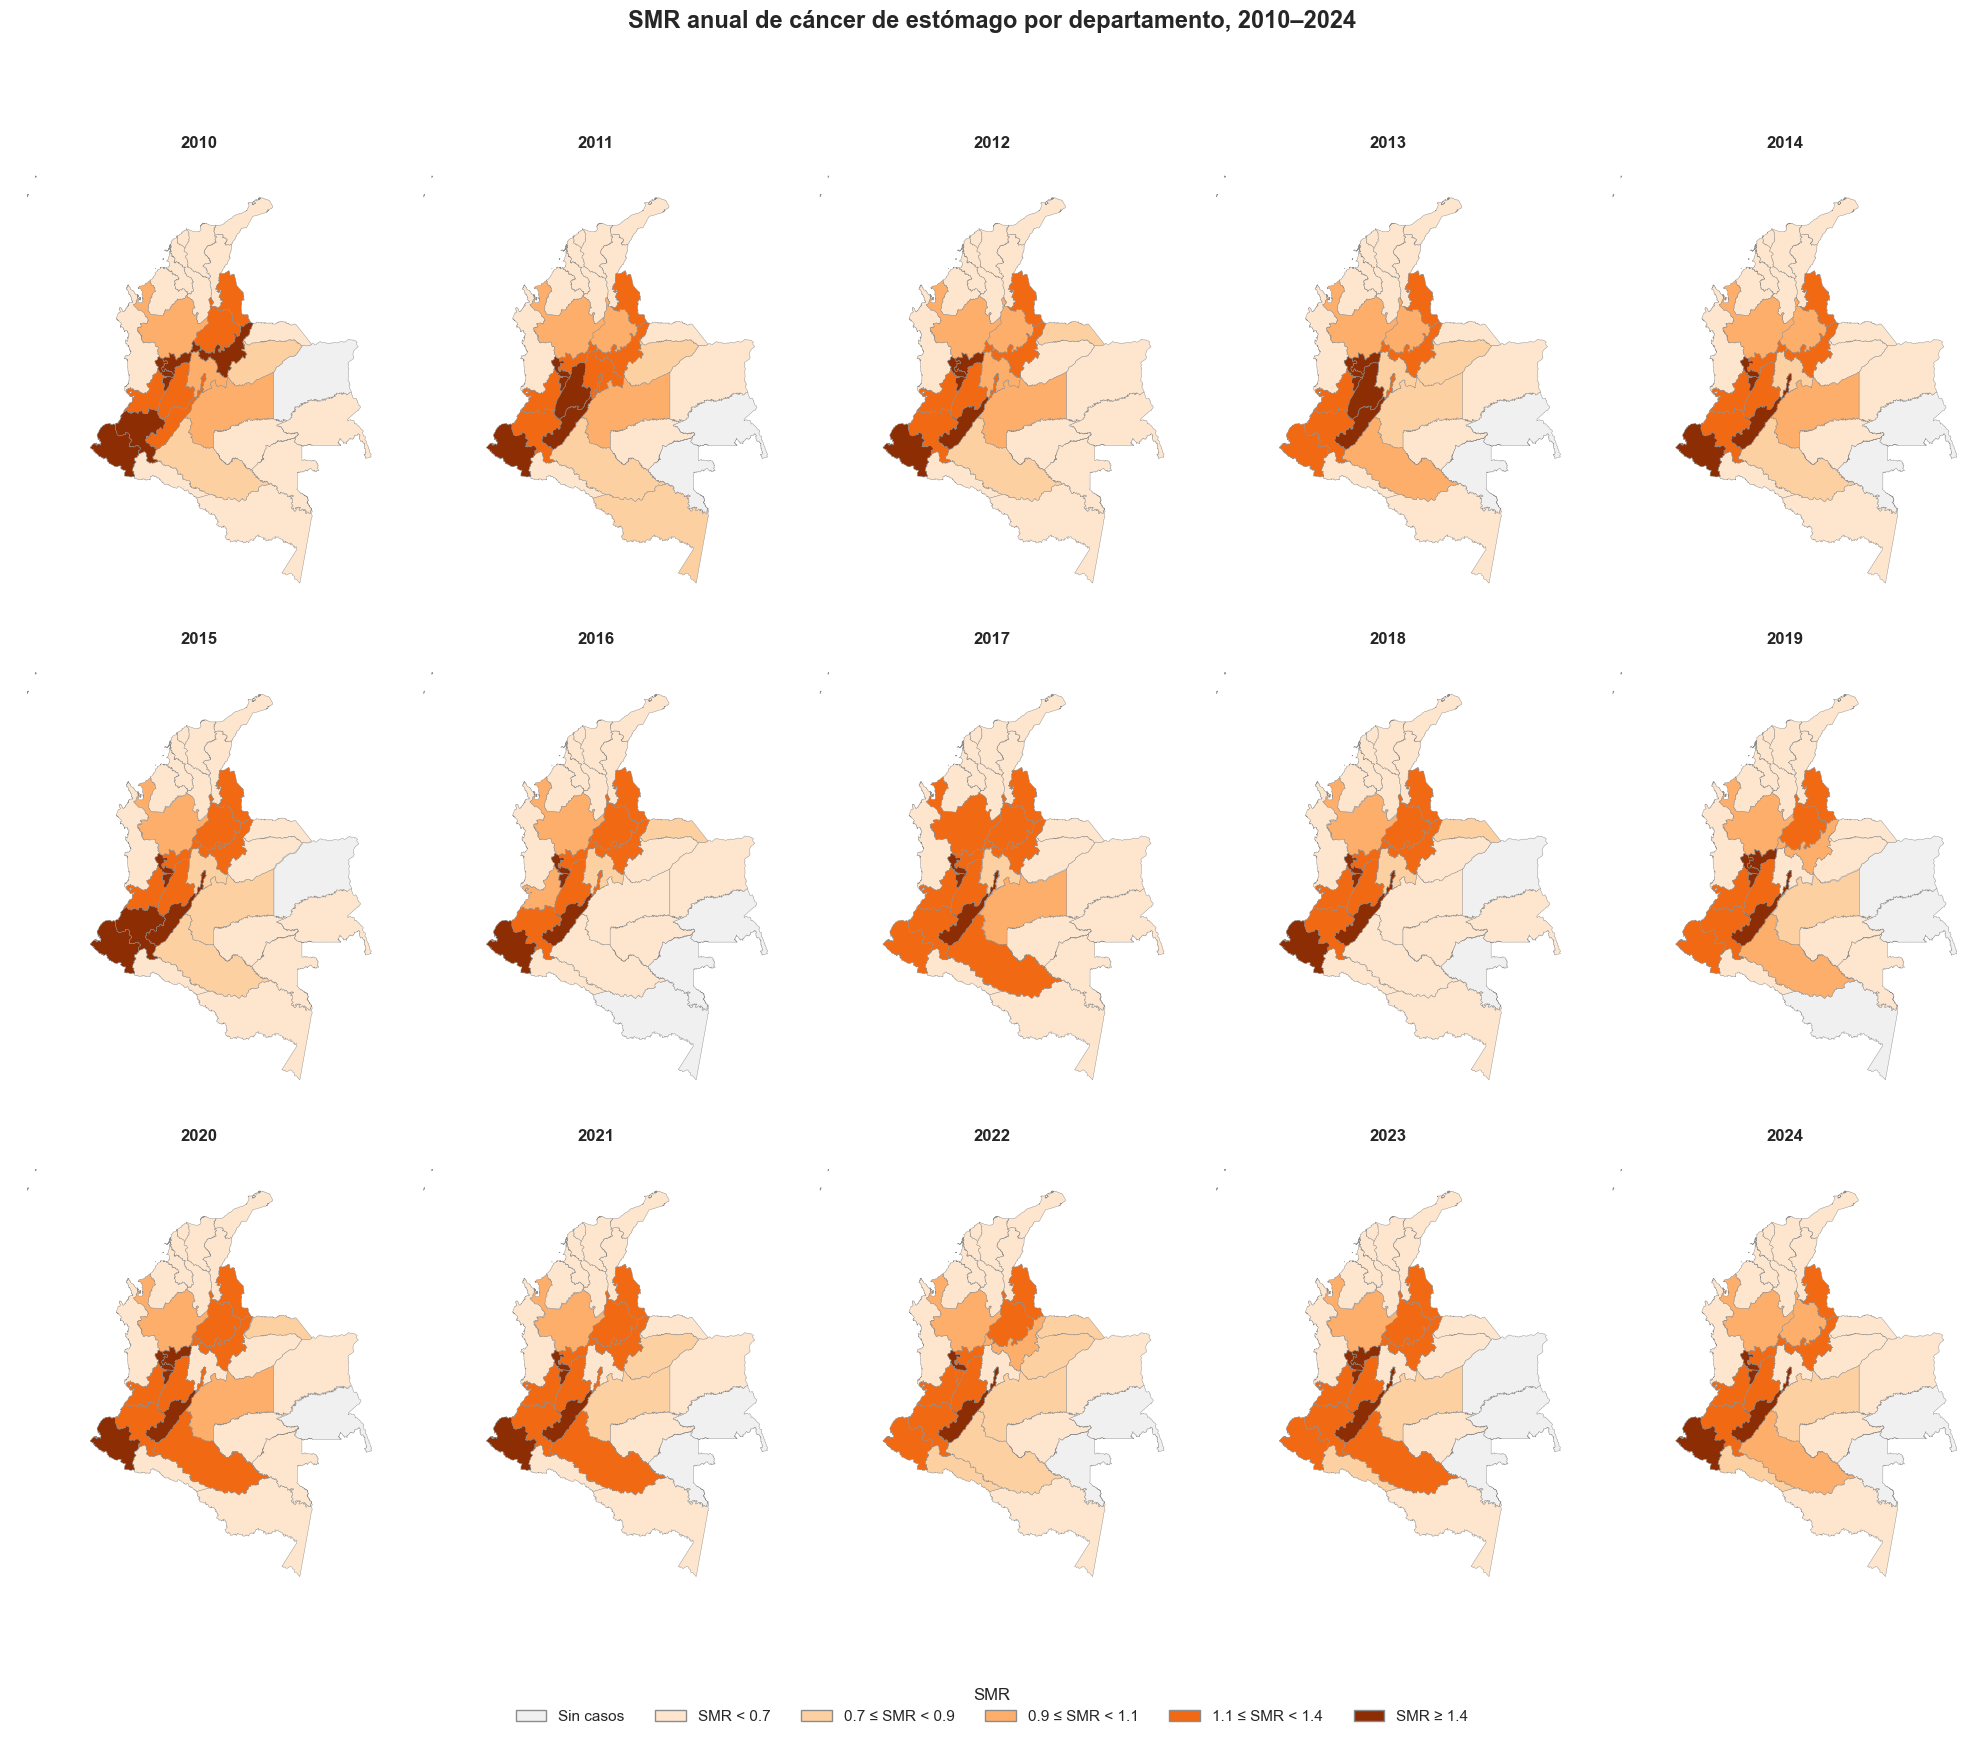

In [26]:
anos = list(range(2010, 2025))

fig, axes = plt.subplots(
    3,
    5,
    figsize=(20, 18)
)

axes = axes.flatten()

for ax, ano in zip(axes, anos):
    mapa_smr = gdf_smr_anual[
        gdf_smr_anual["ANO"] == ano
    ].copy()

    for categoria, color in colores_smr.items():
        subset = mapa_smr[
            mapa_smr["Categoria_SMR"] == categoria
        ]

        if not subset.empty:
            subset.plot(
                ax=ax,
                color=color,
                edgecolor="#8c8c8c",
                linewidth=0.3,
                aspect=1
            )

    ax.set_title(
        str(ano),
        fontsize=12,
        fontweight="bold"
    )

    ax.axis("off")

leyenda = [
    Patch(
        facecolor=colores_smr[categoria],
        edgecolor="#8c8c8c",
        label=categoria
    )
    for categoria in orden_leyenda
]

fig.legend(
    handles=leyenda,
    title="SMR",
    loc="lower center",
    bbox_to_anchor=(0.5, 0.02),
    ncol=6,
    frameon=False
)

fig.suptitle(
    "SMR anual de cáncer de estómago por departamento, 2010–2024",
    fontsize=17,
    fontweight="bold",
    y=0.98
)

plt.tight_layout(rect=[0, 0.06, 1, 0.96])
plt.show()

#### 3.4 Mapas quinquenales del SMR

Los siguientes mapas muestran la distribución espacial del SMR departamental durante los quinquenios 2010–2014, 2015–2019 y 2020–2024. La utilización de una misma clasificación en los tres periodos permite comparar la evolución del patrón espacial de mortalidad por cáncer de estómago.

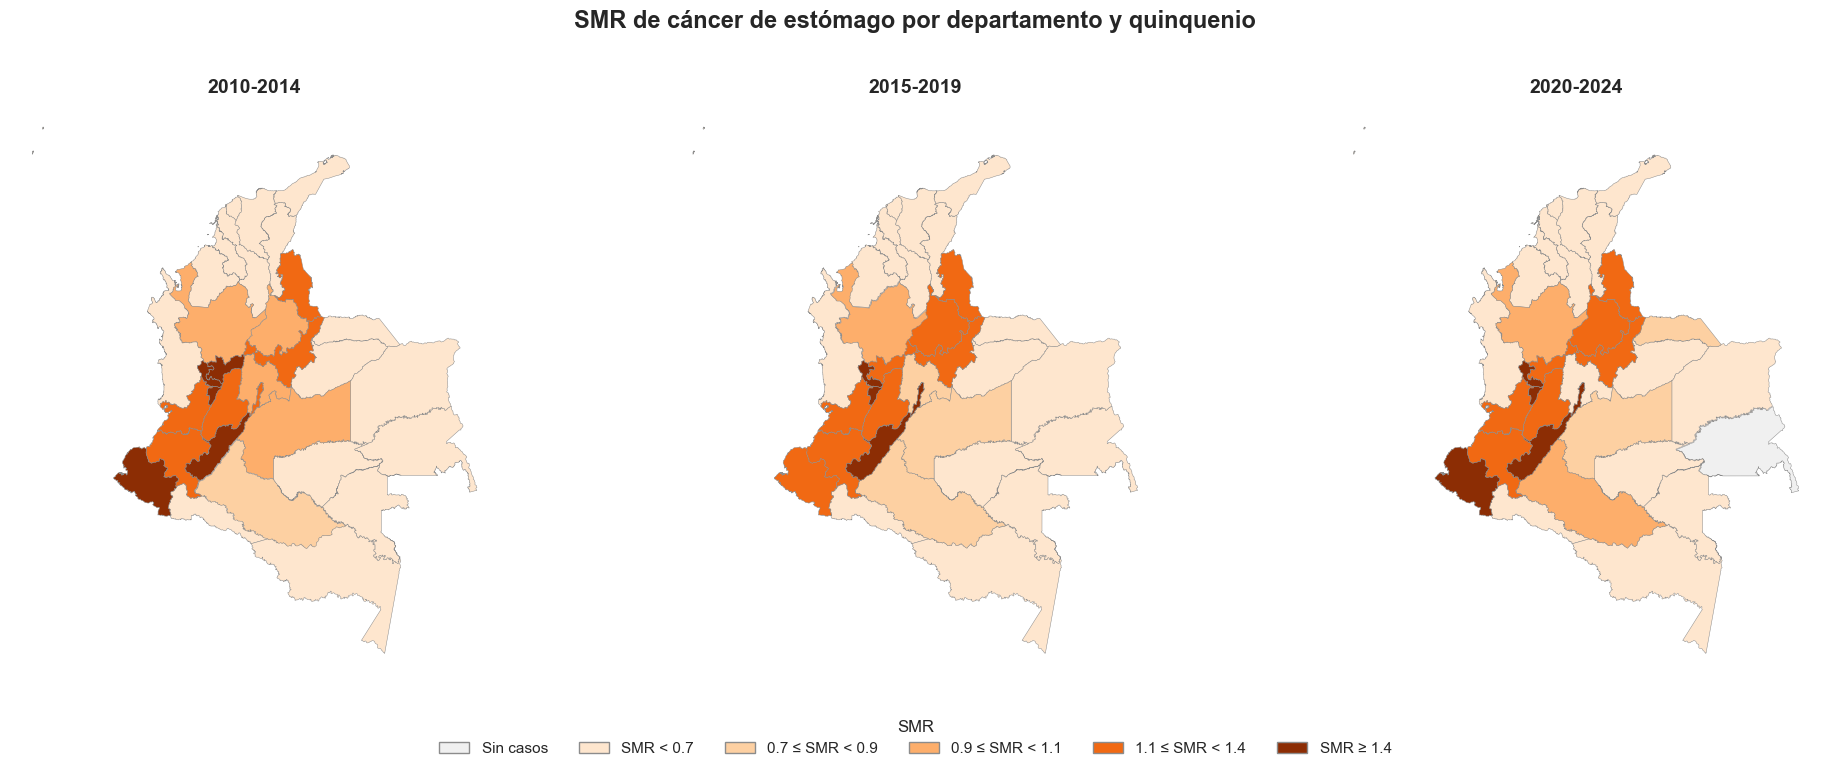

In [27]:
quinquenios = [
    "2010-2014",
    "2015-2019",
    "2020-2024"
]

fig, axes = plt.subplots(
    1,
    3,
    figsize=(20, 8)
)

for ax, quinquenio in zip(axes, quinquenios):
    mapa_smr = gdf_smr_quinquenal[
        gdf_smr_quinquenal["Quinquenio"] == quinquenio
    ].copy()

    for categoria, color in colores_smr.items():
        subset = mapa_smr[
            mapa_smr["Categoria_SMR"] == categoria
        ]

        if not subset.empty:
            subset.plot(
                ax=ax,
                color=color,
                edgecolor="#8c8c8c",
                linewidth=0.35,
                aspect=1
            )

    ax.set_title(
        quinquenio,
        fontsize=14,
        fontweight="bold"
    )

    ax.axis("off")

leyenda = [
    Patch(
        facecolor=colores_smr[categoria],
        edgecolor="#8c8c8c",
        label=categoria
    )
    for categoria in orden_leyenda
]

fig.legend(
    handles=leyenda,
    title="SMR",
    loc="lower center",
    bbox_to_anchor=(0.5, 0.01),
    ncol=6,
    frameon=False
)

fig.suptitle(
    "SMR de cáncer de estómago por departamento y quinquenio",
    fontsize=17,
    fontweight="bold",
    y=0.96
)

plt.tight_layout(rect=[0, 0.10, 1, 0.92])
plt.show()

## 4. Persistencia del exceso de mortalidad departamental

### 4.1 Identificación anual del exceso de mortalidad

Para evaluar la persistencia del exceso de mortalidad, se identifica inicialmente si el SMR departamental anual es superior a 1. Posteriormente, los resultados anuales se agrupan según los tres quinquenios del periodo de estudio.

Este procedimiento permite distinguir entre un exceso aislado en un año específico y un patrón que se mantiene durante varios periodos.

In [28]:
persistencia_anual = smr_departamento_anual.copy()

persistencia_anual["SMR_mayor_1"] = (
    persistencia_anual["SMR"] > 1
)

persistencia_anual["Quinquenio"] = pd.cut(
    persistencia_anual["ANO"],
    bins=[2009, 2014, 2019, 2024],
    labels=["2010-2014", "2015-2019", "2020-2024"]
)

In [29]:
indicador_anual_quinquenio = (
    persistencia_anual
    .groupby(
        ["dpto_ccdgo", "Quinquenio"],
        observed=True,
        as_index=False
    )
    .agg(
        Anos_SMR_mayor_1=("SMR_mayor_1", "sum"),
        Al_menos_un_ano_SMR_mayor_1=("SMR_mayor_1", "any")
    )
)

indicador_anual_quinquenio = indicador_anual_quinquenio.merge(
    nombres_departamentos,
    on="dpto_ccdgo",
    how="left",
    validate="many_to_one"
)

### 4.2 Persistencia del exceso de mortalidad por quinquenio

El indicador anual se complementa con el SMR calculado para cada quinquenio. Para cada departamento y periodo se evalúa conjuntamente la presencia de al menos un año con $SMR > 1$ y un $SMR$ quinquenal superior a 1.

A partir de estos dos componentes se construye un indicador de exceso de mortalidad para cada quinquenio.

In [30]:
indicador_persistencia = indicador_anual_quinquenio.merge(
    smr_departamento_quinquenal[
        ["dpto_ccdgo", "Quinquenio", "SMR"]
    ].rename(
        columns={"SMR": "SMR_quinquenal"}
    ),
    on=["dpto_ccdgo", "Quinquenio"],
    how="left",
    validate="one_to_one"
)

indicador_persistencia["Indicador_exceso"] = (
    indicador_persistencia["Al_menos_un_ano_SMR_mayor_1"]
    & (indicador_persistencia["SMR_quinquenal"] > 1)
)

In [31]:
tabla_indicador_persistencia = indicador_persistencia[
    [
        "DPNOM",
        "Quinquenio",
        "Anos_SMR_mayor_1",
        "SMR_quinquenal",
        "Indicador_exceso"
    ]
].copy()

tabla_indicador_persistencia = tabla_indicador_persistencia.rename(
    columns={
        "DPNOM": "Departamento",
        "Anos_SMR_mayor_1": "Años con SMR > 1",
        "SMR_quinquenal": "SMR quinquenal",
        "Indicador_exceso": "Exceso"
    }
)

tabla_indicador_persistencia["Exceso"] = (
    tabla_indicador_persistencia["Exceso"]
    .map({True: "Sí", False: "No"})
)

styled = (
    tabla_indicador_persistencia.style
    .hide(axis="index")
    .format({
        "SMR quinquenal": "{:.2f}"
    })
    .set_table_styles([
        {
            "selector": "table",
            "props": [
                ("margin", "auto"),
                ("width", "auto"),
                ("border-collapse", "collapse")
            ]
        },
        {
            "selector": "th",
            "props": [
                ("text-align", "center"),
                ("background-color", "#f2f2f2"),
                ("color", "black"),
                ("font-weight", "bold"),
                ("border", "1px solid black"),
                ("padding", "10px")
            ]
        },
        {
            "selector": "td",
            "props": [
                ("text-align", "center"),
                ("border", "1px solid black"),
                ("padding", "10px")
            ]
        }
    ])
    .set_properties(
        subset=["Departamento"],
        **{"text-align": "left"}
    )
)

display(
    HTML(
        "<div style='text-align: center; width: 100%;'>"
        + styled.to_html()
        + "</div>"
    )
)

Departamento,Quinquenio,Años con SMR > 1,SMR quinquenal,Exceso
Antioquia,2010-2014,2,1.01,Sí
Antioquia,2015-2019,4,1.06,Sí
Antioquia,2020-2024,5,1.06,Sí
Atlántico,2010-2014,0,0.40,No
Atlántico,2015-2019,0,0.53,No
Atlántico,2020-2024,0,0.50,No
"Bogotá, D.C.",2010-2014,5,1.33,Sí
"Bogotá, D.C.",2015-2019,5,1.42,Sí
"Bogotá, D.C.",2020-2024,5,1.43,Sí
Bolívar,2010-2014,0,0.34,No


### 4.3 Departamentos con exceso persistente de mortalidad

A partir del indicador definido previamente, se evalúa el número de quinquenios en los que cada departamento presenta exceso de mortalidad. Se considera persistente cuando el indicador de exceso se cumple en al menos dos de los tres quinquenios analizados.

Este criterio permite identificar los departamentos donde el exceso de mortalidad no corresponde únicamente a un periodo aislado, sino que se mantiene durante una parte importante del periodo de estudio.

In [32]:
persistencia_departamental = (
    indicador_persistencia
    .groupby(
        ["dpto_ccdgo", "DPNOM"],
        as_index=False
    )
    .agg(
        Quinquenios_exceso=("Indicador_exceso", "sum")
    )
)

persistencia_departamental["Persistente"] = (
    persistencia_departamental["Quinquenios_exceso"] >= 2
)

departamentos_persistentes = (
    persistencia_departamental[
        persistencia_departamental["Persistente"]
    ]
    .sort_values(
        ["Quinquenios_exceso", "dpto_ccdgo"],
        ascending=[False, True]
    )
    .reset_index(drop=True)
)

In [33]:
tabla_persistencia = departamentos_persistentes[
    [
        "dpto_ccdgo",
        "DPNOM",
        "Quinquenios_exceso"
    ]
].copy()

tabla_persistencia = tabla_persistencia.rename(
    columns={
        "dpto_ccdgo": "Código",
        "DPNOM": "Departamento",
        "Quinquenios_exceso": "Quinquenios con exceso"
    }
)

styled = (
    tabla_persistencia.style
    .hide(axis="index")
    .set_table_styles([
        {
            "selector": "table",
            "props": [
                ("margin", "auto"),
                ("width", "auto"),
                ("border-collapse", "collapse")
            ]
        },
        {
            "selector": "th",
            "props": [
                ("text-align", "center"),
                ("background-color", "#f2f2f2"),
                ("color", "black"),
                ("font-weight", "bold"),
                ("border", "1px solid black"),
                ("padding", "10px")
            ]
        },
        {
            "selector": "td",
            "props": [
                ("text-align", "center"),
                ("border", "1px solid black"),
                ("padding", "10px")
            ]
        }
    ])
    .set_properties(
        subset=["Departamento"],
        **{"text-align": "left"}
    )
)

display(
    HTML(
        "<div style='text-align: center; width: 100%;'>"
        + styled.to_html()
        + "</div>"
    )
)

Código,Departamento,Quinquenios con exceso
05,Antioquia,3
11,"Bogotá, D.C.",3
15,Boyacá,3
17,Caldas,3
19,Cauca,3
41,Huila,3
52,Nariño,3
54,Norte de Santander,3
63,Quindío,3
66,Risaralda,3


### 4.4 Evolución anual del SMR en los departamentos de mayor riesgo

A partir de los departamentos que presentan exceso persistente de mortalidad, se seleccionan los cinco con mayor SMR promedio durante los tres quinquenios. Posteriormente, se analiza la evolución anual de su SMR entre 2010 y 2024.

Este análisis permite observar la estabilidad y las variaciones temporales del exceso de mortalidad en los departamentos con mayor riesgo.

In [34]:
top_5_departamentos = (
    departamentos_persistentes[
        ["dpto_ccdgo", "DPNOM", "Quinquenios_exceso"]
    ]
    .merge(
        smr_departamento_quinquenal.groupby(
            ["dpto_ccdgo", "DPNOM"],
            as_index=False
        ).agg(
            SMR_promedio=("SMR", "mean")
        ),
        on=["dpto_ccdgo", "DPNOM"],
        how="left",
        validate="one_to_one"
    )
    .sort_values(
        "SMR_promedio",
        ascending=False
    )
    .head(5)
    .reset_index(drop=True)
)

In [35]:
evolucion_top_5 = (
    smr_departamento_anual[
        smr_departamento_anual["dpto_ccdgo"].isin(
            top_5_departamentos["dpto_ccdgo"]
        )
    ]
    [
        ["ANO", "dpto_ccdgo", "SMR"]
    ]
    .merge(
        nombres_departamentos,
        on="dpto_ccdgo",
        how="left",
        validate="many_to_one"
    )
    .sort_values(
        ["dpto_ccdgo", "ANO"]
    )
    .reset_index(drop=True)
)

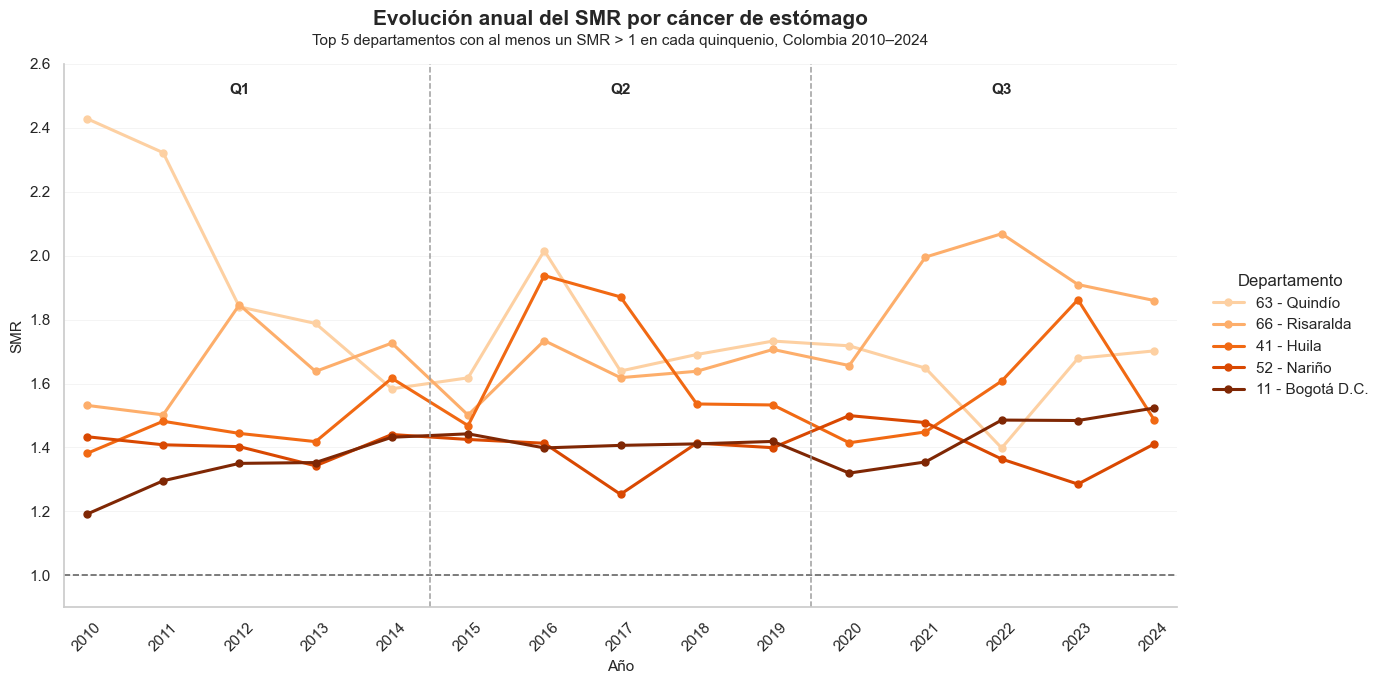

In [36]:
colores_top_5 = {
    "63": "#FDD0A2",
    "66": "#FDAE6B",
    "41": "#F16913",
    "52": "#D94801",
    "11": "#7F2704"
}

etiquetas_top_5 = {
    "63": "63 - Quindío",
    "66": "66 - Risaralda",
    "41": "41 - Huila",
    "52": "52 - Nariño",
    "11": "11 - Bogotá D.C."
}

orden_top_5 = ["63", "66", "41", "52", "11"]

fig, ax = plt.subplots(figsize=(14, 7))

for codigo in orden_top_5:
    datos = evolucion_top_5[
        evolucion_top_5["dpto_ccdgo"] == codigo
    ]

    ax.plot(
        datos["ANO"],
        datos["SMR"],
        color=colores_top_5[codigo],
        marker="o",
        markersize=5,
        linewidth=2.2,
        label=etiquetas_top_5[codigo]
    )

ax.axhline(
    y=1,
    color="#666666",
    linestyle="--",
    linewidth=1.2
)

for x in [2014.5, 2019.5]:
    ax.axvline(
        x=x,
        color="#9E9E9E",
        linestyle="--",
        linewidth=1.1
    )

ax.text(
    2012,
    2.52,
    "Q1",
    ha="center",
    va="center",
    fontsize=11,
    fontweight="bold"
)

ax.text(
    2017,
    2.52,
    "Q2",
    ha="center",
    va="center",
    fontsize=11,
    fontweight="bold"
)

ax.text(
    2022,
    2.52,
    "Q3",
    ha="center",
    va="center",
    fontsize=11,
    fontweight="bold"
)

ax.set_title(
    "Evolución anual del SMR por cáncer de estómago",
    fontsize=15,
    fontweight="bold",
    pad=28
)

ax.text(
    0.5,
    1.035,
    "Top 5 departamentos con al menos un SMR > 1 en cada quinquenio, Colombia 2010–2024",
    transform=ax.transAxes,
    ha="center",
    fontsize=11
)

ax.set_xlabel("Año", fontsize=11)
ax.set_ylabel("SMR", fontsize=11)

ax.set_xticks(range(2010, 2025))
ax.tick_params(axis="x", rotation=45)

ax.set_xlim(2009.7, 2024.3)
ax.set_ylim(0.9, 2.6)

ax.grid(
    axis="y",
    linestyle="-",
    linewidth=0.6,
    alpha=0.25
)

ax.grid(
    axis="x",
    visible=False
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.legend(
    title="Departamento",
    bbox_to_anchor=(1.02, 0.5),
    loc="center left",
    frameon=False
)

plt.tight_layout()
plt.show()

### 4.5 Distribución espacial de los departamentos de mayor riesgo

Los cinco departamentos priorizados a partir de la persistencia del exceso de mortalidad y del SMR promedio quinquenal se representan espacialmente para identificar su distribución geográfica en Colombia.

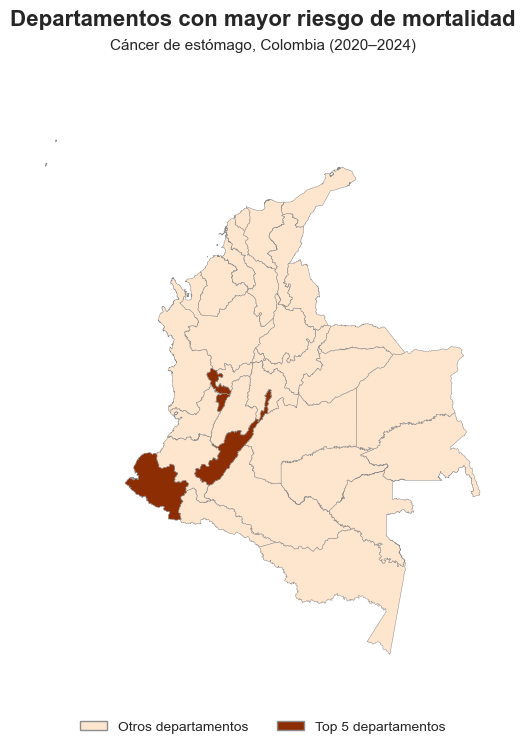

In [161]:
codigos_top_5 = top_5_departamentos["dpto_ccdgo"].tolist()

gdf_top_5 = gdf_departamentos.copy()

gdf_top_5["Departamento_riesgoso"] = np.where(
    gdf_top_5["DPTO_CCDGO"].isin(codigos_top_5),
    "Top 5",
    "Otros departamentos"
)

colores_top5 = {
    "Otros departamentos": "#fee6ce",
    "Top 5": "#8c2d04"
}

fig, ax = plt.subplots(figsize=(12, 8))

for categoria in ["Otros departamentos", "Top 5"]:
    gdf_top_5[
        gdf_top_5["Departamento_riesgoso"] == categoria
    ].plot(
        ax=ax,
        color=colores_top5[categoria],
        edgecolor="#8c8c8c",
        linewidth=0.35
    )

ax.set_aspect("equal")
ax.axis("off")

leyenda = [
    Patch(
        facecolor=colores_top5["Otros departamentos"],
        edgecolor="#8c8c8c",
        label="Otros departamentos"
    ),
    Patch(
        facecolor=colores_top5["Top 5"],
        edgecolor="#8c8c8c",
        label="Top 5 departamentos"
    )
]

fig.legend(
    handles=leyenda,
    loc="lower center",
    bbox_to_anchor=(0.5, 0.04),
    ncol=2,
    frameon=False,
    fontsize=10
)

fig.suptitle(
    "Departamentos con mayor riesgo de mortalidad",
    fontsize=16,
    fontweight="bold",
    y=0.96
)

fig.text(
    0.5,
    0.91,
    "Cáncer de estómago, Colombia (2020–2024)",
    ha="center",
    fontsize=11
)

plt.tight_layout(rect=[0, 0.10, 1, 0.90])
plt.show()

## 5. Autocorrelación espacial

### 5.1 Construcción de la estructura de vecindad

La dependencia espacial entre los departamentos se representa mediante una estructura de vecindad construida a partir de sus límites geográficos. Esta estructura define qué departamentos se consideran vecinos y constituye la base para evaluar la autocorrelación espacial y, posteriormente, incorporar el efecto espacial estructurado en el modelo BYM2.

Antes del cálculo del índice de Moran se inspecciona la estructura resultante, incluyendo el número de vecinos por departamento, la presencia de unidades aisladas y la conectividad del grafo espacial.

In [38]:
gdf_vecindad = (
    gdf_departamentos[
        ["DPTO_CCDGO", "DPTO_CNMBR", "geometry"]
    ]
    .sort_values("DPTO_CCDGO")
    .reset_index(drop=True)
)

w_departamentos = Queen.from_dataframe(
    gdf_vecindad,
    ids="DPTO_CCDGO",
    use_index=False
)

numero_vecinos = pd.DataFrame({
    "dpto_ccdgo": list(w_departamentos.neighbors.keys()),
    "Numero_vecinos": [
        len(vecinos)
        for vecinos in w_departamentos.neighbors.values()
    ]
})

numero_vecinos = numero_vecinos.merge(
    gdf_vecindad[
        ["DPTO_CCDGO", "DPTO_CNMBR"]
    ],
    left_on="dpto_ccdgo",
    right_on="DPTO_CCDGO",
    how="left"
)

numero_vecinos = numero_vecinos[
    ["dpto_ccdgo", "DPTO_CNMBR", "Numero_vecinos"]
].sort_values(
    ["Numero_vecinos", "dpto_ccdgo"]
).reset_index(drop=True)

tabla_vecinos = (
    numero_vecinos
    .rename(
        columns={
            "dpto_ccdgo": "Código",
            "DPTO_CNMBR": "Departamento",
            "Numero_vecinos": "Número de vecinos"
        }
    )
)

styled = (
    tabla_vecinos.style
    .hide(axis="index")
    .set_table_styles([
        {
            "selector": "table",
            "props": [
                ("margin", "0 auto"),
                ("width", "auto"),
                ("border-collapse", "collapse")
            ]
        },
        {
            "selector": "th",
            "props": [
                ("text-align", "center"),
                ("background-color", "#f2f2f2"),
                ("color", "black"),
                ("font-weight", "bold"),
                ("border", "1px solid black"),
                ("padding", "10px")
            ]
        },
        {
            "selector": "td",
            "props": [
                ("text-align", "center"),
                ("border", "1px solid black"),
                ("padding", "10px")
            ]
        }
    ])
    .set_properties(
        subset=["Departamento"],
        **{"text-align": "left"}
    )
)

display(
    HTML(
        "<div style='text-align: center; width: 100%;'>"
        + styled.to_html()
        + "</div>"
    )
)

C:\Users\USER\anaconda3\envs\EEG_EDA_ML\lib\site-packages\libpysal\weights\weights.py:224: UserWarning: The weights matrix is not fully connected: 
 There are 2 disconnected components.
 There is 1 island with id: 88.
  warnings.warn(message)


Código,Departamento,Número de vecinos
88,"ARCHIPIÉLAGO DE SAN ANDRÉS, PROVIDENCIA Y SANTA CATALINA",0
08,ATLÁNTICO,2
44,LA GUAJIRA,2
52,NARIÑO,2
70,SUCRE,2
11,"BOGOTÁ, D.C.",3
23,CÓRDOBA,3
27,CHOCÓ,3
54,NORTE DE SANTANDER,3
63,QUINDÍO,3


In [39]:
componentes = w_departamentos.n_components
aislados = w_departamentos.islands

print(f"Número de componentes conexos: {componentes}")
print(f"Departamentos aislados: {aislados}")

Número de componentes conexos: 2
Departamentos aislados: ['88']


### 5.2 Índice global de Moran

El índice global de Moran permite evaluar si los valores del SMR presentan autocorrelación espacial, es decir, si departamentos geográficamente próximos tienden a presentar niveles de riesgo similares.

Para este análisis se utiliza la estructura de vecindad previamente construida. Debido a que San Andrés no presenta vecinos por contigüidad, el cálculo se realiza sobre el componente espacial conectado.

In [40]:
gdf_moran = gdf_vecindad[
    ~gdf_vecindad["DPTO_CCDGO"].isin(aislados)
].copy()

smr_moran = smr_departamento_quinquenal[
    ~smr_departamento_quinquenal["dpto_ccdgo"].isin(aislados)
].copy()

smr_moran = smr_moran.merge(
    gdf_moran[
        ["DPTO_CCDGO", "geometry"]
    ],
    left_on="dpto_ccdgo",
    right_on="DPTO_CCDGO",
    how="left",
    validate="many_to_one"
)

smr_moran = gpd.GeoDataFrame(
    smr_moran,
    geometry="geometry",
    crs=gdf_moran.crs
)

smr_moran = (
    smr_moran
    .sort_values(["Quinquenio", "dpto_ccdgo"])
    .reset_index(drop=True)
)

tabla_validacion_moran = (
    smr_moran
    .groupby("Quinquenio", observed=True)
    .agg(
        Departamentos=("dpto_ccdgo", "nunique"),
        SMR_faltantes=("SMR", lambda x: x.isna().sum()),
        Geometrias_faltantes=("geometry", lambda x: x.isna().sum())
    )
    .reset_index()
    .rename(
        columns={
            "Quinquenio": "Quinquenio",
            "Departamentos": "Departamentos",
            "SMR_faltantes": "SMR faltantes",
            "Geometrias_faltantes": "Geometrías faltantes"
        }
    )
)

styled = (
    tabla_validacion_moran.style
    .hide(axis="index")
    .set_table_styles([
        {
            "selector": "table",
            "props": [
                ("margin", "0 auto"),
                ("width", "auto"),
                ("border-collapse", "collapse")
            ]
        },
        {
            "selector": "th",
            "props": [
                ("text-align", "center"),
                ("background-color", "#f2f2f2"),
                ("color", "black"),
                ("font-weight", "bold"),
                ("border", "1px solid black"),
                ("padding", "10px")
            ]
        },
        {
            "selector": "td",
            "props": [
                ("text-align", "center"),
                ("border", "1px solid black"),
                ("padding", "10px")
            ]
        }
    ])
)

display(
    HTML(
        "<div style='text-align: center; width: 100%;'>"
        + styled.to_html()
        + "</div>"
    )
)

Quinquenio,Departamentos,SMR faltantes,Geometrías faltantes
2010-2014,32,0,0
2015-2019,32,0,0
2020-2024,32,0,0


In [41]:
w_moran = Queen.from_dataframe(
    gdf_moran,
    ids="DPTO_CCDGO",
    use_index=False
)

w_moran.transform = "r"

print(f"Número de departamentos: {w_moran.n}")
print(f"Número de componentes conexos: {w_moran.n_components}")
print(f"Departamentos aislados: {w_moran.islands}")

Número de departamentos: 32
Número de componentes conexos: 1
Departamentos aislados: []


In [42]:
resultados_moran = []

for quinquenio in ["2010-2014", "2015-2019", "2020-2024"]:
    datos_periodo = (
        smr_moran[
            smr_moran["Quinquenio"].astype(str) == quinquenio
        ]
        .set_index("dpto_ccdgo")
        .reindex(w_moran.id_order)
    )

    moran = Moran(
        datos_periodo["SMR"].to_numpy(),
        w_moran,
        permutations=9999
    )

    resultados_moran.append({
        "Quinquenio": quinquenio,
        "I de Moran": moran.I,
        "I esperado": moran.EI,
        "p-valor": moran.p_sim
    })

resultados_moran = pd.DataFrame(resultados_moran)

tabla_resultados_moran = resultados_moran.copy()

styled = (
    tabla_resultados_moran.style
    .hide(axis="index")
    .format({
        "I de Moran": "{:.4f}",
        "I esperado": "{:.4f}",
        "p-valor": "{:.4f}"
    })
    .set_table_styles([
        {
            "selector": "table",
            "props": [
                ("margin", "0 auto"),
                ("width", "auto"),
                ("border-collapse", "collapse")
            ]
        },
        {
            "selector": "th",
            "props": [
                ("text-align", "center"),
                ("background-color", "#f2f2f2"),
                ("color", "black"),
                ("font-weight", "bold"),
                ("border", "1px solid black"),
                ("padding", "10px")
            ]
        },
        {
            "selector": "td",
            "props": [
                ("text-align", "center"),
                ("border", "1px solid black"),
                ("padding", "10px")
            ]
        }
    ])
)

display(
    HTML(
        "<div style='text-align: center; width: 100%;'>"
        + styled.to_html()
        + "</div>"
    )
)

Quinquenio,I de Moran,I esperado,p-valor
2010-2014,0.5223,-0.0323,0.0002
2015-2019,0.4829,-0.0323,0.0001
2020-2024,0.4450,-0.0323,0.0004


Los tres quinquenios presentan autocorrelación espacial positiva y estadísticamente significativa. El índice de Moran fue de 0.5223 en 2010–2014, 0.4829 en 2015–2019 y 0.4450 en 2020–2024, con valores considerablemente superiores al valor esperado bajo aleatoriedad espacial (-0.0323) y p-valores inferiores a 0.001. Esto indica que los departamentos con niveles similares de riesgo relativo tienden a localizarse próximos entre sí, evidenciando agrupamiento espacial del riesgo de mortalidad por cáncer de estómago.

Aunque la autocorrelación se mantiene durante todo el periodo, el índice disminuye progresivamente de 0.5223 a 0.4450, lo que sugiere una reducción moderada de la intensidad del patrón de agrupamiento espacial. Sin embargo, la dependencia espacial continúa siendo clara en 2020–2024, respaldando la incorporación de una estructura espacial en la modelación posterior mediante BYM2.

## 6. Modelamiento jerárquico bayesiano espacial

### 6.1 Preparación de los datos para el modelo BYM2

El modelo BYM2 se plantea a partir del número de defunciones observadas y esperadas en cada unidad geográfica. Para cada departamento $i$, se considera:

$$
Y_i \mid \theta_i \sim \operatorname{Poisson}(E_i\theta_i)
$$

donde $Y_i$ corresponde al número de defunciones observadas, $E_i$ al número de defunciones esperadas y $\theta_i$ al riesgo relativo de mortalidad.

Como primera etapa se organiza la información departamental necesaria para el ajuste del modelo, conservando la correspondencia entre las unidades geográficas y la estructura espacial de vecindad.

In [43]:
datos_bym2 = (
    smr_departamento_quinquenal[
        smr_departamento_quinquenal["Quinquenio"].astype(str) == "2020-2024"
    ]
    [
        ["dpto_ccdgo", "DPNOM", "Observadas", "Esperadas", "SMR"]
    ]
    .sort_values("dpto_ccdgo")
    .reset_index(drop=True)
)

datos_bym2["Observadas"] = datos_bym2["Observadas"].astype(int)

print(f"Número de departamentos: {len(datos_bym2)}")
print(f"Defunciones observadas: {datos_bym2['Observadas'].sum():,}")
print(f"Defunciones esperadas: {datos_bym2['Esperadas'].sum():,.2f}")
print(f"Valores faltantes: {datos_bym2.isna().sum().sum()}")
print(f"Esperadas <= 0: {(datos_bym2['Esperadas'] <= 0).sum()}")

Número de departamentos: 33
Defunciones observadas: 26,418
Defunciones esperadas: 26,418.00
Valores faltantes: 0
Esperadas <= 0: 0


### 6.2 Estructura espacial para el modelo BYM2

El componente espacial estructurado del modelo BYM2 se define a partir de la relación de vecindad entre los departamentos. Esta estructura permite representar la dependencia espacial del riesgo, de manera que departamentos geográficamente conectados comparten información a través del efecto espacial estructurado.

Antes del ajuste del modelo se verifica la correspondencia entre las unidades incluidas en la base epidemiológica y la estructura de vecindad, así como la presencia de unidades geográficas aisladas.

In [44]:
codigos_bym2 = set(datos_bym2["dpto_ccdgo"])
codigos_geografia = set(gdf_vecindad["DPTO_CCDGO"])

sin_geometria = sorted(codigos_bym2 - codigos_geografia)
sin_datos = sorted(codigos_geografia - codigos_bym2)

w_bym2 = Queen.from_dataframe(
    gdf_vecindad,
    ids="DPTO_CCDGO",
    use_index=False
)

print(f"Unidades en datos BYM2: {len(codigos_bym2)}")
print(f"Unidades en estructura geográfica: {w_bym2.n}")
print(f"Datos sin geometría: {sin_geometria}")
print(f"Geometrías sin datos: {sin_datos}")
print(f"Componentes conexos: {w_bym2.n_components}")
print(f"Unidades aisladas: {w_bym2.islands}")

Unidades en datos BYM2: 33
Unidades en estructura geográfica: 33
Datos sin geometría: []
Geometrías sin datos: []
Componentes conexos: 2
Unidades aisladas: ['88']


C:\Users\USER\anaconda3\envs\EEG_EDA_ML\lib\site-packages\libpysal\weights\weights.py:224: UserWarning: The weights matrix is not fully connected: 
 There are 2 disconnected components.
 There is 1 island with id: 88.
  warnings.warn(message)


### 6.3 Construcción del componente espacial estructurado

El componente espacial estructurado del modelo BYM2 se construye a partir de las 32 unidades geográficas conectadas. Para este componente se utiliza una estructura de vecindad tipo Queen y se construye la matriz de adyacencia $W$.

A partir del número de vecinos de cada departamento se define la matriz diagonal $D$ y posteriormente la matriz de precisión espacial:

$$
Q = D - W
$$

Esta matriz representa la estructura de dependencia espacial utilizada por el efecto ICAR del modelo BYM2. San Andrés se mantiene fuera de este componente estructurado debido a que no presenta vecinos por contigüidad.

In [45]:
codigos_conectados = [
    codigo
    for codigo in w_bym2.id_order
    if codigo not in w_bym2.islands
]

gdf_bym2_conectado = (
    gdf_vecindad[
        gdf_vecindad["DPTO_CCDGO"].isin(codigos_conectados)
    ]
    .set_index("DPTO_CCDGO")
    .loc[codigos_conectados]
    .reset_index()
)

w_bym2_conectado = Queen.from_dataframe(
    gdf_bym2_conectado,
    ids="DPTO_CCDGO",
    use_index=False
)

print(f"Unidades conectadas: {w_bym2_conectado.n}")
print(f"Componentes conexos: {w_bym2_conectado.n_components}")
print(f"Unidades aisladas: {w_bym2_conectado.islands}")
print(f"San Andrés incluido: {'88' in w_bym2_conectado.id_order}")

Unidades conectadas: 32
Componentes conexos: 1
Unidades aisladas: []
San Andrés incluido: False


#### 6.3.2 Matriz de precisión espacial

A partir de la estructura de vecindad del componente conectado se construye la matriz de adyacencia binaria $W$, donde cada elemento $w_{ij}$ toma el valor 1 cuando los departamentos $i$ y $j$ son vecinos y 0 en caso contrario.

Posteriormente se construye la matriz diagonal $D$, cuyos elementos corresponden al número de vecinos de cada departamento:

$$
D_{ii} = \sum_j w_{ij}
$$

La matriz de precisión espacial asociada al modelo ICAR se define como:

$$
Q = D - W
$$

In [46]:
orden_conectado = w_bym2_conectado.id_order

W_conn = pd.DataFrame(
    0,
    index=orden_conectado,
    columns=orden_conectado,
    dtype=float
)

for codigo, vecinos in w_bym2_conectado.neighbors.items():
    for vecino in vecinos:
        W_conn.loc[codigo, vecino] = 1.0

W_conn = W_conn.to_numpy()

D_conn = np.diag(W_conn.sum(axis=1))

Q_conn = D_conn - W_conn

print(f"Dimensión de W: {W_conn.shape}")
print(f"Dimensión de D: {D_conn.shape}")
print(f"Dimensión de Q: {Q_conn.shape}")
print(f"W simétrica: {np.allclose(W_conn, W_conn.T)}")
print(f"Diagonal de W igual a cero: {np.allclose(np.diag(W_conn), 0)}")
print(f"Suma de filas de Q igual a cero: {np.allclose(Q_conn.sum(axis=1), 0)}")
print(f"Rango de Q: {np.linalg.matrix_rank(Q_conn)}")

Dimensión de W: (32, 32)
Dimensión de D: (32, 32)
Dimensión de Q: (32, 32)
W simétrica: True
Diagonal de W igual a cero: True
Suma de filas de Q igual a cero: True
Rango de Q: 31


#### 6.3.3 Factor de escala del componente espacial

Debido a que la matriz de precisión del modelo ICAR es singular, se utiliza su inversa generalizada para obtener las varianzas marginales asociadas al componente espacial estructurado.

A partir de estas varianzas se calcula un factor de escala mediante su media geométrica:

$$
s = \exp\left(
\frac{1}{N}
\sum_{i=1}^{N}
\log\left(Q^{-}_{ii}\right)
\right)
$$

Este factor permite escalar el efecto espacial estructurado antes de incorporarlo en la parametrización BYM2.

In [47]:
Q_inv = np.linalg.pinv(Q_conn)

varianzas_marginales = np.diag(Q_inv)

scaling_factor = np.exp(
    np.mean(
        np.log(varianzas_marginales)
    )
)

print(f"Varianza mínima: {varianzas_marginales.min():.6f}")
print(f"Varianza máxima: {varianzas_marginales.max():.6f}")
print(f"Scaling factor: {scaling_factor:.6f}")

Varianza mínima: 0.162906
Varianza máxima: 0.876514
Scaling factor: 0.374120


#### 6.3.4 Lista de conexiones espaciales

La estructura de vecindad se representa mediante pares de índices que identifican las unidades geográficas conectadas. Cada relación entre dos departamentos se registra una única vez, evitando duplicar las conexiones del grafo.

Estos pares permiten incorporar la estructura de dependencia espacial del componente ICAR durante el ajuste del modelo.

In [48]:
indice_conectado = {
    codigo: i + 1
    for i, codigo in enumerate(w_bym2_conectado.id_order)
}

node1 = []
node2 = []

for codigo, vecinos in w_bym2_conectado.neighbors.items():
    i = indice_conectado[codigo]

    for vecino in vecinos:
        j = indice_conectado[vecino]

        if i < j:
            node1.append(i)
            node2.append(j)

node1 = np.array(node1, dtype=int)
node2 = np.array(node2, dtype=int)

print(f"Número de conexiones: {len(node1)}")
print(f"Longitud de node1: {len(node1)}")
print(f"Longitud de node2: {len(node2)}")
print(f"Índice mínimo: {min(node1.min(), node2.min())}")
print(f"Índice máximo: {max(node1.max(), node2.max())}")
print(f"Conexiones duplicadas: {len(node1) - len(set(zip(node1, node2)))}")

Número de conexiones: 74
Longitud de node1: 74
Longitud de node2: 74
Índice mínimo: 1
Índice máximo: 32
Conexiones duplicadas: 0


### 6.4 Preparación de los datos de entrada del modelo

Una vez definida la estructura espacial, se organizan los datos epidemiológicos y geográficos requeridos para el ajuste del modelo BYM2.

Las defunciones observadas y esperadas se mantienen para las 33 unidades geográficas. Las 32 unidades pertenecientes al componente conectado se asocian con la estructura espacial ICAR, mientras que San Andrés se identifica de forma independiente debido a su ausencia de vecinos por contigüidad.

Finalmente, se integran las observaciones, los valores esperados, las conexiones espaciales y el factor de escala en una única estructura de entrada para el modelo.

In [49]:
orden_bym2 = w_bym2.id_order

datos_bym2_ordenados = (
    datos_bym2
    .set_index("dpto_ccdgo")
    .reindex(orden_bym2)
    .reset_index()
)

idx_conectados = np.array(
    [
        i + 1
        for i, codigo in enumerate(orden_bym2)
        if codigo != "88"
    ],
    dtype=int
)

idx_aislado = int(
    orden_bym2.index("88") + 1
)

Y = datos_bym2_ordenados["Observadas"].to_numpy(dtype=int)
E = datos_bym2_ordenados["Esperadas"].to_numpy(dtype=float)

Y_conn = Y[idx_conectados - 1]
E_conn = E[idx_conectados - 1]

Y_aislado = Y[idx_aislado - 1]
E_aislado = E[idx_aislado - 1]

print(f"Unidades geográficas: {len(Y)}")
print(f"Unidades conectadas: {len(idx_conectados)}")
print(f"Unidades aisladas: {len(Y) - len(idx_conectados)}")
print(f"Unidad aislada: {orden_bym2[idx_aislado - 1]}")
print(f"Defunciones observadas totales: {Y.sum():,}")
print(f"Defunciones esperadas totales: {E.sum():,.2f}")
print(f"Valores faltantes: {np.isnan(E).sum()}")

Unidades geográficas: 33
Unidades conectadas: 32
Unidades aisladas: 1
Unidad aislada: 88
Defunciones observadas totales: 26,418
Defunciones esperadas totales: 26,418.00
Valores faltantes: 0


### 6.5 Especificación del modelo BYM2

El riesgo relativo de mortalidad se modela mediante una distribución de Poisson, utilizando el número esperado de defunciones como referencia:

$$
Y_i \mid \theta_i \sim \operatorname{Poisson}(E_i\theta_i)
$$

El logaritmo del riesgo relativo se expresa mediante la parametrización BYM2:

$$\log(\theta_i)=\alpha+\sigma\left(\sqrt{1-\rho}\,v_i+\sqrt{\frac{\rho}{s}}\,u_i\right)$$

donde $\alpha$ representa el nivel general de riesgo, $v_i$ corresponde al efecto espacial no estructurado, $u_i$ al efecto espacial estructurado, $\sigma$ controla la variabilidad total de los efectos espaciales, $\rho$ determina la proporción de dicha variabilidad atribuible al componente espacial estructurado y $s$ corresponde al factor de escala calculado previamente.

Para la unidad geográfica aislada, el efecto espacial se modela de manera independiente debido a la ausencia de vecinos por contigüidad.

#### 6.5.1 Distribuciones a priori

Para completar la especificación bayesiana del modelo se asignan distribuciones a priori a sus parámetros principales:

$$
\alpha \sim \mathcal{N}(0,5)
$$

$$
\sigma \sim t_3^{+}(0,1)
$$

$$
\rho \sim \operatorname{Beta}(0.5,0.5)
$$

El intercepto $\alpha$ representa el nivel general del riesgo en la escala logarítmica. El parámetro $\sigma$ controla la magnitud global de la variabilidad espacial, mientras que $\rho$ determina la proporción de esta variabilidad atribuible al componente espacial estructurado.

Los efectos no estructurados se modelan mediante:

$$
v_i \sim \mathcal{N}(0,1)
$$

mientras que el componente espacial estructurado sigue una distribución ICAR definida por la estructura de vecindad construida previamente.

### 6.6 Ajuste del modelo BYM2

El modelo BYM2 se estima mediante inferencia bayesiana utilizando muestreo Hamiltoniano. La implementación computacional se realiza con Stan desde Python, conservando la estructura espacial, el factor de escala y las distribuciones a priori definidas previamente.

#### 6.6.1 Implementación computacional del modelo

In [50]:
modelo_bym2_codigo = r"""
functions {
    real icar_normal_lpdf(vector phi, int N, array[] int node1, array[] int node2) {
        return -0.5 * dot_self(phi[node1] - phi[node2])
               + normal_lpdf(sum(phi) | 0, 0.001 * N);
    }
}

data {
    int<lower=1> N;
    int<lower=1> N_conn;
    int<lower=1> N_edges;

    array[N] int<lower=0> Y;
    vector<lower=0>[N] E;

    array[N_conn] int<lower=0> Y_conn;
    vector<lower=0>[N_conn] E_conn;

    int<lower=0> Y_island;
    real<lower=0> E_island;

    array[N_edges] int<lower=1, upper=N_conn> node1;
    array[N_edges] int<lower=1, upper=N_conn> node2;

    real<lower=0> scaling_factor;

    array[N_conn] int<lower=1, upper=N> idx_conn;
    int<lower=1, upper=N> idx_island;
}

parameters {
    real alpha;
    real<lower=0> sigma;
    real<lower=0, upper=1> rho;

    vector[N_conn] phi_conn;
    real phi_island;

    vector[N] delta;
}

transformed parameters {
    vector[N] phi;
    vector[N] efecto_espacial;
    vector[N] log_rr;
    vector[N] rr;

    phi = rep_vector(0, N);
    phi[idx_conn] = phi_conn;
    phi[idx_island] = phi_island;

    efecto_espacial =
        sigma * (
            sqrt(rho / scaling_factor) * phi
            + sqrt(1 - rho) * delta
        );

    log_rr = alpha + efecto_espacial;
    rr = exp(log_rr);
}

model {
    alpha ~ normal(0, 5);
    sigma ~ student_t(3, 0, 1);
    rho ~ beta(0.5, 0.5);

    phi_conn ~ icar_normal(N_conn, node1, node2);
    phi_island ~ normal(0, 1);
    delta ~ normal(0, 1);

    Y ~ poisson_log(log(E) + log_rr);
}
"""

ruta_modelo_bym2 = RUTA_SRC / "bym2_estomago.stan"

ruta_modelo_bym2.write_text(
    modelo_bym2_codigo,
    encoding="utf-8"
)

print(f"Modelo guardado en: {ruta_modelo_bym2}")

Modelo guardado en: C:\Users\USER\Desktop\Tesis\src\bym2_estomago.stan


In [51]:
datos_modelo = {
    "N": len(Y),
    "N_conn": len(Y_conn),
    "N_edges": len(node1),
    "Y": Y.tolist(),
    "E": E.tolist(),
    "Y_conn": Y_conn.tolist(),
    "E_conn": E_conn.tolist(),
    "Y_island": int(Y_aislado),
    "E_island": float(E_aislado),
    "node1": node1.tolist(),
    "node2": node2.tolist(),
    "scaling_factor": float(scaling_factor),
    "idx_conn": idx_conectados.tolist(),
    "idx_island": int(idx_aislado)
}

print(f"N: {datos_modelo['N']}")
print(f"N conectados: {datos_modelo['N_conn']}")
print(f"Conexiones: {datos_modelo['N_edges']}")
print(f"Observadas: {sum(datos_modelo['Y']):,}")
print(f"Esperadas: {sum(datos_modelo['E']):,.2f}")
print(f"Factor de escala: {datos_modelo['scaling_factor']:.6f}")

N: 33
N conectados: 32
Conexiones: 74
Observadas: 26,418
Esperadas: 26,418.00
Factor de escala: 0.374120


#### 6.6.2 Compilación del modelo

In [52]:
modelo_bym2 = CmdStanModel(
    stan_file=str(ruta_modelo_bym2)
)

print("Modelo BYM2 compilado correctamente.")

10:37:07 - cmdstanpy - INFO - compiling stan file C:\Users\USER\Desktop\Tesis\src\bym2_estomago.stan to exe file C:\Users\USER\Desktop\Tesis\src\bym2_estomago.exe
10:37:25 - cmdstanpy - INFO - compiled model executable: C:\Users\USER\Desktop\Tesis\src\bym2_estomago.exe


Modelo BYM2 compilado correctamente.


#### 6.6.3 Muestreo posterior

In [53]:
ajuste_bym2 = modelo_bym2.sample(
    data=datos_modelo,
    chains=4,
    parallel_chains=4,
    iter_warmup=1000,
    iter_sampling=1000,
    adapt_delta=0.99,
    max_treedepth=15,
    seed=1234,
    show_progress=True
)

10:37:25 - cmdstanpy - INFO - CmdStan start processing


chain 1 |          | 00:00 Status

chain 2 |          | 00:00 Status

chain 3 |          | 00:00 Status

chain 4 |          | 00:00 Status

10:37:42 - cmdstanpy - INFO - CmdStan done processing.


#### 6.6.4 Diagnóstico de convergencia

In [54]:
diagnostico_bym2 = ajuste_bym2.diagnose()

print(diagnostico_bym2)

Processing csv files: C:\Users\USER\AppData\Local\Temp\tmp4l506m7z\bym2_estomagonaqdj5ki\bym2_estomago-20261026103725_1.csv, C:\Users\USER\AppData\Local\Temp\tmp4l506m7z\bym2_estomagonaqdj5ki\bym2_estomago-20261026103725_2.csv, C:\Users\USER\AppData\Local\Temp\tmp4l506m7z\bym2_estomagonaqdj5ki\bym2_estomago-20261026103725_3.csv, C:\Users\USER\AppData\Local\Temp\tmp4l506m7z\bym2_estomagonaqdj5ki\bym2_estomago-20261026103725_4.csv

Checking sampler transitions treedepth.
Treedepth satisfactory for all transitions.

Checking sampler transitions for divergences.
No divergent transitions found.

Checking E-BFMI - sampler transitions HMC potential energy.
E-BFMI satisfactory.

Effective sample size satisfactory.

Split R-hat values satisfactory all parameters.

Processing complete, no problems detected.



In [55]:
resumen_bym2 = ajuste_bym2.summary()

print(resumen_bym2.columns.tolist())

['Mean', 'MCSE', 'StdDev', '5%', '50%', '95%', 'N_Eff', 'N_Eff/s', 'R_hat']


In [56]:
resumen_parametros = (
    resumen_bym2
    .loc[
        ["alpha", "sigma", "rho"],
        ["Mean", "50%", "StdDev", "N_Eff", "R_hat"]
    ]
    .rename(
        columns={
            "Mean": "Media",
            "50%": "Mediana",
            "StdDev": "DE",
            "N_Eff": "ESS",
            "R_hat": "R-hat"
        }
    )
)

resumen_parametros

,Media,Mediana,DE,ESS,R-hat
alpha,-0.52,-0.51,0.06,"2,769.20",1.00
sigma,0.86,0.84,0.13,896.99,1.00
rho,0.90,0.95,0.13,337.32,1.01


In [57]:
tabla_parametros = resumen_parametros.reset_index().rename(
    columns={"index": "Parámetro"}
)

styled = (
    tabla_parametros.style
    .hide(axis="index")
    .format({
        "Media": "{:.3f}",
        "Mediana": "{:.3f}",
        "DE": "{:.3f}",
        "ESS": "{:.2f}",
        "R-hat": "{:.2f}"
    })
    .set_table_styles([
        {
            "selector": "table",
            "props": [
                ("margin", "0 auto"),
                ("width", "auto"),
                ("border-collapse", "collapse")
            ]
        },
        {
            "selector": "th",
            "props": [
                ("text-align", "center"),
                ("background-color", "#f2f2f2"),
                ("color", "black"),
                ("font-weight", "bold"),
                ("border", "1px solid black"),
                ("padding", "10px")
            ]
        },
        {
            "selector": "td",
            "props": [
                ("text-align", "center"),
                ("border", "1px solid black"),
                ("padding", "10px")
            ]
        }
    ])
    .set_properties(
        subset=["Parámetro"],
        **{"text-align": "left"}
    )
)

display(
    HTML(
        "<div style='text-align: center; width: 100%;'>"
        + styled.to_html()
        + "</div>"
    )
)

Parámetro,Media,Mediana,DE,ESS,R-hat
alpha,-0.516,-0.514,0.062,2769.20,1.00
sigma,0.856,0.843,0.127,896.99,1.00
rho,0.898,0.949,0.133,337.32,1.01


El modelo BYM2 presentó una media posterior de $\alpha=-0.516$, que representa el nivel basal del log-riesgo relativo una vez incorporados los efectos aleatorios espaciales y no espaciales.

El parámetro de variabilidad global fue $\sigma=0.856$, lo que indica la presencia de heterogeneidad residual entre los departamentos. Por su parte, $\rho=0.898$ indica que aproximadamente el 89.8% de la varianza del efecto aleatorio corresponde al componente espacialmente estructurado, mientras que el porcentaje restante corresponde al componente no estructurado. Esto evidencia que una proporción importante de la heterogeneidad residual presenta un patrón espacial, en concordancia con la autocorrelación espacial identificada previamente mediante el índice de Moran.

Los diagnósticos de convergencia fueron adecuados para $\alpha$ y $\sigma$, con valores de $\hat{R}=1.00$ y tamaños efectivos de muestra de 2769.20 y 896.99, respectivamente. Para $\rho$ se obtuvo $\hat{R}=1.01$ y un ESS de 337.32, mostrando una menor eficiencia de muestreo para este parámetro, aunque sin evidencia de problemas importantes de convergencia.

In [58]:
import json
from pathlib import Path

RUTA_RESULTADOS = Path("../Resultados")
RUTA_RESULTADOS.mkdir(parents=True, exist_ok=True)

alpha_draws = ajuste_bym2.stan_variable("alpha")
sigma_draws = ajuste_bym2.stan_variable("sigma")
rho_draws = ajuste_bym2.stan_variable("rho")
rr_draws_base = ajuste_bym2.stan_variable("rr")

def resumen_draws(draws):
    return {
        "media": float(np.mean(draws)),
        "mediana": float(np.median(draws)),
        "sd": float(np.std(draws, ddof=1)),
        "ic95_inferior": float(np.quantile(draws, 0.025)),
        "ic95_superior": float(np.quantile(draws, 0.975))
    }

diagnosticos = {}

for parametro in ["alpha", "sigma", "rho"]:
    diagnosticos[parametro] = {
        "ess": float(resumen_parametros.loc[parametro, "ESS"]),
        "r_hat": float(resumen_parametros.loc[parametro, "R-hat"])
    }

rr_departamentales = []

for i, fila in datos_bym2_ordenados.reset_index(drop=True).iterrows():
    draws = rr_draws_base[:, i]

    rr_departamentales.append({
        "dpto_ccdgo": str(fila["dpto_ccdgo"]).zfill(2),
        "departamento": str(fila["DPNOM"]),
        "observadas": int(fila["Observadas"]),
        "esperadas": float(fila["Esperadas"]),
        "smr_crudo": float(fila["SMR"]),
        "rr_media": float(np.mean(draws)),
        "rr_mediana": float(np.median(draws)),
        "rr_sd": float(np.std(draws, ddof=1)),
        "ic95_inferior": float(np.quantile(draws, 0.025)),
        "ic95_superior": float(np.quantile(draws, 0.975)),
        "prob_rr_mayor_1": float(np.mean(draws > 1))
    })

resultado_bym2_json = {
    "modelo": {
        "nombre": "BYM2 base",
        "cancer": "Estómago",
        "periodo_mortalidad": "2020-2024",
        "nivel_geografico": "Departamento",
        "numero_departamentos": int(len(datos_bym2_ordenados))
    },
    "configuracion_mcmc": {
        "cadenas": 4,
        "warmup_por_cadena": 1000,
        "muestras_por_cadena": 1000,
        "draws_posteriores_totales": int(len(alpha_draws)),
        "seed": 1234,
        "adapt_delta": 0.99,
        "max_treedepth": 15
    },
    "estructura_espacial": {
        "tipo": "BYM2",
        "adyacencia": "Queen",
        "factor_escalamiento": 0.3741200635,
        "numero_aristas": 74,
        "departamentos_conectados": 32,
        "islas": ["San Andrés"]
    },
    "parametros_globales": {
        "alpha": resumen_draws(alpha_draws),
        "sigma": resumen_draws(sigma_draws),
        "rho": resumen_draws(rho_draws)
    },
    "diagnosticos_mcmc": diagnosticos,
    "riesgo_relativo_departamental": rr_departamentales
}

ruta_json_bym2 = (
    RUTA_RESULTADOS
    / "bym2_base_estomago.json"
)

with open(
    ruta_json_bym2,
    "w",
    encoding="utf-8"
) as archivo:
    json.dump(
        resultado_bym2_json,
        archivo,
        ensure_ascii=False,
        indent=4
    )

print(f"Resultados guardados en: {ruta_json_bym2.resolve()}")
print(f"Departamentos exportados: {len(rr_departamentales)}")
print(f"Draws posteriores utilizados: {len(alpha_draws)}")

Resultados guardados en: C:\Users\USER\Desktop\Tesis\Priority-cancers-in-Colombia\resultados\bym2_base_estomago.json
Departamentos exportados: 33
Draws posteriores utilizados: 4000


### 6.7 Estimación posterior del riesgo relativo

In [59]:
rr_draws = ajuste_bym2.stan_variable("rr")

print(f"Muestras posteriores: {rr_draws.shape[0]:,}")
print(f"Departamentos: {rr_draws.shape[1]}")

Muestras posteriores: 4,000
Departamentos: 33


In [60]:
resultados_rr = datos_bym2_ordenados[
    ["dpto_ccdgo", "DPNOM"]
].copy()

resultados_rr["RR_media"] = rr_draws.mean(axis=0)
resultados_rr["RR_mediana"] = np.median(rr_draws, axis=0)
resultados_rr["IC95_inf"] = np.quantile(rr_draws, 0.025, axis=0)
resultados_rr["IC95_sup"] = np.quantile(rr_draws, 0.975, axis=0)
resultados_rr["P_RR_gt_1"] = (rr_draws > 1).mean(axis=0)

resultados_rr = (
    resultados_rr
    .sort_values("RR_media", ascending=False)
    .reset_index(drop=True)
)

resultados_rr.head()

,dpto_ccdgo,DPNOM,RR_media,RR_mediana,IC95_inf,IC95_sup,P_RR_gt_1
0,66,Risaralda,1.89,1.89,1.77,2.02,1.00
1,63,Quindío,1.63,1.63,1.48,1.77,1.00
2,41,Huila,1.56,1.56,1.47,1.66,1.00
3,11,"Bogotá, D.C.",1.43,1.43,1.40,1.47,1.00
4,52,Nariño,1.41,1.41,1.33,1.48,1.00


In [61]:
tabla_rr_top10 = (
    resultados_rr.head(10)
    .rename(
        columns={
            "dpto_ccdgo": "Código",
            "DPNOM": "Departamento",
            "RR_media": "RR medio",
            "RR_mediana": "RR mediano",
            "IC95_inf": "IC 95% inferior",
            "IC95_sup": "IC 95% superior",
            "P_RR_gt_1": "P(RR > 1)"
        }
    )
)

styled = (
    tabla_rr_top10.style
    .hide(axis="index")
    .format({
        "RR medio": "{:.2f}",
        "RR mediano": "{:.2f}",
        "IC 95% inferior": "{:.2f}",
        "IC 95% superior": "{:.2f}",
        "P(RR > 1)": "{:.4f}"
    })
    .set_table_styles([
        {
            "selector": "table",
            "props": [
                ("margin", "0 auto"),
                ("width", "auto"),
                ("border-collapse", "collapse")
            ]
        },
        {
            "selector": "th",
            "props": [
                ("text-align", "center"),
                ("background-color", "#f2f2f2"),
                ("color", "black"),
                ("font-weight", "bold"),
                ("border", "1px solid black"),
                ("padding", "10px")
            ]
        },
        {
            "selector": "td",
            "props": [
                ("text-align", "center"),
                ("border", "1px solid black"),
                ("padding", "10px")
            ]
        }
    ])
    .set_properties(
        subset=["Departamento"],
        **{"text-align": "left"}
    )
)

display(
    HTML(
        "<div style='text-align: center; width: 100%;'>"
        + styled.to_html()
        + "</div>"
    )
)

Código,Departamento,RR medio,RR mediano,IC 95% inferior,IC 95% superior,P(RR > 1)
66,Risaralda,1.89,1.89,1.77,2.02,1.0000
63,Quindío,1.63,1.63,1.48,1.77,1.0000
41,Huila,1.56,1.56,1.47,1.66,1.0000
11,"Bogotá, D.C.",1.43,1.43,1.40,1.47,1.0000
52,Nariño,1.41,1.41,1.33,1.48,1.0000
17,Caldas,1.30,1.30,1.21,1.39,1.0000
54,Norte de Santander,1.25,1.25,1.17,1.33,1.0000
73,Tolima,1.24,1.24,1.16,1.33,1.0000
76,Valle del Cauca,1.24,1.24,1.19,1.28,1.0000
19,Cauca,1.23,1.23,1.15,1.30,1.0000


### 6.8 Distribución espacial de la probabilidad posterior de exceso de riesgo

In [62]:
gdf_rr_posterior = gdf_departamentos.merge(
    resultados_rr,
    left_on="DPTO_CCDGO",
    right_on="dpto_ccdgo",
    how="left"
)

print(f"Departamentos en el mapa: {len(gdf_rr_posterior)}")
print(f"Departamentos sin RR posterior: {gdf_rr_posterior['RR_media'].isna().sum()}")
print(f"Departamentos sin P(RR > 1): {gdf_rr_posterior['P_RR_gt_1'].isna().sum()}")

Departamentos en el mapa: 33
Departamentos sin RR posterior: 0
Departamentos sin P(RR > 1): 0


In [63]:
bins_prob = [-0.001, 0.05, 0.20, 0.80, 0.95, 1.001]

labels_prob = [
    "< 0.05",
    "0.05 - 0.20",
    "0.20 - 0.80",
    "0.80 - 0.95",
    "> 0.95"
]

gdf_rr_posterior["Probabilidad_exceso"] = pd.cut(
    gdf_rr_posterior["P_RR_gt_1"],
    bins=bins_prob,
    labels=labels_prob,
    include_lowest=True,
    right=False
)

gdf_rr_posterior["Probabilidad_exceso"].value_counts().sort_index()

Probabilidad_exceso
< 0.05         19
0.05 - 0.20     0
0.20 - 0.80     0
0.80 - 0.95     1
> 0.95         13
Name: count, dtype: int64

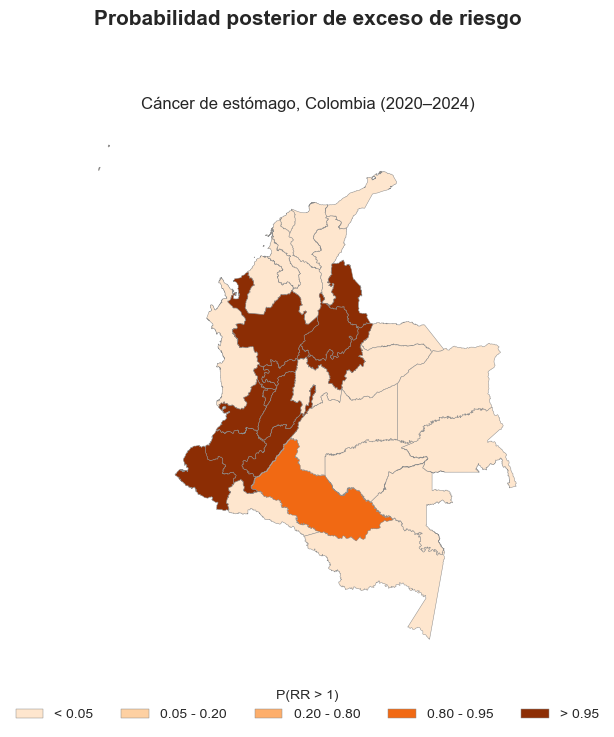

In [144]:
from matplotlib.patches import Patch

colores_prob = {
    "< 0.05": "#fee6ce",
    "0.05 - 0.20": "#fdd0a2",
    "0.20 - 0.80": "#fdae6b",
    "0.80 - 0.95": "#f16913",
    "> 0.95": "#8c2d04"
}

fig, ax = plt.subplots(figsize=(12, 8))

for categoria in labels_prob:
    subset = gdf_rr_posterior[
        gdf_rr_posterior["Probabilidad_exceso"] == categoria
    ]

    if not subset.empty:
        subset.plot(
            ax=ax,
            color=colores_prob[categoria],
            edgecolor="#8c8c8c",
            linewidth=0.35
        )

ax.set_axis_off()
ax.set_aspect("equal")

leyenda = [
    Patch(
        facecolor=colores_prob[categoria],
        edgecolor="#8c8c8c",
        linewidth=0.35,
        label=categoria
    )
    for categoria in labels_prob
]

fig.legend(
    handles=leyenda,
    title="P(RR > 1)",
    loc="lower center",
    ncol=5,
    frameon=False,
    bbox_to_anchor=(0.5, 0.035),
    fontsize=10,
    title_fontsize=10
)

fig.suptitle(
    "Probabilidad posterior de exceso de riesgo",
    fontsize=15,
    fontweight="bold",
    y=0.94
)

ax.set_title(
    "Cáncer de estómago, Colombia (2020–2024)",
    fontsize=12,
    pad=8
)

plt.tight_layout(rect=[0.05, 0.10, 0.95, 0.90])
plt.show()

## 7. Incorporación de covariables al modelo espacial

### 7.1 Índice de Pobreza Multidimensional (IPM)

In [65]:
columnas_ipm = [
    "DPTO_CCDGO",
    "DPTO_CNMBR",
    "MPIO_CCDGO",
    "MPIO_CNMBR",
    "MPM",
    "MPM_CAB",
    "MPM_CPRD"
]

display(ipm_2018[columnas_ipm].head(10))

print("\nTipos de datos:")
print(ipm_2018[columnas_ipm].dtypes)

print("\nDepartamentos:", ipm_2018["DPTO_CCDGO"].nunique())
print("Municipios:", len(ipm_2018))
print("Faltantes en MPM:", ipm_2018["MPM"].isna().sum())

,DPTO_CCDGO,DPTO_CNMBR,MPIO_CCDGO,MPIO_CNMBR,MPM,MPM_CAB,MPM_CPRD
0,18,CAQUETÃ,001,FLORENCIA,29.60,27.20,53.30
1,18,CAQUETÃ,029,ALBANIA,38.80,26.60,48.90
2,18,CAQUETÃ,094,BELÃN DE LOS ANDAQUÃES,50.00,41.40,66.10
3,18,CAQUETÃ,247,EL DONCELLO,44.30,37.60,60.70
4,18,CAQUETÃ,256,EL PAUJÃL,45.50,40.30,53.40
5,18,CAQUETÃ,410,LA MONTAÃITA,56.20,34.90,61.50
6,18,CAQUETÃ,460,MILÃN,64.60,38.10,68.70
7,18,CAQUETÃ,479,MORELIA,42.40,33.60,53.00
8,18,CAQUETÃ,610,SAN JOSÃ DEL FRAGUA,48.70,41.60,57.60
9,18,CAQUETÃ,860,VALPARAÃSO,50.00,35.60,59.10



Tipos de datos:
DPTO_CCDGO     object
DPTO_CNMBR     object
MPIO_CCDGO     object
MPIO_CNMBR     object
MPM           float64
MPM_CAB       float64
MPM_CPRD      float64
dtype: object

Departamentos: 33
Municipios: 1122
Faltantes en MPM: 0


In [66]:
poblacion_2018 = poblacion_mun[
    poblacion_mun["ANO"] == 2018
].copy()

print("Registros población 2018:", len(poblacion_2018))
print("Departamentos:", poblacion_2018["dpto_ccdgo"].nunique())
print("Municipios:", poblacion_2018["DPMP"].nunique())
print("Faltantes población:", poblacion_2018["Total"].isna().sum())

display(poblacion_2018.head())

Registros población 2018: 1123
Departamentos: 33
Municipios: 1040
Faltantes población: 0


,dpto_ccdgo,DPNOM,mpio_cdpmp,DPMP,ANO,Total,Hombres,Mujeres,menor_40,40_44,45_49,50_54,55_59,60_64,65_69,70_74,75_79,80_84,mayor_84
10,5,Antioquia,5001,Medellín,2018,2427133,1141343,1285790,1471498,146356,143656,152416,138677,113591,88912,64995,45755,30731,30546
27,5,Antioquia,5002,Abejorral,2018,20368,10494,9874,11776,1256,1224,1241,1219,1110,892,653,465,299,233
44,5,Antioquia,5004,Abriaquí,2018,2718,1463,1255,1657,159,153,156,143,115,89,77,63,45,61
61,5,Antioquia,5021,Alejandría,2018,4642,2313,2329,2835,247,252,267,258,217,174,134,104,76,78
78,5,Antioquia,5030,Amagá,2018,30230,14850,15380,18398,1829,1871,1961,1793,1449,1070,750,507,321,281


In [67]:
ipm_cruce = ipm_2018[
    ["DPTO_CCDGO", "MPIO_CCDGO", "MPIO_CNMBR", "MPM"]
].copy()

ipm_cruce["codigo_municipio"] = (
    ipm_cruce["DPTO_CCDGO"].astype(str).str.zfill(2)
    + ipm_cruce["MPIO_CCDGO"].astype(str).str.zfill(3)
)

poblacion_cruce = poblacion_2018[
    ["dpto_ccdgo", "mpio_cdpmp", "DPMP", "Total"]
].copy()

poblacion_cruce["codigo_municipio"] = (
    poblacion_cruce["mpio_cdpmp"]
    .astype(int)
    .astype(str)
    .str.zfill(5)
)

comparacion_ipm = ipm_cruce.merge(
    poblacion_cruce,
    on="codigo_municipio",
    how="outer",
    indicator=True
)

print(comparacion_ipm["_merge"].value_counts())

display(
    comparacion_ipm[
        comparacion_ipm["_merge"] != "both"
    ]
)

_merge
both          1122
right_only       1
left_only        0
Name: count, dtype: int64


,DPTO_CCDGO,MPIO_CCDGO,MPIO_CNMBR,MPM,codigo_municipio,dpto_ccdgo,mpio_cdpmp,DPMP,Total,_merge
595,NaN,NaN,NaN,NaN,27493,27,27493,Nuevo Belén de Bajirá,0,right_only


In [68]:
ipm_poblacion = ipm_cruce.merge(
    poblacion_cruce[
        ["codigo_municipio", "Total"]
    ],
    on="codigo_municipio",
    how="left"
)

ipm_poblacion["MPM_ponderado"] = (
    ipm_poblacion["MPM"] * ipm_poblacion["Total"]
)

ipm_departamental_2018 = (
    ipm_poblacion
    .groupby("DPTO_CCDGO", as_index=False)
    .agg(
        Poblacion_2018=("Total", "sum"),
        Suma_MPM_ponderado=("MPM_ponderado", "sum")
    )
)

ipm_departamental_2018["IPM_2018"] = (
    ipm_departamental_2018["Suma_MPM_ponderado"]
    / ipm_departamental_2018["Poblacion_2018"]
)

ipm_departamental_2018 = (
    ipm_departamental_2018[
        ["DPTO_CCDGO", "Poblacion_2018", "IPM_2018"]
    ]
    .merge(
        datos_bym2_ordenados[
            ["dpto_ccdgo", "DPNOM"]
        ],
        left_on="DPTO_CCDGO",
        right_on="dpto_ccdgo",
        how="left"
    )
    [["DPTO_CCDGO", "DPNOM", "Poblacion_2018", "IPM_2018"]]
    .sort_values("IPM_2018", ascending=False)
    .reset_index(drop=True)
)

print("Departamentos:", len(ipm_departamental_2018))
print("Faltantes IPM:", ipm_departamental_2018["IPM_2018"].isna().sum())

display(ipm_departamental_2018)

Departamentos: 33
Faltantes IPM: 0


,DPTO_CCDGO,DPNOM,Poblacion_2018,IPM_2018
0,99,Vichada,107702,80.50
1,97,Vaupés,40774,79.10
2,94,Guainía,48081,75.17
3,27,Chocó,534807,63.62
4,91,Amazonas,76573,60.37
5,44,La Guajira,880552,60.05
6,95,Guaviare,82768,47.49
7,70,Sucre,904850,46.42
8,23,Córdoba,1784754,44.77
9,18,Caquetá,402085,44.23


In [69]:
ipm_modelo = (
    datos_bym2_ordenados[
        ["dpto_ccdgo", "DPNOM"]
    ]
    .merge(
        ipm_departamental_2018[
            ["DPTO_CCDGO", "IPM_2018"]
        ],
        left_on="dpto_ccdgo",
        right_on="DPTO_CCDGO",
        how="left"
    )
    .drop(columns="DPTO_CCDGO")
)

ipm_modelo["IPM_2018_std"] = (
    (ipm_modelo["IPM_2018"] - ipm_modelo["IPM_2018"].mean())
    / ipm_modelo["IPM_2018"].std()
)

print("Departamentos:", len(ipm_modelo))
print("Faltantes:", ipm_modelo["IPM_2018_std"].isna().sum())
print("Media estandarizada:", ipm_modelo["IPM_2018_std"].mean())
print("DE estandarizada:", ipm_modelo["IPM_2018_std"].std())

display(ipm_modelo)

Departamentos: 33
Faltantes: 0
Media estandarizada: -4.306319610667274e-16
DE estandarizada: 1.0


,dpto_ccdgo,DPNOM,IPM_2018,IPM_2018_std
0,05,Antioquia,21.98,-0.84
1,08,Atlántico,22.80,-0.79
2,11,"Bogotá, D.C.",9.00,-1.53
3,13,Bolívar,37.87,0.01
4,15,Boyacá,25.73,-0.64
5,17,Caldas,22.81,-0.79
6,18,Caquetá,44.23,0.35
7,19,Cauca,38.24,0.03
8,20,Cesar,38.51,0.05
9,23,Córdoba,44.77,0.38


In [70]:
datos_modelo_ipm = datos_modelo.copy()

datos_modelo_ipm["X_ipm"] = (
    ipm_modelo["IPM_2018_std"]
    .to_numpy()
    .astype(float)
    .tolist()
)

print("N del modelo:", datos_modelo_ipm["N"])
print("Valores de IPM:", len(datos_modelo_ipm["X_ipm"]))
print("Faltantes:", np.isnan(datos_modelo_ipm["X_ipm"]).sum())
print("Media:", np.mean(datos_modelo_ipm["X_ipm"]))
print("DE:", np.std(datos_modelo_ipm["X_ipm"], ddof=1))

N del modelo: 33
Valores de IPM: 33
Faltantes: 0
Media: -4.306319610667274e-16
DE: 1.0


In [71]:
ruta_modelo_ipm = RUTA_SRC / "bym2_estomago_ipm.stan"

modelo_bym2_ipm = CmdStanModel(
    stan_file=str(ruta_modelo_ipm)
)

print("Modelo BYM2 + IPM compilado correctamente.")

Modelo BYM2 + IPM compilado correctamente.


In [72]:
ajuste_bym2_ipm = modelo_bym2_ipm.sample(
    data=datos_modelo_ipm,
    chains=4,
    parallel_chains=4,
    iter_warmup=1000,
    iter_sampling=1000,
    adapt_delta=0.99,
    max_treedepth=15,
    seed=1234,
    show_progress=True
)

10:37:49 - cmdstanpy - INFO - CmdStan start processing


chain 1 |          | 00:00 Status

chain 2 |          | 00:00 Status

chain 3 |          | 00:00 Status

chain 4 |          | 00:00 Status

10:38:06 - cmdstanpy - INFO - CmdStan done processing.


In [73]:
print(ajuste_bym2_ipm.diagnose())

Processing csv files: C:\Users\USER\AppData\Local\Temp\tmp4l506m7z\bym2_estomago_ipmrvav6jrz\bym2_estomago_ipm-20261026103749_1.csv, C:\Users\USER\AppData\Local\Temp\tmp4l506m7z\bym2_estomago_ipmrvav6jrz\bym2_estomago_ipm-20261026103749_2.csv, C:\Users\USER\AppData\Local\Temp\tmp4l506m7z\bym2_estomago_ipmrvav6jrz\bym2_estomago_ipm-20261026103749_3.csv, C:\Users\USER\AppData\Local\Temp\tmp4l506m7z\bym2_estomago_ipmrvav6jrz\bym2_estomago_ipm-20261026103749_4.csv

Checking sampler transitions treedepth.
Treedepth satisfactory for all transitions.

Checking sampler transitions for divergences.
No divergent transitions found.

Checking E-BFMI - sampler transitions HMC potential energy.
E-BFMI satisfactory.

Effective sample size satisfactory.

Split R-hat values satisfactory all parameters.

Processing complete, no problems detected.



In [74]:
resumen_ipm = ajuste_bym2_ipm.summary()

parametros_ipm = resumen_ipm.loc[
    ["alpha", "beta_ipm", "sigma", "rho"],
    ["Mean", "50%", "StdDev", "5%", "95%", "N_Eff", "R_hat"]
].copy()

parametros_ipm.columns = [
    "Media",
    "Mediana",
    "DE",
    "P5",
    "P95",
    "ESS",
    "R-hat"
]

parametros_ipm = parametros_ipm.round(3)

styled = (
    parametros_ipm
    .reset_index()
    .rename(columns={"index": "Parámetro"})
    .style
    .hide(axis="index")
    .set_table_styles([
        {
            "selector": "table",
            "props": [
                ("margin", "0 auto"),
                ("width", "auto"),
                ("border-collapse", "collapse")
            ]
        },
        {
            "selector": "th",
            "props": [
                ("text-align", "center"),
                ("background-color", "#f2f2f2"),
                ("color", "black"),
                ("font-weight", "bold"),
                ("border", "1px solid black"),
                ("padding", "10px")
            ]
        },
        {
            "selector": "td",
            "props": [
                ("text-align", "center"),
                ("border", "1px solid black"),
                ("padding", "10px")
            ]
        }
    ])
)

display(
    HTML(
        "<div style='text-align: center; width: 100%;'>"
        + styled.to_html()
        + "</div>"
    )
)

Parámetro,Media,Mediana,DE,P5,P95,ESS,R-hat
alpha,-0.507000,-0.504000,0.057000,-0.602000,-0.422000,2558.340000,1.001000
beta_ipm,-0.726000,-0.725000,0.124000,-0.932000,-0.526000,1506.550000,1.003000
sigma,0.560000,0.549000,0.087000,0.437000,0.720000,1278.420000,1.000000
rho,0.788000,0.866000,0.227000,0.294000,0.999000,319.564000,1.018000


El modelo BYM2 con IPM presentó una media posterior de $\alpha=-0.507$. La inclusión del IPM mostró una asociación negativa con el riesgo relativo de mortalidad, con un coeficiente posterior medio de $\beta_{IPM}=-0.726$ y un intervalo creíble del 95% entre $-0.932$ y $-0.526$.

La variabilidad residual global fue $\sigma=0.560$, inferior a la observada en el modelo BYM2 base ($\sigma=0.856$), lo que indica una reducción de la heterogeneidad residual entre departamentos después de incorporar el IPM. Por su parte, $\rho=0.788$ indica que una proporción importante de la varianza residual continúa asociada al componente espacialmente estructurado.

Los diagnósticos mostraron una convergencia adecuada para $\alpha$, $\beta_{IPM}$ y $\sigma$. El parámetro $\rho$ presentó una menor eficiencia de muestreo, con un ESS de 319.56 y $\hat{R}=1.018$, ligeramente superior al observado para los demás parámetros.

In [75]:
beta_ipm_draws = ajuste_bym2_ipm.stan_variable("beta_ipm")

beta_media = beta_ipm_draws.mean()
beta_mediana = np.median(beta_ipm_draws)
beta_li = np.quantile(beta_ipm_draws, 0.025)
beta_ls = np.quantile(beta_ipm_draws, 0.975)

rr_ipm_draws = np.exp(beta_ipm_draws)

rr_media = rr_ipm_draws.mean()
rr_mediana = np.median(rr_ipm_draws)
rr_li = np.quantile(rr_ipm_draws, 0.025)
rr_ls = np.quantile(rr_ipm_draws, 0.975)

prob_beta_negativo = (beta_ipm_draws < 0).mean()

resultado_ipm = pd.DataFrame({
    "Covariable": ["IPM 2018"],
    "Beta medio": [beta_media],
    "Beta mediano": [beta_mediana],
    "IC95% Beta inferior": [beta_li],
    "IC95% Beta superior": [beta_ls],
    "RR medio": [rr_media],
    "RR mediano": [rr_mediana],
    "IC95% RR inferior": [rr_li],
    "IC95% RR superior": [rr_ls],
    "P(Beta < 0)": [prob_beta_negativo]
})

styled = (
    resultado_ipm
    .round(3)
    .style
    .hide(axis="index")
    .set_table_styles([
        {
            "selector": "table",
            "props": [
                ("margin", "0 auto"),
                ("width", "auto"),
                ("border-collapse", "collapse")
            ]
        },
        {
            "selector": "th",
            "props": [
                ("text-align", "center"),
                ("background-color", "#f2f2f2"),
                ("color", "black"),
                ("font-weight", "bold"),
                ("border", "1px solid black"),
                ("padding", "10px")
            ]
        },
        {
            "selector": "td",
            "props": [
                ("text-align", "center"),
                ("border", "1px solid black"),
                ("padding", "10px")
            ]
        }
    ])
    .set_properties(
        subset=["Covariable"],
        **{"text-align": "left"}
    )
)

display(
    HTML(
        "<div style='text-align: center; width: 100%;'>"
        + styled.to_html()
        + "</div>"
    )
)

Covariable,Beta medio,Beta mediano,IC95% Beta inferior,IC95% Beta superior,RR medio,RR mediano,IC95% RR inferior,IC95% RR superior,P(Beta < 0)
IPM 2018,-0.726000,-0.725000,-0.972000,-0.477000,0.488000,0.484000,0.378000,0.621000,1.000000


El Índice de Pobreza Multidimensional utilizado corresponde a la medición censal de 2018 y fue estandarizado antes de incorporarse al modelo. Por tanto, el efecto estimado representa el cambio en el riesgo relativo asociado con un incremento de una desviación estándar del IPM departamental.

El IPM presentó un coeficiente posterior medio de $\beta_{IPM}=-0.726$. En la escala de riesgo relativo, esto corresponde a un RR posterior medio de $0.488$ (IC95%: 0.378–0.621), con una probabilidad posterior de asociación negativa igual a 1.000.

Estos resultados muestran que, dentro del modelo, mayores valores departamentales de IPM se asociaron con menores riesgos relativos de mortalidad por cáncer de estómago durante 2020–2024. Esta asociación es de carácter ecológico y no implica que la pobreza tenga un efecto protector a nivel individual.

In [76]:
import json
from pathlib import Path

RUTA_RESULTADOS = Path("../Resultados")
RUTA_RESULTADOS.mkdir(parents=True, exist_ok=True)

alpha_draws = ajuste_bym2_ipm.stan_variable("alpha")
sigma_draws = ajuste_bym2_ipm.stan_variable("sigma")
rho_draws = ajuste_bym2_ipm.stan_variable("rho")
beta_ipm_draws = ajuste_bym2_ipm.stan_variable("beta_ipm")
rr_draws_ipm = ajuste_bym2_ipm.stan_variable("rr")

def resumen_draws(draws):
    return {
        "media": float(np.mean(draws)),
        "mediana": float(np.median(draws)),
        "sd": float(np.std(draws, ddof=1)),
        "ic95_inferior": float(np.quantile(draws, 0.025)),
        "ic95_superior": float(np.quantile(draws, 0.975))
    }

rr_ipm_draws = np.exp(beta_ipm_draws)

rr_departamentales = []

for i, fila in datos_bym2_ordenados.reset_index(drop=True).iterrows():
    draws = rr_draws_ipm[:, i]

    rr_departamentales.append({
        "dpto_ccdgo": str(fila["dpto_ccdgo"]).zfill(2),
        "departamento": str(fila["DPNOM"]),
        "observadas": int(fila["Observadas"]),
        "esperadas": float(fila["Esperadas"]),
        "smr_crudo": float(fila["SMR"]),
        "rr_media": float(np.mean(draws)),
        "rr_mediana": float(np.median(draws)),
        "rr_sd": float(np.std(draws, ddof=1)),
        "ic95_inferior": float(np.quantile(draws, 0.025)),
        "ic95_superior": float(np.quantile(draws, 0.975)),
        "prob_rr_mayor_1": float(np.mean(draws > 1))
    })

resultado_ipm_json = {
    "modelo": {
        "nombre": "BYM2 + IPM 2018",
        "cancer": "Estómago",
        "periodo_mortalidad": "2020-2024",
        "nivel_geografico": "Departamento",
        "numero_departamentos": int(len(datos_bym2_ordenados))
    },
    "configuracion_mcmc": {
        "cadenas": 4,
        "warmup_por_cadena": 1000,
        "muestras_por_cadena": 1000,
        "draws_posteriores_totales": int(len(beta_ipm_draws)),
        "seed": 1234,
        "adapt_delta": 0.99,
        "max_treedepth": 15
    },
    "parametros_globales": {
        "alpha": resumen_draws(alpha_draws),
        "sigma": resumen_draws(sigma_draws),
        "rho": resumen_draws(rho_draws)
    },
    "covariable": {
        "nombre": "IPM 2018",
        "estandarizada": True,
        "beta": resumen_draws(beta_ipm_draws),
        "probabilidad_beta_negativo": float(
            np.mean(beta_ipm_draws < 0)
        ),
        "riesgo_relativo_por_1_sd": resumen_draws(rr_ipm_draws)
    },
    "riesgo_relativo_departamental": rr_departamentales
}

ruta_json_ipm = (
    RUTA_RESULTADOS
    / "bym2_ipm_2018_estomago.json"
)

with open(
    ruta_json_ipm,
    "w",
    encoding="utf-8"
) as archivo:
    json.dump(
        resultado_ipm_json,
        archivo,
        ensure_ascii=False,
        indent=4
    )

print(f"Resultados guardados en: {ruta_json_ipm.resolve()}")
print(f"Departamentos exportados: {len(rr_departamentales)}")
print(f"Draws posteriores utilizados: {len(beta_ipm_draws)}")

Resultados guardados en: C:\Users\USER\Desktop\Tesis\Priority-cancers-in-Colombia\resultados\bym2_ipm_2018_estomago.json
Departamentos exportados: 33
Draws posteriores utilizados: 4000


### 7.2 Distribución espacial del IPM


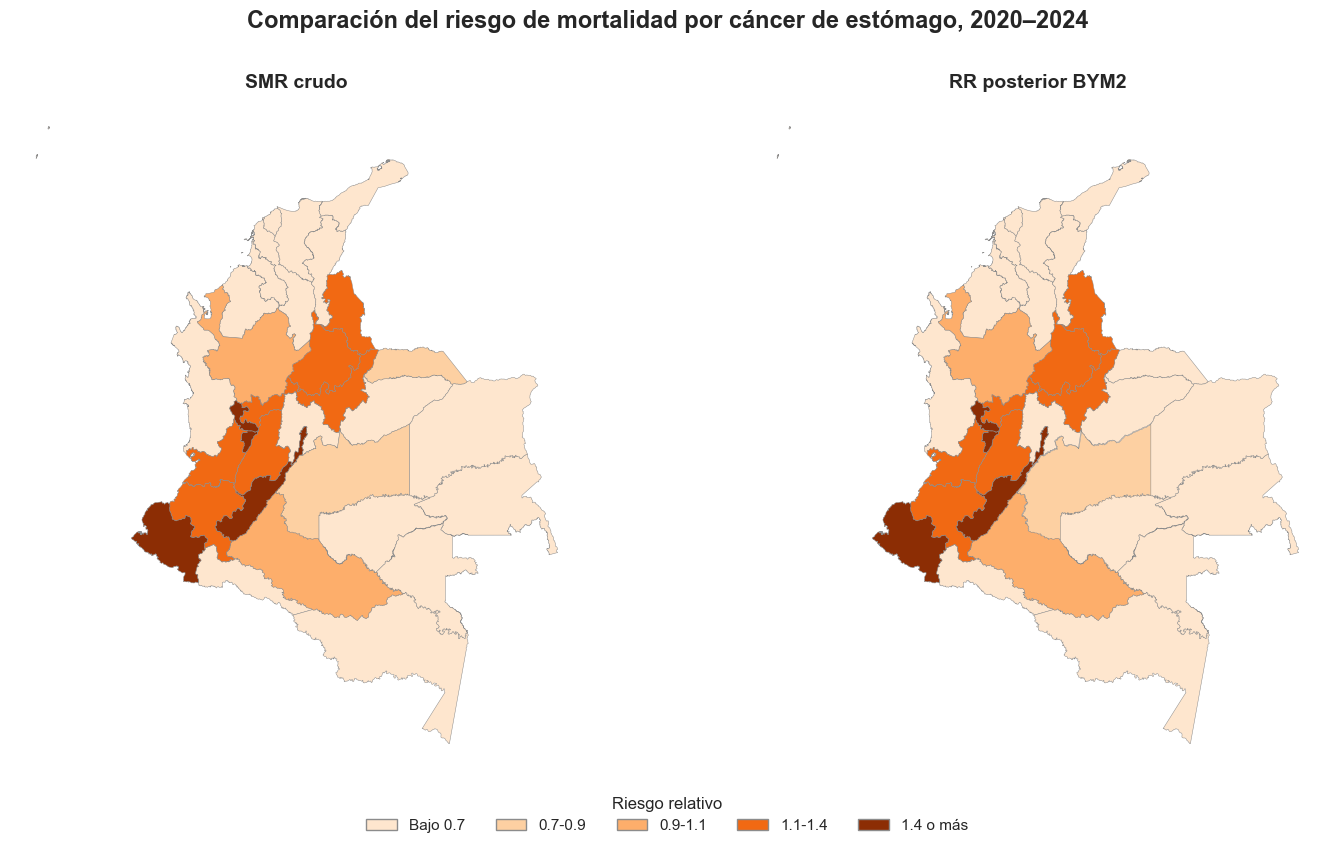

In [77]:
mapa_smr_2020_2024 = gdf_smr_quinquenal[
    gdf_smr_quinquenal["Quinquenio"] == "2020-2024"
].copy()

gdf_rr_2020_2024 = gdf_departamentos.merge(
    resultados_rr[
        ["dpto_ccdgo", "RR_media"]
    ],
    left_on="DPTO_CCDGO",
    right_on="dpto_ccdgo",
    how="left"
)

gdf_rr_2020_2024["Categoria_RR"] = pd.cut(
    gdf_rr_2020_2024["RR_media"],
    bins=[-np.inf, 0.7, 0.9, 1.1, 1.4, np.inf],
    labels=[
        "RR < 0.7",
        "0.7 ≤ RR < 0.9",
        "0.9 ≤ RR < 1.1",
        "1.1 ≤ RR < 1.4",
        "RR ≥ 1.4"
    ],
    right=False
)

colores_comparacion = {
    "Bajo 0.7": "#fee6ce",
    "0.7-0.9": "#fdd0a2",
    "0.9-1.1": "#fdae6b",
    "1.1-1.4": "#f16913",
    "1.4 o más": "#8c2d04"
}

mapa_smr_2020_2024["Categoria_comparacion"] = pd.cut(
    mapa_smr_2020_2024["SMR"],
    bins=[-np.inf, 0.7, 0.9, 1.1, 1.4, np.inf],
    labels=list(colores_comparacion.keys()),
    right=False
)

gdf_rr_2020_2024["Categoria_comparacion"] = pd.cut(
    gdf_rr_2020_2024["RR_media"],
    bins=[-np.inf, 0.7, 0.9, 1.1, 1.4, np.inf],
    labels=list(colores_comparacion.keys()),
    right=False
)

fig, axes = plt.subplots(
    1,
    2,
    figsize=(15, 9)
)

for categoria, color in colores_comparacion.items():
    subset_smr = mapa_smr_2020_2024[
        mapa_smr_2020_2024["Categoria_comparacion"] == categoria
    ]

    if not subset_smr.empty:
        subset_smr.plot(
            ax=axes[0],
            color=color,
            edgecolor="#8c8c8c",
            linewidth=0.35,
            aspect=1
        )

    subset_rr = gdf_rr_2020_2024[
        gdf_rr_2020_2024["Categoria_comparacion"] == categoria
    ]

    if not subset_rr.empty:
        subset_rr.plot(
            ax=axes[1],
            color=color,
            edgecolor="#8c8c8c",
            linewidth=0.35,
            aspect=1
        )

axes[0].set_title(
    "SMR crudo",
    fontsize=14,
    fontweight="bold"
)

axes[1].set_title(
    "RR posterior BYM2",
    fontsize=14,
    fontweight="bold"
)

for ax in axes:
    ax.axis("off")

leyenda = [
    Patch(
        facecolor=color,
        edgecolor="#8c8c8c",
        label=categoria
    )
    for categoria, color in colores_comparacion.items()
]

fig.legend(
    handles=leyenda,
    title="Riesgo relativo",
    loc="lower center",
    bbox_to_anchor=(0.5, 0.03),
    ncol=5,
    frameon=False
)

fig.suptitle(
    "Comparación del riesgo de mortalidad por cáncer de estómago, 2020–2024",
    fontsize=17,
    fontweight="bold",
    y=0.96
)

plt.tight_layout(rect=[0, 0.09, 1, 0.93])
plt.show()

La distribución espacial del riesgo posterior estimado mediante el modelo BYM2 conserva, en términos generales, el patrón observado en el SMR crudo. Las principales zonas de exceso de riesgo permanecen concentradas en los mismos departamentos, mientras que las diferencias entre ambas estimaciones se presentan principalmente en territorios con menor información disponible.

Esta similitud indica que, para la mayoría de los departamentos, los datos observados aportan suficiente información para que el riesgo posterior permanezca cercano al SMR. El efecto de suavizamiento del modelo BYM2 es más evidente en departamentos con pocos eventos, donde las estimaciones extremas se desplazan hacia valores menos pronunciados. Por tanto, el propósito del modelo no es modificar artificialmente el patrón espacial observado, sino incorporar la estructura de vecindad y la incertidumbre asociada a cada estimación.

In [78]:
comparacion_smr_bym2 = (
    smr_departamento_quinquenal[
        smr_departamento_quinquenal["Quinquenio"] == "2020-2024"
    ][["dpto_ccdgo", "DPNOM", "SMR"]]
    .merge(
        resultados_rr[
            ["dpto_ccdgo", "RR_media"]
        ],
        on="dpto_ccdgo",
        how="inner"
    )
)

comparacion_smr_bym2["Diferencia"] = (
    comparacion_smr_bym2["RR_media"]
    - comparacion_smr_bym2["SMR"]
)

comparacion_smr_bym2["Cambio_absoluto"] = (
    comparacion_smr_bym2["Diferencia"].abs()
)

comparacion_smr_bym2 = (
    comparacion_smr_bym2
    .sort_values("Cambio_absoluto", ascending=False)
    .reset_index(drop=True)
)

styled_comparacion = (
    comparacion_smr_bym2
    .style
    .hide(axis="index")
    .format({
        "SMR": "{:.3f}",
        "RR_media": "{:.3f}",
        "Diferencia": "{:+.3f}",
        "Cambio_absoluto": "{:.3f}"
    })
    .set_table_styles([
        {
            "selector": "table",
            "props": [
                ("margin", "auto"),
                ("width", "auto"),
                ("border-collapse", "collapse")
            ]
        },
        {
            "selector": "th",
            "props": [
                ("text-align", "center"),
                ("background-color", "#f2f2f2"),
                ("color", "black"),
                ("font-weight", "bold"),
                ("border", "1px solid black"),
                ("padding", "10px")
            ]
        },
        {
            "selector": "td",
            "props": [
                ("text-align", "center"),
                ("border", "1px solid black"),
                ("padding", "10px")
            ]
        }
    ])
    .set_properties(
        subset=["DPNOM"],
        **{"text-align": "left"}
    )
)

display(
    HTML(
        "<div style='text-align: center; width: 100%;'>"
        + styled_comparacion.to_html()
        + "</div>"
    )
)

dpto_ccdgo,DPNOM,SMR,RR_media,Diferencia,Cambio_absoluto
97,Vaupés,0.045,0.125,+0.079,0.079
94,Guainía,0.000,0.069,+0.069,0.069
99,Vichada,0.104,0.144,+0.040,0.040
95,Guaviare,0.488,0.455,-0.033,0.033
91,Amazonas,0.167,0.197,+0.030,0.030
88,"Archipiélago de San Andrés, Providencia y Santa Catalina",0.187,0.208,+0.021,0.021
27,Chocó,0.150,0.161,+0.011,0.011
18,Caquetá,1.092,1.082,-0.010,0.010
81,Arauca,0.704,0.698,-0.006,0.006
66,Risaralda,1.898,1.895,-0.004,0.004


La comparación entre el SMR observado y el riesgo relativo posterior muestra que el efecto de suavizamiento del modelo BYM2 se concentra principalmente en los departamentos con estimaciones más extremas y menor información. Vaupés presenta el mayor cambio absoluto, al pasar de un SMR de 0.045 a un RR posterior de 0.126, seguido de Guainía (0.000 a 0.068) y Vichada (0.104 a 0.143). También se observan ajustes en Guaviare, Amazonas y San Andrés.

Los departamentos con mayor número de eventos presentan diferencias mínimas entre ambas estimaciones. Risaralda, Huila, Quindío, Nariño y Bogotá conservan prácticamente sus valores originales, por lo que el patrón de exceso de riesgo identificado mediante el SMR permanece después del ajuste bayesiano. Estos resultados muestran que el BYM2 introduce mayor regularización donde la información es más limitada, mientras que conserva las estimaciones en los departamentos donde los datos proporcionan mayor evidencia.

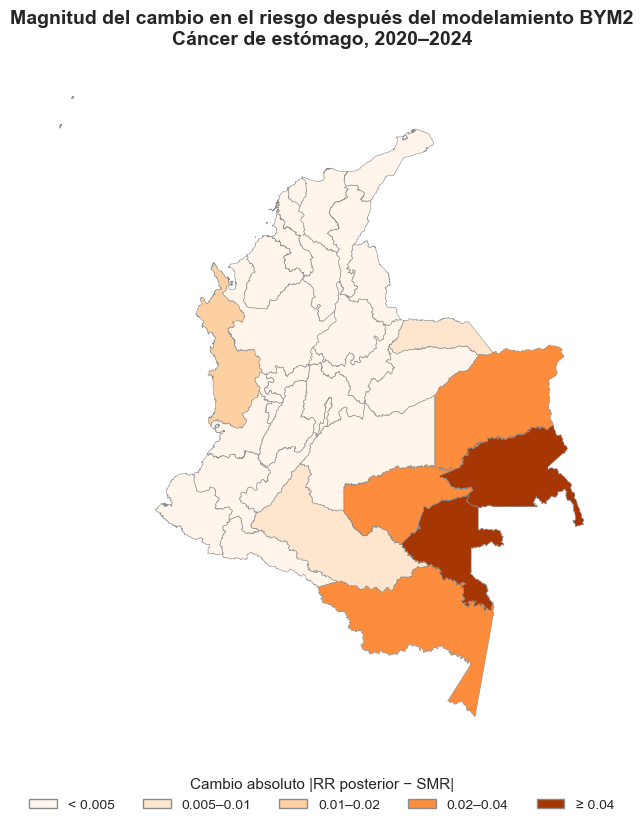

In [79]:
comparacion_mapa = gdf_departamentos.merge(
    comparacion_smr_bym2[
        ["dpto_ccdgo", "DPNOM", "SMR", "RR_media", "Diferencia"]
    ],
    left_on="DPTO_CCDGO",
    right_on="dpto_ccdgo",
    how="left"
)

comparacion_mapa["Cambio_absoluto"] = comparacion_mapa["Diferencia"].abs()

comparacion_mapa["Categoria_cambio"] = pd.cut(
    comparacion_mapa["Cambio_absoluto"],
    bins=[-np.inf, 0.005, 0.01, 0.02, 0.04, np.inf],
    labels=[
        "< 0.005",
        "0.005–0.01",
        "0.01–0.02",
        "0.02–0.04",
        "≥ 0.04"
    ],
    right=False
)

colores_cambio = {
    "< 0.005": "#fff5eb",
    "0.005–0.01": "#fee6ce",
    "0.01–0.02": "#fdd0a2",
    "0.02–0.04": "#fd8d3c",
    "≥ 0.04": "#a63603"
}

orden_cambio = [
    "< 0.005",
    "0.005–0.01",
    "0.01–0.02",
    "0.02–0.04",
    "≥ 0.04"
]

fig, ax = plt.subplots(
    1,
    1,
    figsize=(9, 9)
)

for categoria, color in colores_cambio.items():
    subset = comparacion_mapa[
        comparacion_mapa["Categoria_cambio"] == categoria
    ]

    if not subset.empty:
        subset.plot(
            ax=ax,
            color=color,
            edgecolor="#8c8c8c",
            linewidth=0.4,
            aspect=1
        )

leyenda = [
    Patch(
        facecolor=colores_cambio[categoria],
        edgecolor="#8c8c8c",
        label=categoria
    )
    for categoria in orden_cambio
]

fig.legend(
    handles=leyenda,
    title="Cambio absoluto |RR posterior − SMR|",
    loc="lower center",
    bbox_to_anchor=(0.5, 0.035),
    ncol=5,
    frameon=False,
    fontsize=10,
    title_fontsize=11
)

ax.set_title(
    "Magnitud del cambio en el riesgo después del modelamiento BYM2\nCáncer de estómago, 2020–2024",
    fontsize=14,
    fontweight="bold",
    pad=15
)

ax.axis("off")

plt.tight_layout(rect=[0, 0.10, 1, 0.96])
plt.show()

La magnitud del cambio confirma que el efecto del modelamiento BYM2 no es homogéneo en el territorio. Los mayores ajustes se concentran principalmente en departamentos del oriente y suroriente del país, especialmente Guainía, Vaupés y Vichada, donde la diferencia absoluta entre el SMR y el riesgo posterior supera 0.04. En la mayor parte del territorio, por el contrario, las diferencias son inferiores a 0.005.

Este patrón muestra que el suavizamiento bayesiano tiene mayor influencia en las áreas donde las estimaciones observadas son más inestables, mientras que en los departamentos con mayor información el riesgo posterior permanece prácticamente igual al SMR. Por esta razón, aunque los mapas de SMR y RR posterior presentan una distribución visualmente similar, el efecto del modelo se concentra en un grupo específico de departamentos.

## 8. Modelo Nulo

Con el objetivo de evaluar si la incorporación de la estructura espacial aporta información relevante al análisis del riesgo de mortalidad, se plantea un modelo nulo como referencia para la comparación con el modelo BYM2. Este modelo conserva la misma distribución de Poisson y los mismos valores observados y esperados, pero asume un único riesgo relativo común para todos los departamentos, sin incorporar efectos espaciales estructurados ni no estructurados.

De esta forma, el modelo nulo representa un escenario base en el que no se consideran diferencias espaciales en el riesgo. Su comparación con el BYM2 permite evaluar si la inclusión de la heterogeneidad departamental y la estructura de vecindad proporciona una mejora en el ajuste del modelo.

In [80]:
datos_modelo_nulo = {
    "N": datos_modelo["N"],
    "Y": datos_modelo["Y"],
    "E": datos_modelo["E"]
}

print("N:", datos_modelo_nulo["N"])
print("Observadas:", sum(datos_modelo_nulo["Y"]))
print("Esperadas:", round(sum(datos_modelo_nulo["E"]), 6))

N: 33
Observadas: 26418
Esperadas: 26418.0


In [81]:
modelo_nulo = CmdStanModel(
    stan_file=r"C:\Users\USER\Desktop\Tesis\src\modelo_nulo_estomago.stan"
)

ajuste_nulo = modelo_nulo.sample(
    data=datos_modelo_nulo,
    chains=4,
    parallel_chains=4,
    iter_warmup=1000,
    iter_sampling=1000,
    seed=1234,
    adapt_delta=0.99,
    max_treedepth=15,
    show_progress=True
)

10:38:16 - cmdstanpy - INFO - CmdStan start processing


chain 1 |          | 00:00 Status

chain 2 |          | 00:00 Status

chain 3 |          | 00:00 Status

chain 4 |          | 00:00 Status

10:38:16 - cmdstanpy - INFO - CmdStan done processing.


In [82]:
modelo_bym2_loo = CmdStanModel(
    stan_file=r"C:\Users\USER\Desktop\Tesis\src\bym2_estomago_loo.stan"
)

In [83]:
ajuste_bym2_loo = modelo_bym2_loo.sample(
    data=datos_modelo,
    chains=4,
    parallel_chains=4,
    iter_warmup=1000,
    iter_sampling=1000,
    seed=1234,
    adapt_delta=0.99,
    max_treedepth=15,
    show_progress=True
)

10:38:16 - cmdstanpy - INFO - CmdStan start processing


chain 1 |          | 00:00 Status

chain 2 |          | 00:00 Status

chain 3 |          | 00:00 Status

chain 4 |          | 00:00 Status

10:38:32 - cmdstanpy - INFO - CmdStan done processing.


In [84]:
print(ajuste_bym2_loo.stan_variables().keys())

resumen_bym2_loo = ajuste_bym2_loo.summary()

resumen_bym2_loo.loc[
    ["alpha", "sigma", "rho"],
    ["Mean", "50%", "StdDev", "N_Eff", "R_hat"]
].rename(
    columns={
        "50%": "Median",
        "N_Eff": "ESS"
    }
)

dict_keys(['alpha', 'sigma', 'rho', 'phi_conn', 'phi_island', 'delta', 'phi', 'efecto_espacial', 'log_rr', 'rr', 'log_lik'])


,Mean,Median,StdDev,ESS,R_hat
alpha,-0.52,-0.51,0.06,"2,769.20",1.00
sigma,0.86,0.84,0.13,896.99,1.00
rho,0.90,0.95,0.13,337.32,1.01


In [85]:
log_lik_nulo = ajuste_nulo.stan_variable("log_lik")
log_lik_bym2 = ajuste_bym2_loo.stan_variable("log_lik")

print("Nulo:", log_lik_nulo.shape)
print("BYM2:", log_lik_bym2.shape)

print("\nValores finitos:")
print("Nulo:", np.isfinite(log_lik_nulo).all())
print("BYM2:", np.isfinite(log_lik_bym2).all())

Nulo: (4000, 33)
BYM2: (4000, 33)

Valores finitos:
Nulo: True
BYM2: True


In [86]:
from scipy.special import logsumexp

def calcular_waic(log_lik):
    n_draws = log_lik.shape[0]

    lppd_i = logsumexp(log_lik, axis=0) - np.log(n_draws)
    p_waic_i = np.var(log_lik, axis=0, ddof=1)

    elpd_waic_i = lppd_i - p_waic_i

    elpd_waic = np.sum(elpd_waic_i)
    p_waic = np.sum(p_waic_i)
    waic = -2 * elpd_waic

    return {
        "WAIC": waic,
        "ELPD_WAIC": elpd_waic,
        "p_WAIC": p_waic,
        "ELPD_i": elpd_waic_i
    }

waic_nulo = calcular_waic(log_lik_nulo)
waic_bym2 = calcular_waic(log_lik_bym2)

diferencia_elpd_i = (
    waic_bym2["ELPD_i"]
    - waic_nulo["ELPD_i"]
)

diferencia_elpd = np.sum(diferencia_elpd_i)
se_diferencia = np.sqrt(
    len(diferencia_elpd_i)
    * np.var(diferencia_elpd_i, ddof=1)
)

comparacion_waic = pd.DataFrame({
    "Modelo": ["Nulo", "BYM2"],
    "WAIC": [
        waic_nulo["WAIC"],
        waic_bym2["WAIC"]
    ],
    "ELPD_WAIC": [
        waic_nulo["ELPD_WAIC"],
        waic_bym2["ELPD_WAIC"]
    ],
    "p_WAIC": [
        waic_nulo["p_WAIC"],
        waic_bym2["p_WAIC"]
    ]
})

comparacion_waic["ΔWAIC vs mejor"] = (
    comparacion_waic["WAIC"]
    - comparacion_waic["WAIC"].min()
)

styled_waic = (
    comparacion_waic
    .style
    .hide(axis="index")
    .format({
        "WAIC": "{:.2f}",
        "ELPD_WAIC": "{:.2f}",
        "p_WAIC": "{:.2f}",
        "ΔWAIC vs mejor": "{:.2f}"
    })
    .set_table_styles([
        {
            "selector": "table",
            "props": [
                ("margin", "auto"),
                ("width", "auto"),
                ("border-collapse", "collapse")
            ]
        },
        {
            "selector": "th",
            "props": [
                ("text-align", "center"),
                ("background-color", "#f2f2f2"),
                ("color", "black"),
                ("font-weight", "bold"),
                ("border", "1px solid black"),
                ("padding", "10px")
            ]
        },
        {
            "selector": "td",
            "props": [
                ("text-align", "center"),
                ("border", "1px solid black"),
                ("padding", "10px")
            ]
        }
    ])
    .set_properties(
        subset=["Modelo"],
        **{"text-align": "left"}
    )
)

display(
    HTML(
        "<div style='text-align: center; width: 100%;'>"
        + styled_waic.to_html()
        + "</div>"
    )
)

print(f"Diferencia ELPD (BYM2 - Nulo): {diferencia_elpd:.2f}")
print(f"Error estándar de la diferencia: {se_diferencia:.2f}")

Modelo,WAIC,ELPD_WAIC,p_WAIC,ΔWAIC vs mejor
Nulo,6057.50,-3028.75,237.53,5758.49
BYM2,299.01,-149.50,17.91,0.00


Diferencia ELPD (BYM2 - Nulo): 2879.24
Error estándar de la diferencia: 596.29


El modelo BYM2 presenta un WAIC considerablemente menor que el modelo nulo (299.03 frente a 6057.50), acompañado de un ELPD_WAIC superior. La diferencia de ELPD a favor del BYM2 es de 2879.24, con un error estándar de 596.30, lo que evidencia una mejora sustancial en el ajuste al incorporar la heterogeneidad espacial entre departamentos. No obstante, estos resultados deben complementarse con el diagnóstico de las contribuciones individuales al WAIC antes de establecer conclusiones sobre el desempeño predictivo del modelo.

In [88]:
resumen_diagnostico_waic = pd.DataFrame({
    "Modelo": ["Nulo", "BYM2"],
    "Departamentos con p_WAIC_i > 0.4": [
        (p_waic_i_nulo > 0.4).sum(),
        (p_waic_i_bym2 > 0.4).sum()
    ],
    "Máximo p_WAIC_i": [
        p_waic_i_nulo.max(),
        p_waic_i_bym2.max()
    ],
    "p_WAIC total": [
        p_waic_i_nulo.sum(),
        p_waic_i_bym2.sum()
    ]
})

styled_resumen = (
    resumen_diagnostico_waic
    .style
    .hide(axis="index")
    .format({
        "Máximo p_WAIC_i": "{:.3f}",
        "p_WAIC total": "{:.2f}"
    })
    .set_table_styles([
        {
            "selector": "table",
            "props": [
                ("margin", "auto"),
                ("width", "auto"),
                ("border-collapse", "collapse")
            ]
        },
        {
            "selector": "th",
            "props": [
                ("text-align", "center"),
                ("background-color", "#f2f2f2"),
                ("color", "black"),
                ("font-weight", "bold"),
                ("border", "1px solid black"),
                ("padding", "10px")
            ]
        },
        {
            "selector": "td",
            "props": [
                ("text-align", "center"),
                ("border", "1px solid black"),
                ("padding", "10px")
            ]
        }
    ])
    .set_properties(
        subset=["Modelo"],
        **{"text-align": "left"}
    )
)

display(
    HTML(
        "<div style='text-align: center; width: 100%;'>"
        + styled_resumen.to_html()
        + "</div>"
    )
)

Modelo,Departamentos con p_WAIC_i > 0.4,Máximo p_WAIC_i,p_WAIC total
Nulo,22,111.234,237.53
BYM2,33,1.201,17.91


La comparación mediante WAIC muestra una reducción sustancial del criterio de información para el modelo BYM2 respecto al modelo nulo. Sin embargo, el análisis de las contribuciones individuales a $p_{\mathrm{WAIC}}$ evidencia valores elevados en algunas unidades, particularmente en departamentos con menor información. Por esta razón, la comparación se utiliza como evidencia complementaria del mejor ajuste del modelo espacial y no como único criterio para establecer su desempeño predictivo.

## 9. Índice de Pobreza Multidimensional (IPM) 2018-2024

### 9.1 Preparación de la covariable

Para complementar el análisis realizado previamente con el IPM censal de 2018, se incorpora una segunda fuente de información sobre pobreza multidimensional con cobertura anual entre 2018 y 2024. A diferencia de la fuente censal utilizada anteriormente, esta base se encuentra a nivel de microdatos e incluye información sobre las privaciones de los hogares, su clasificación de pobreza multidimensional y los factores de expansión correspondientes.

Debido a que el modelo espacial analiza la mortalidad acumulada durante 2020–2024 a nivel departamental, la base requiere un proceso previo de preparación y agregación que permita obtener una medida de pobreza multidimensional representativa del mismo periodo y nivel geográfico.

In [89]:
ipm_2018_2024 = ipm_2018_2024.rename(
    columns={"AÃ\x91O": "AÑO"}
)

for col in ["ipm", "fex_c", "fexp"]:
    ipm_2018_2024[col] = pd.to_numeric(
        ipm_2018_2024[col]
        .astype(str)
        .str.replace(",", ".", regex=False),
        errors="coerce"
    )

ipm_2018_2024["fexp_estimado"] = (
    ipm_2018_2024["fex_c"]
    * ipm_2018_2024["personas"]
)

correlacion_factores = (
    ipm_2018_2024[
        ["fexp", "fexp_estimado"]
    ]
    .corr()
    .iloc[0, 1]
)

diferencia_maxima = (
    ipm_2018_2024["fexp"]
    - ipm_2018_2024["fexp_estimado"]
).abs().max()

resumen_preparacion_ipm = pd.DataFrame({
    "Indicador": [
        "Registros",
        "Años disponibles",
        "Departamentos",
        "Faltantes en pobre",
        "Faltantes en fexp",
        "Correlación fexp y fex_c × personas",
        "Diferencia máxima"
    ],
    "Resultado": [
        len(ipm_2018_2024),
        ipm_2018_2024["AÑO"].nunique(),
        ipm_2018_2024["DEPARTAMENTO"].nunique(),
        ipm_2018_2024["pobre"].isna().sum(),
        ipm_2018_2024["fexp"].isna().sum(),
        correlacion_factores,
        diferencia_maxima
    ]
})

styled_preparacion_ipm = (
    resumen_preparacion_ipm
    .style
    .hide(axis="index")
    .format({"Resultado": "{:.4f}"})
    .set_table_styles([
        {
            "selector": "table",
            "props": [
                ("margin-left", "auto"),
                ("margin-right", "auto"),
                ("width", "auto"),
                ("border-collapse", "collapse")
            ]
        },
        {
            "selector": "th",
            "props": [
                ("text-align", "center"),
                ("background-color", "#f2f2f2"),
                ("color", "black"),
                ("font-weight", "bold"),
                ("border", "1px solid black"),
                ("padding", "10px")
            ]
        },
        {
            "selector": "td",
            "props": [
                ("text-align", "center"),
                ("border", "1px solid black"),
                ("padding", "10px")
            ]
        }
    ])
    .set_properties(
        subset=["Indicador"],
        **{"text-align": "left"}
    )
)

display(
    HTML(
        "<div style='text-align: center; width: 100%;'>"
        + styled_preparacion_ipm.to_html()
        + "</div>"
    )
)

Indicador,Resultado
Registros,621148.0000
Años disponibles,7.0000
Departamentos,33.0000
Faltantes en pobre,0.0000
Faltantes en fexp,0.0000
Correlación fexp y fex_c × personas,1.0000
Diferencia máxima,0.0010


#### 9.1.1 Estimación departamental anual del IPM

A partir de los microdatos se estima la incidencia departamental de pobreza multidimensional para cada año. Para ello, se utiliza la clasificación de pobreza multidimensional de cada hogar y el factor de expansión poblacional, de manera que cada registro contribuya al indicador de acuerdo con la población que representa.

Para cada departamento $d$ y año $t$, el indicador se calcula como:

$$
IPM_{dt} =
\frac{\sum_h pobre_h \times fexp_h}
{\sum_h fexp_h}
\times 100
$$

donde $pobre_h$ toma el valor de 1 cuando el hogar se encuentra clasificado como multidimensionalmente pobre y 0 en caso contrario, mientras que $fexp_h$ corresponde al factor de expansión poblacional del registro.

In [90]:
ipm_departamental_anual = (
    ipm_2018_2024
    .assign(
        poblacion_pobre=lambda x: x["pobre"] * x["fexp"]
    )
    .groupby(
        ["AÑO", "DEPARTAMENTO"],
        as_index=False
    )
    .agg(
        poblacion_expandida=("fexp", "sum"),
        poblacion_pobre=("poblacion_pobre", "sum")
    )
)

ipm_departamental_anual["IPM"] = (
    ipm_departamental_anual["poblacion_pobre"]
    / ipm_departamental_anual["poblacion_expandida"]
    * 100
)

resumen_ipm_anual = (
    ipm_departamental_anual
    .groupby("AÑO")["IPM"]
    .agg(
        Departamentos="count",
        Media="mean",
        Mediana="median",
        Mínimo="min",
        Máximo="max"
    )
    .reset_index()
)

styled_resumen_ipm_anual = (
    resumen_ipm_anual
    .style
    .hide(axis="index")
    .format({
        "AÑO": "{:.0f}",
        "Departamentos": "{:.0f}",
        "Media": "{:.2f}",
        "Mediana": "{:.2f}",
        "Mínimo": "{:.2f}",
        "Máximo": "{:.2f}"
    })
    .set_table_styles([
        {
            "selector": "table",
            "props": [
                ("margin-left", "auto"),
                ("margin-right", "auto"),
                ("width", "auto"),
                ("border-collapse", "collapse")
            ]
        },
        {
            "selector": "th",
            "props": [
                ("text-align", "center"),
                ("background-color", "#f2f2f2"),
                ("color", "black"),
                ("font-weight", "bold"),
                ("border", "1px solid black"),
                ("padding", "10px")
            ]
        },
        {
            "selector": "td",
            "props": [
                ("text-align", "center"),
                ("border", "1px solid black"),
                ("padding", "10px")
            ]
        }
    ])
)

display(
    HTML(
        "<div style='text-align: center; width: 100%;'>"
        + styled_resumen_ipm_anual.to_html()
        + "</div>"
    )
)

AÑO,Departamentos,Media,Mediana,Mínimo,Máximo
2018,33,28.20,28.67,4.37,64.97
2019,33,26.12,23.31,7.09,72.21
2020,33,27.67,26.08,7.54,75.63
2021,33,23.71,22.08,5.73,64.82
2022,33,20.75,18.26,3.81,75.40
2023,33,20.04,15.85,3.59,65.38
2024,33,17.69,13.36,5.39,70.21


#### 9.1.2 Evolución del IPM durante 2020–2024

Antes de construir una medida única para el periodo de análisis, se examina la evolución anual del IPM departamental entre 2020 y 2024. Esta revisión permite identificar la variabilidad temporal de la covariable y evaluar si el uso de un único año sería representativo del quinquenio analizado.

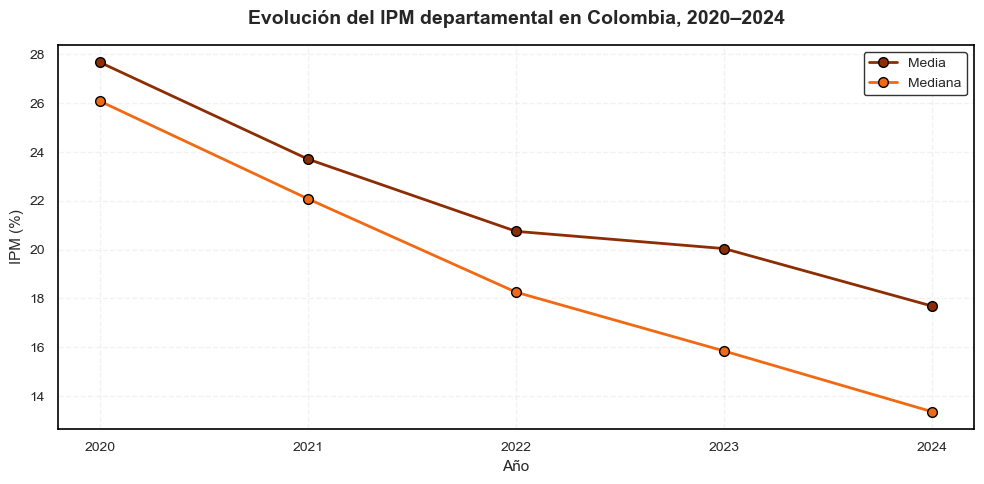

In [163]:
ipm_quinquenio_anual = (
    ipm_departamental_anual[
        ipm_departamental_anual["AÑO"].between(2020, 2024)
    ]
    .groupby("AÑO")["IPM"]
    .agg(
        Media="mean",
        Mediana="median"
    )
    .reset_index()
)

fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(
    ipm_quinquenio_anual["AÑO"],
    ipm_quinquenio_anual["Media"],
    marker="o",
    markersize=7,
    markeredgecolor="black",
    markeredgewidth=1,
    color="#8c2d04",
    linewidth=2,
    label="Media",
    zorder=3
)

ax.plot(
    ipm_quinquenio_anual["AÑO"],
    ipm_quinquenio_anual["Mediana"],
    marker="o",
    markersize=7,
    markeredgecolor="black",
    markeredgewidth=1,
    color="#f16913",
    linewidth=2,
    label="Mediana",
    zorder=3
)

ax.set_title(
    "Evolución del IPM departamental en Colombia, 2020–2024",
    fontsize=14,
    fontweight="bold",
    pad=15
)

ax.set_xlabel(
    "Año",
    fontsize=11
)

ax.set_ylabel(
    "IPM (%)",
    fontsize=11
)

ax.set_xticks(range(2020, 2025))

ax.legend(
    frameon=True,
    edgecolor="black",
    fontsize=10
)

ax.grid(
    axis="both",
    linestyle="--",
    alpha=0.25,
    zorder=1
)

for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_color("black")
    spine.set_linewidth(1.2)

ax.tick_params(
    axis="both",
    labelsize=10,
    color="black"
)

plt.tight_layout()
plt.show()

Entre 2020 y 2024 se observa una reducción progresiva del IPM departamental. La media disminuye de 27.67% en 2020 a 17.69% en 2024, mientras que la mediana pasa de 26.08% a 13.36%. La disminución sostenida de ambas medidas evidencia que la pobreza multidimensional presenta una variación temporal importante durante el quinquenio analizado.

En consecuencia, utilizar únicamente el IPM de un año específico no representaría adecuadamente las condiciones observadas durante todo el periodo 2020–2024. Por esta razón, se construye posteriormente una medida departamental que sintetiza las estimaciones anuales del IPM durante los cinco años.

#### 9.1.3 IPM departamental para el periodo 2020–2024

Para obtener una medida representativa del periodo analizado, se calcula para cada departamento el promedio de sus estimaciones anuales del IPM entre 2020 y 2024. De esta manera, cada año contribuye de forma equivalente a la medida final y se evita representar todo el quinquenio mediante las condiciones observadas en un único momento.

$$
IPM_{d,2020-2024}
=\frac{1}{5}
\sum_{t=2020}^{2024} IPM_{dt}
$$

In [167]:
ipm_departamental_2020_2024 = (
    ipm_departamental_anual[
        ipm_departamental_anual["AÑO"].between(2020, 2024)
    ]
    .groupby("DEPARTAMENTO", as_index=False)
    .agg(
        IPM_2020_2024=("IPM", "mean"),
        Años_disponibles=("AÑO", "nunique")
    )
)

ipm_departamental_2020_2024["dpto_ccdgo"] = (
    ipm_departamental_2020_2024["DEPARTAMENTO"]
    .astype(str)
    .str.zfill(2)
)

nombres_departamentos_ipm = {
    "05": "Antioquia",
    "08": "Atlántico",
    "11": "Bogotá",
    "13": "Bolívar",
    "15": "Boyacá",
    "17": "Caldas",
    "18": "Caquetá",
    "19": "Cauca",
    "20": "Cesar",
    "23": "Córdoba",
    "25": "Cundinamarca",
    "27": "Chocó",
    "41": "Huila",
    "44": "La Guajira",
    "47": "Magdalena",
    "50": "Meta",
    "52": "Nariño",
    "54": "Norte de Santander",
    "63": "Quindío",
    "66": "Risaralda",
    "68": "Santander",
    "70": "Sucre",
    "73": "Tolima",
    "76": "Valle del Cauca",
    "81": "Arauca",
    "85": "Casanare",
    "86": "Putumayo",
    "88": "San Andrés y Providencia",
    "91": "Amazonas",
    "94": "Guainía",
    "95": "Guaviare",
    "97": "Vaupés",
    "99": "Vichada"
}

ipm_departamental_2020_2024["DEPARTAMENTO_NOMBRE"] = (
    ipm_departamental_2020_2024["dpto_ccdgo"]
    .map(nombres_departamentos_ipm)
)

ipm_departamental_2020_2024 = (
    ipm_departamental_2020_2024[
        [
            "dpto_ccdgo",
            "DEPARTAMENTO_NOMBRE",
            "Años_disponibles",
            "IPM_2020_2024"
        ]
    ]
    .sort_values(
        "IPM_2020_2024",
        ascending=False
    )
    .reset_index(drop=True)
)

styled_ipm_2020_2024 = (
    ipm_departamental_2020_2024
    .style
    .hide(axis="index")
    .format({
        "Años_disponibles": "{:.0f}",
        "IPM_2020_2024": "{:.2f}"
    })
    .set_table_styles([
        {
            "selector": "table",
            "props": [
                ("margin-left", "auto"),
                ("margin-right", "auto"),
                ("width", "auto"),
                ("border-collapse", "collapse")
            ]
        },
        {
            "selector": "th",
            "props": [
                ("text-align", "center"),
                ("background-color", "#f2f2f2"),
                ("color", "black"),
                ("font-weight", "bold"),
                ("border", "1px solid black"),
                ("padding", "10px")
            ]
        },
        {
            "selector": "td",
            "props": [
                ("text-align", "center"),
                ("border", "1px solid black"),
                ("padding", "10px")
            ]
        }
    ])
    .set_properties(
        subset=["DEPARTAMENTO_NOMBRE"],
        **{"text-align": "left"}
    )
)

display(
    HTML(
        "<div style='text-align: center; width: 100%;'>"
        + styled_ipm_2020_2024.to_html()
        + "</div>"
    )
)

dpto_ccdgo,DEPARTAMENTO_NOMBRE,Años_disponibles,IPM_2020_2024
99,Vichada,5,70.29
94,Guainía,5,54.17
97,Vaupés,5,51.69
44,La Guajira,5,45.05
27,Chocó,5,38.61
95,Guaviare,5,28.90
70,Sucre,5,27.86
91,Amazonas,5,26.73
23,Córdoba,5,26.53
47,Magdalena,5,25.86


La agregación temporal permitió obtener una estimación del IPM para los 33 departamentos, con información disponible en cada uno de los cinco años comprendidos entre 2020 y 2024. Los mayores niveles de pobreza multidimensional se observan en Vichada, Guainía, Vaupés y La Guajira, mientras que Bogotá, San Andrés, Valle del Cauca y Cundinamarca presentan los valores más bajos.

La disponibilidad completa durante el quinquenio permite incorporar esta medida al análisis espacial sin necesidad de imputar valores faltantes.

### 9.2 Comparación con el IPM censal de 2018

Antes de incorporar la nueva medida al modelo espacial, se compara su distribución departamental con el IPM censal de 2018 utilizado previamente. Debido a que ambas medidas proceden de fuentes y periodos diferentes, la comparación no busca establecer equivalencia entre sus valores, sino evaluar en qué medida conservan un patrón territorial similar de pobreza multidimensional.

In [94]:
comparacion_ipm = (
    ipm_modelo[
        ["dpto_ccdgo", "DPNOM", "IPM_2018"]
    ]
    .merge(
        ipm_departamental_2020_2024[
            ["dpto_ccdgo", "IPM_2020_2024"]
        ],
        on="dpto_ccdgo",
        how="inner"
    )
)

comparacion_ipm["Diferencia"] = (
    comparacion_ipm["IPM_2020_2024"]
    - comparacion_ipm["IPM_2018"]
)

correlacion_ipm = (
    comparacion_ipm[
        ["IPM_2018", "IPM_2020_2024"]
    ]
    .corr()
    .iloc[0, 1]
)

tabla_comparacion_ipm = (
    comparacion_ipm
    .sort_values("IPM_2018", ascending=False)
    .reset_index(drop=True)
)

styled_comparacion_ipm = (
    tabla_comparacion_ipm
    .style
    .hide(axis="index")
    .format({
        "IPM_2018": "{:.2f}",
        "IPM_2020_2024": "{:.2f}",
        "Diferencia": "{:.2f}"
    })
    .set_table_styles([
        {
            "selector": "table",
            "props": [
                ("margin-left", "auto"),
                ("margin-right", "auto"),
                ("width", "auto"),
                ("border-collapse", "collapse")
            ]
        },
        {
            "selector": "th",
            "props": [
                ("text-align", "center"),
                ("background-color", "#f2f2f2"),
                ("color", "black"),
                ("font-weight", "bold"),
                ("border", "1px solid black"),
                ("padding", "10px")
            ]
        },
        {
            "selector": "td",
            "props": [
                ("text-align", "center"),
                ("border", "1px solid black"),
                ("padding", "10px")
            ]
        }
    ])
    .set_properties(
        subset=["DPNOM"],
        **{"text-align": "left"}
    )
)

print(f"Departamentos comparados: {len(comparacion_ipm)}")
print(f"Correlación de Pearson: {correlacion_ipm:.3f}")

display(
    HTML(
        "<div style='text-align: center; width: 100%;'>"
        + styled_comparacion_ipm.to_html()
        + "</div>"
    )
)

Departamentos comparados: 33
Correlación de Pearson: 0.953


dpto_ccdgo,DPNOM,IPM_2018,IPM_2020_2024,Diferencia
99,Vichada,80.50,70.29,-10.21
97,Vaupés,79.10,51.69,-27.41
94,Guainía,75.17,54.17,-21.01
27,Chocó,63.62,38.61,-25.01
91,Amazonas,60.37,26.73,-33.64
44,La Guajira,60.05,45.05,-15.00
95,Guaviare,47.49,28.90,-18.59
70,Sucre,46.42,27.86,-18.55
23,Córdoba,44.77,26.53,-18.24
18,Caquetá,44.23,19.97,-24.26


La comparación de los 33 departamentos muestra una correlación de Pearson de $r=0.953$ entre el IPM censal de 2018 y el IPM promedio de 2020–2024, evidenciando una fuerte concordancia en el patrón territorial de pobreza multidimensional. Departamentos como Vichada, Vaupés, Guainía, La Guajira y Chocó se mantienen entre los valores más altos en ambas mediciones, mientras que Bogotá, Valle del Cauca, Cundinamarca y San Andrés se ubican entre los niveles más bajos.

El IPM 2020–2024 presenta valores inferiores al IPM censal de 2018 en los 33 departamentos, aunque la magnitud de esta diferencia varía entre territorios. Las mayores diferencias se observan en Amazonas (-33.64 puntos), Vaupés (-27.41), Chocó (-25.01) y Caquetá (-24.26). Sin embargo, estas diferencias no representan directamente una reducción de la pobreza multidimensional, ya que las dos medidas corresponden a fuentes, metodologías y periodos distintos.

La elevada correlación indica que, pese a las diferencias en magnitud, ambas medidas identifican un gradiente territorial de pobreza similar. El IPM promedio 2020–2024 conserva este patrón y presenta una mayor correspondencia temporal con el periodo de mortalidad analizado.

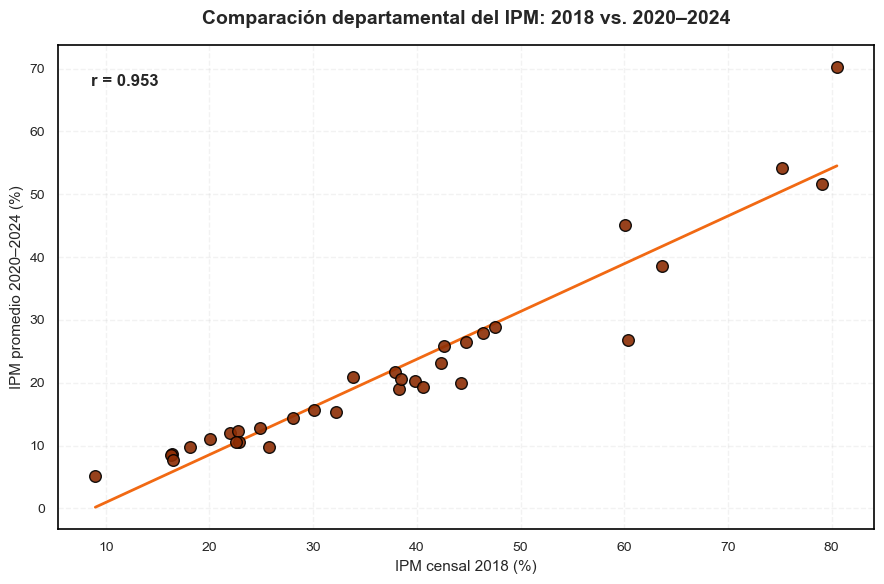

In [168]:
fig, ax = plt.subplots(figsize=(9, 6))

ax.scatter(
    comparacion_ipm["IPM_2018"],
    comparacion_ipm["IPM_2020_2024"],
    s=70,
    color="#8c2d04",
    edgecolor="black",
    linewidth=1,
    alpha=0.9,
    zorder=3
)

pendiente, intercepto = np.polyfit(
    comparacion_ipm["IPM_2018"],
    comparacion_ipm["IPM_2020_2024"],
    1
)

x_linea = np.linspace(
    comparacion_ipm["IPM_2018"].min(),
    comparacion_ipm["IPM_2018"].max(),
    100
)

ax.plot(
    x_linea,
    pendiente * x_linea + intercepto,
    color="#f16913",
    linewidth=2,
    zorder=2
)

ax.text(
    0.04,
    0.94,
    f"r = {correlacion_ipm:.3f}",
    transform=ax.transAxes,
    fontsize=12,
    fontweight="bold",
    va="top"
)

ax.set_title(
    "Comparación departamental del IPM: 2018 vs. 2020–2024",
    fontsize=14,
    fontweight="bold",
    pad=15
)

ax.set_xlabel(
    "IPM censal 2018 (%)",
    fontsize=11
)

ax.set_ylabel(
    "IPM promedio 2020–2024 (%)",
    fontsize=11
)

ax.grid(
    axis="both",
    linestyle="--",
    alpha=0.25,
    zorder=1
)

for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_color("black")
    spine.set_linewidth(1.2)

ax.tick_params(
    axis="both",
    labelsize=10,
    color="black"
)

plt.tight_layout()
plt.show()

El gráfico muestra una relación positiva clara entre ambas mediciones del IPM. La mayoría de los departamentos se concentra alrededor de la línea de tendencia, lo que coincide con la alta correlación observada ($r=0.953$). En términos generales, los departamentos que presentaban mayores niveles de pobreza multidimensional en el IPM censal de 2018 también registran valores relativamente altos en el promedio 2020–2024.

Aunque existen algunas diferencias entre departamentos, especialmente entre aquellos con valores más altos de IPM, el patrón territorial se mantiene. Esto respalda el uso del IPM 2020–2024 como una medida actualizada de la pobreza multidimensional para el periodo analizado.

### 9.3 Estandarización del IPM 2020–2024

Antes de incorporar el IPM 2020–2024 al modelo BYM2, la covariable se estandariza utilizando su media y desviación estándar departamental. De esta forma, el coeficiente estimado por el modelo representa el cambio en el log-riesgo relativo asociado con un incremento de una desviación estándar en el IPM.

La transformación utilizada es:

$$
IPM_d^{*}
=\frac{IPM_d-\overline{IPM}}{s_{IPM}}
$$

donde $\overline{IPM}$ corresponde a la media departamental del IPM 2020–2024 y $s_{IPM}$ a su desviación estándar.

In [99]:
media_ipm_2020_2024 = (
    ipm_departamental_2020_2024["IPM_2020_2024"].mean()
)

sd_ipm_2020_2024 = (
    ipm_departamental_2020_2024["IPM_2020_2024"].std()
)

ipm_departamental_2020_2024["IPM_2020_2024_std"] = (
    (
        ipm_departamental_2020_2024["IPM_2020_2024"]
        - media_ipm_2020_2024
    )
    / sd_ipm_2020_2024
)

print(
    "Media original:",
    round(media_ipm_2020_2024, 3)
)

print(
    "DE original:",
    round(sd_ipm_2020_2024, 3)
)

print(
    "Media estandarizada:",
    round(
        ipm_departamental_2020_2024["IPM_2020_2024_std"].mean(),
        6
    )
)

print(
    "DE estandarizada:",
    round(
        ipm_departamental_2020_2024["IPM_2020_2024_std"].std(),
        6
    )
)

Media original: 21.972
DE original: 14.967
Media estandarizada: 0.0
DE estandarizada: 1.0


### 9.4 Preparación de los datos para el modelo BYM2

Una vez estandarizado el IPM 2020–2024, la covariable se integra con la base utilizada en el modelo BYM2. La unión se realiza mediante el código departamental, conservando el mismo orden de las 33 unidades geográficas empleado en la construcción de los vectores de casos observados, casos esperados y estructura espacial.

Antes del ajuste del modelo se verifica que todos los departamentos dispongan de información para la covariable y que no existan valores faltantes.

In [101]:
datos_bym2_ipm_2020_2024 = (
    datos_bym2_ordenados
    .merge(
        ipm_departamental_2020_2024[
            [
                "dpto_ccdgo",
                "IPM_2020_2024",
                "IPM_2020_2024_std"
            ]
        ],
        on="dpto_ccdgo",
        how="left",
        validate="one_to_one"
    )
)

print("Departamentos:", len(datos_bym2_ipm_2020_2024))
print(
    "IPM faltantes:",
    datos_bym2_ipm_2020_2024["IPM_2020_2024"].isna().sum()
)
print(
    "IPM estandarizado faltantes:",
    datos_bym2_ipm_2020_2024["IPM_2020_2024_std"].isna().sum()
)

tabla_bym2_ipm_2020_2024 = (
    datos_bym2_ipm_2020_2024[
        [
            "dpto_ccdgo",
            "DPNOM",
            "IPM_2020_2024",
            "IPM_2020_2024_std"
        ]
    ]
    .rename(
        columns={
            "dpto_ccdgo": "Código",
            "DPNOM": "Departamento",
            "IPM_2020_2024": "IPM 2020–2024",
            "IPM_2020_2024_std": "IPM estandarizado"
        }
    )
)

styled_bym2_ipm = (
    tabla_bym2_ipm_2020_2024
    .style
    .hide(axis="index")
    .format({
        "IPM 2020–2024": "{:.2f}",
        "IPM estandarizado": "{:.3f}"
    })
    .set_table_styles([
        {
            "selector": "table",
            "props": [
                ("margin", "0 auto"),
                ("width", "auto"),
                ("border-collapse", "collapse")
            ]
        },
        {
            "selector": "th",
            "props": [
                ("text-align", "center"),
                ("background-color", "#f2f2f2"),
                ("color", "black"),
                ("font-weight", "bold"),
                ("border", "1px solid black"),
                ("padding", "10px")
            ]
        },
        {
            "selector": "td",
            "props": [
                ("text-align", "center"),
                ("border", "1px solid black"),
                ("padding", "10px")
            ]
        }
    ])
    .set_properties(
        subset=["Departamento"],
        **{"text-align": "left"}
    )
)

display(
    HTML(
        "<div style='text-align: center; width: 100%;'>"
        + styled_bym2_ipm.to_html()
        + "</div>"
    )
)

Departamentos: 33
IPM faltantes: 0
IPM estandarizado faltantes: 0


Código,Departamento,IPM 2020–2024,IPM estandarizado
05,Antioquia,12.05,-0.663
08,Atlántico,12.28,-0.648
11,"Bogotá, D.C.",5.21,-1.120
13,Bolívar,21.67,-0.020
15,Boyacá,9.81,-0.812
17,Caldas,10.63,-0.758
18,Caquetá,19.97,-0.134
19,Cauca,18.99,-0.199
20,Cesar,20.53,-0.096
23,Córdoba,26.53,0.305


La integración de la covariable se realizó para los 33 departamentos incluidos en el modelo BYM2, sin valores faltantes. El IPM estandarizado conserva el orden de las unidades geográficas utilizado en el modelo espacial, por lo que la covariable puede incorporarse directamente en la especificación del modelo.

### 9.5 Modelo BYM2 con IPM 2020–2024

Una vez preparada y estandarizada la covariable, se incorpora el IPM promedio 2020–2024 al modelo BYM2. Esta especificación mantiene la misma estructura espacial utilizada en el modelo base y añade el IPM como efecto fijo, permitiendo evaluar su asociación con el riesgo relativo de mortalidad por cáncer de estómago.

El predictor lineal se define como:

$$
\log(\theta_i)
=\alpha
+
\beta_{IPM}X_i
+
\sigma
\left(
\sqrt{\frac{\rho}{s}}\phi_i
+
\sqrt{1-\rho}\delta_i
\right)
$$

donde $X_i$ corresponde al IPM 2020–2024 estandarizado del departamento $i$ y $\beta_{IPM}$ representa su asociación con el log-riesgo relativo.

#### 9.5.1 Preparación de los datos para Stan

In [104]:
idx_conn = (
    np.where(
        datos_bym2_ipm_2020_2024["dpto_ccdgo"].ne("88")
    )[0] + 1
)

idx_island = int(
    np.where(
        datos_bym2_ipm_2020_2024["dpto_ccdgo"].eq("88")
    )[0][0] + 1
)

mask_conn = (
    datos_bym2_ipm_2020_2024["dpto_ccdgo"].ne("88")
)

mask_island = (
    datos_bym2_ipm_2020_2024["dpto_ccdgo"].eq("88")
)

Y = (
    datos_bym2_ipm_2020_2024["Observadas"]
    .astype(int)
    .to_numpy()
)

E = (
    datos_bym2_ipm_2020_2024["Esperadas"]
    .astype(float)
    .to_numpy()
)

Y_conn = (
    datos_bym2_ipm_2020_2024.loc[mask_conn, "Observadas"]
    .astype(int)
    .to_numpy()
)

E_conn = (
    datos_bym2_ipm_2020_2024.loc[mask_conn, "Esperadas"]
    .astype(float)
    .to_numpy()
)

Y_island = int(
    datos_bym2_ipm_2020_2024.loc[
        mask_island,
        "Observadas"
    ].iloc[0]
)

E_island = float(
    datos_bym2_ipm_2020_2024.loc[
        mask_island,
        "Esperadas"
    ].iloc[0]
)

X_ipm = (
    datos_bym2_ipm_2020_2024["IPM_2020_2024_std"]
    .astype(float)
    .to_numpy()
)

datos_modelo_ipm_2020_2024 = {
    "N": len(datos_bym2_ipm_2020_2024),
    "N_conn": len(idx_conn),
    "N_edges": len(node1),
    "Y": Y,
    "E": E,
    "Y_conn": Y_conn,
    "E_conn": E_conn,
    "Y_island": Y_island,
    "E_island": E_island,
    "node1": node1,
    "node2": node2,
    "scaling_factor": scaling_factor,
    "idx_conn": idx_conn,
    "idx_island": idx_island,
    "X_ipm": X_ipm
}

print("N:", datos_modelo_ipm_2020_2024["N"])
print("N conectados:", datos_modelo_ipm_2020_2024["N_conn"])
print("N aristas:", datos_modelo_ipm_2020_2024["N_edges"])
print("Observadas:", datos_modelo_ipm_2020_2024["Y"].sum())
print("Esperadas:", round(datos_modelo_ipm_2020_2024["E"].sum(), 2))
print("Longitud X_ipm:", len(datos_modelo_ipm_2020_2024["X_ipm"]))
print("Media X_ipm:", round(datos_modelo_ipm_2020_2024["X_ipm"].mean(), 6))
print("DE X_ipm:", round(datos_modelo_ipm_2020_2024["X_ipm"].std(ddof=1), 6))
print("Índice isla:", datos_modelo_ipm_2020_2024["idx_island"])
print(
    "Departamento isla:",
    datos_bym2_ipm_2020_2024.iloc[idx_island - 1]["DPNOM"]
)

N: 33
N conectados: 32
N aristas: 74
Observadas: 26418
Esperadas: 26418.0
Longitud X_ipm: 33
Media X_ipm: 0.0
DE X_ipm: 1.0
Índice isla: 28
Departamento isla: Archipiélago de San Andrés, Providencia y Santa Catalina


#### 9.5.2 Ajuste del modelo

El modelo BYM2 con IPM 2020–2024 se estima mediante cuatro cadenas de MCMC. Se mantienen la misma configuración de muestreo y los mismos parámetros de control utilizados en el modelo BYM2 base y en el modelo con IPM censal de 2018, permitiendo conservar una especificación consistente entre los diferentes ajustes.

In [107]:
modelo_bym2_ipm_2020_2024 = CmdStanModel(
    stan_file=r"C:\Users\USER\Desktop\Tesis\src\bym2_estomago_ipm_2020_2024.stan"
)

ajuste_bym2_ipm_2020_2024 = modelo_bym2_ipm_2020_2024.sample(
    data=datos_modelo_ipm_2020_2024,
    chains=4,
    parallel_chains=4,
    iter_warmup=1000,
    iter_sampling=1000,
    seed=1234,
    adapt_delta=0.99,
    max_treedepth=15,
    show_progress=True
)

11:24:14 - cmdstanpy - INFO - compiling stan file C:\Users\USER\Desktop\Tesis\src\bym2_estomago_ipm_2020_2024.stan to exe file C:\Users\USER\Desktop\Tesis\src\bym2_estomago_ipm_2020_2024.exe
11:24:30 - cmdstanpy - INFO - compiled model executable: C:\Users\USER\Desktop\Tesis\src\bym2_estomago_ipm_2020_2024.exe
11:24:30 - cmdstanpy - INFO - CmdStan start processing


chain 1 |          | 00:00 Status

chain 2 |          | 00:00 Status

chain 3 |          | 00:00 Status

chain 4 |          | 00:00 Status

11:24:52 - cmdstanpy - INFO - CmdStan done processing.


#### 9.5.3 Diagnóstico de convergencia y parámetros globales

Una vez ajustado el modelo, se evalúa la convergencia de las cadenas mediante el estadístico $\hat{R}$ y el tamaño efectivo de muestra (ESS). Posteriormente, se resumen las distribuciones posteriores de los parámetros globales $\alpha$, $\beta_{IPM}$, $\sigma$ y $\rho$.

In [109]:
resumen_ipm_2020_2024 = ajuste_bym2_ipm_2020_2024.summary()

parametros_ipm_2020_2024 = [
    "alpha",
    "beta_ipm",
    "sigma",
    "rho"
]

filas_parametros = []

for parametro in parametros_ipm_2020_2024:
    draws = ajuste_bym2_ipm_2020_2024.stan_variable(parametro)

    filas_parametros.append({
        "Parámetro": parametro,
        "Media": np.mean(draws),
        "Mediana": np.median(draws),
        "DE": np.std(draws, ddof=1),
        "IC 2.5%": np.quantile(draws, 0.025),
        "IC 97.5%": np.quantile(draws, 0.975),
        "ESS": resumen_ipm_2020_2024.loc[parametro, "N_Eff"],
        "R-hat": resumen_ipm_2020_2024.loc[parametro, "R_hat"]
    })

tabla_parametros_ipm_2020_2024 = pd.DataFrame(filas_parametros)

tabla_parametros_ipm_2020_2024["Parámetro"] = (
    tabla_parametros_ipm_2020_2024["Parámetro"]
    .replace({
        "alpha": "α",
        "beta_ipm": "β IPM",
        "sigma": "σ",
        "rho": "ρ"
    })
)

styled_parametros_ipm_2020_2024 = (
    tabla_parametros_ipm_2020_2024
    .style
    .hide(axis="index")
    .format({
        "Media": "{:.3f}",
        "Mediana": "{:.3f}",
        "DE": "{:.3f}",
        "IC 2.5%": "{:.3f}",
        "IC 97.5%": "{:.3f}",
        "ESS": "{:.2f}",
        "R-hat": "{:.2f}"
    })
    .set_table_styles([
        {
            "selector": "table",
            "props": [
                ("margin", "0 auto"),
                ("width", "auto"),
                ("border-collapse", "collapse")
            ]
        },
        {
            "selector": "th",
            "props": [
                ("text-align", "center"),
                ("background-color", "#f2f2f2"),
                ("color", "black"),
                ("font-weight", "bold"),
                ("border", "1px solid black"),
                ("padding", "10px")
            ]
        },
        {
            "selector": "td",
            "props": [
                ("text-align", "center"),
                ("border", "1px solid black"),
                ("padding", "10px")
            ]
        }
    ])
    .set_properties(
        subset=["Parámetro"],
        **{"text-align": "left"}
    )
)

display(
    HTML(
        "<div style='text-align: center; width: 100%;'>"
        + styled_parametros_ipm_2020_2024.to_html()
        + "</div>"
    )
)

Parámetro,Media,Mediana,DE,IC 2.5%,IC 97.5%,ESS,R-hat
α,-0.514,-0.512,0.051,-0.621,-0.417,3489.72,1.00
β IPM,-0.742,-0.741,0.120,-0.976,-0.501,2054.68,1.00
σ,0.522,0.514,0.082,0.386,0.702,1608.81,1.01
ρ,0.804,0.880,0.209,0.238,1.000,397.22,1.00


In [111]:
import json
from pathlib import Path

RUTA_RESULTADOS = Path("../Resultados")
RUTA_RESULTADOS.mkdir(parents=True, exist_ok=True)

alpha_draws = ajuste_bym2_ipm_2020_2024.stan_variable("alpha")
beta_ipm_draws = ajuste_bym2_ipm_2020_2024.stan_variable("beta_ipm")
sigma_draws = ajuste_bym2_ipm_2020_2024.stan_variable("sigma")
rho_draws = ajuste_bym2_ipm_2020_2024.stan_variable("rho")
rr_draws_ipm_2020_2024 = ajuste_bym2_ipm_2020_2024.stan_variable("rr")

resumen_cmdstan = ajuste_bym2_ipm_2020_2024.summary()

def resumen_draws(draws, nombre):
    return {
        "media": float(np.mean(draws)),
        "mediana": float(np.median(draws)),
        "desviacion_estandar": float(np.std(draws, ddof=1)),
        "ic95_inferior": float(np.quantile(draws, 0.025)),
        "ic95_superior": float(np.quantile(draws, 0.975)),
        "ess": float(resumen_cmdstan.loc[nombre, "N_Eff"]),
        "r_hat": float(resumen_cmdstan.loc[nombre, "R_hat"])
    }

parametros_globales = {
    "alpha": resumen_draws(alpha_draws, "alpha"),
    "beta_ipm": resumen_draws(beta_ipm_draws, "beta_ipm"),
    "sigma": resumen_draws(sigma_draws, "sigma"),
    "rho": resumen_draws(rho_draws, "rho")
}

rr_ipm_draws = np.exp(beta_ipm_draws)

efecto_ipm = {
    "beta": {
        "media": float(np.mean(beta_ipm_draws)),
        "mediana": float(np.median(beta_ipm_draws)),
        "desviacion_estandar": float(np.std(beta_ipm_draws, ddof=1)),
        "ic95_inferior": float(np.quantile(beta_ipm_draws, 0.025)),
        "ic95_superior": float(np.quantile(beta_ipm_draws, 0.975))
    },
    "rr_por_1_de": {
        "media": float(np.mean(rr_ipm_draws)),
        "mediana": float(np.median(rr_ipm_draws)),
        "ic95_inferior": float(np.quantile(rr_ipm_draws, 0.025)),
        "ic95_superior": float(np.quantile(rr_ipm_draws, 0.975))
    },
    "probabilidad_beta_menor_0": float(
        np.mean(beta_ipm_draws < 0)
    ),
    "incremento_ipm_por_1_de": float(sd_ipm_2020_2024)
}

resultados_departamentales = []

for i, fila in datos_bym2_ipm_2020_2024.reset_index(drop=True).iterrows():
    draws_rr = rr_draws_ipm_2020_2024[:, i]

    resultados_departamentales.append({
        "codigo_departamento": str(fila["dpto_ccdgo"]),
        "departamento": str(fila["DPNOM"]),
        "observadas": int(fila["Observadas"]),
        "esperadas": float(fila["Esperadas"]),
        "smr_crudo": float(fila["SMR"]),
        "ipm_2020_2024": float(fila["IPM_2020_2024"]),
        "ipm_2020_2024_std": float(fila["IPM_2020_2024_std"]),
        "rr_posterior_media": float(np.mean(draws_rr)),
        "rr_posterior_mediana": float(np.median(draws_rr)),
        "rr_posterior_ic95_inferior": float(
            np.quantile(draws_rr, 0.025)
        ),
        "rr_posterior_ic95_superior": float(
            np.quantile(draws_rr, 0.975)
        ),
        "probabilidad_rr_mayor_1": float(
            np.mean(draws_rr > 1)
        )
    })

resultado_modelo = {
    "modelo": {
        "nombre": "BYM2 + IPM 2020-2024",
        "cancer": "Estómago",
        "periodo_mortalidad": "2020-2024",
        "nivel_geografico": "Departamento",
        "numero_departamentos": 33,
        "archivo_stan": "bym2_estomago_ipm_2020_2024.stan"
    },
    "mcmc": {
        "cadenas": 4,
        "warmup_por_cadena": 1000,
        "sampling_por_cadena": 1000,
        "draws_posteriores_totales": int(
            rr_draws_ipm_2020_2024.shape[0]
        ),
        "seed": 1234,
        "adapt_delta": 0.99,
        "max_treedepth": 15
    },
    "estructura_espacial": {
        "tipo_vecindad": "Queen",
        "numero_aristas": int(len(node1)),
        "numero_conectados": int(len(idx_conn)),
        "numero_islas": 1,
        "departamento_isla": "Archipiélago de San Andrés, Providencia y Santa Catalina",
        "scaling_factor": float(scaling_factor)
    },
    "covariable_ipm": {
        "fuente": "IPM 2018-2024",
        "periodo_utilizado": "2020-2024",
        "metodo_periodo": "Promedio simple de los cinco estimadores departamentales anuales",
        "media_departamental": float(media_ipm_2020_2024),
        "desviacion_estandar_departamental": float(sd_ipm_2020_2024),
        "estandarizacion": "(IPM - media) / desviacion estándar muestral",
        "media_estandarizada": float(
            datos_bym2_ipm_2020_2024[
                "IPM_2020_2024_std"
            ].mean()
        ),
        "desviacion_estandar_estandarizada": float(
            datos_bym2_ipm_2020_2024[
                "IPM_2020_2024_std"
            ].std(ddof=1)
        )
    },
    "parametros_globales": parametros_globales,
    "efecto_ipm": efecto_ipm,
    "resultados_departamentales": resultados_departamentales
}

RUTA_JSON = (
    RUTA_RESULTADOS
    / "bym2_ipm_2020_2024_estomago.json"
)

with open(RUTA_JSON, "w", encoding="utf-8") as f:
    json.dump(
        resultado_modelo,
        f,
        ensure_ascii=False,
        indent=4
    )

print("Modelo exportado correctamente:")
print(RUTA_JSON)
print()
print("Departamentos guardados:", len(resultados_departamentales))
print(
    "Draws posteriores utilizados:",
    rr_draws_ipm_2020_2024.shape[0]
)

Modelo exportado correctamente:
..\Resultados\bym2_ipm_2020_2024_estomago.json

Departamentos guardados: 33
Draws posteriores utilizados: 4000


#### 9.5.4 Asociación entre el IPM y el riesgo relativo

Para facilitar la interpretación del efecto de la covariable, el coeficiente posterior del IPM se transforma mediante la función exponencial. De esta manera, $\exp(\beta_{IPM})$ representa el cambio multiplicativo en el riesgo relativo asociado con un incremento de una desviación estándar en el IPM 2020–2024.

In [110]:
beta_ipm_draws = (
    ajuste_bym2_ipm_2020_2024
    .stan_variable("beta_ipm")
)

rr_ipm_draws = np.exp(beta_ipm_draws)

resumen_efecto_ipm = pd.DataFrame({
    "Medida": [
        "β IPM",
        "RR por 1 DE de IPM",
        "P(β IPM < 0)"
    ],
    "Media": [
        np.mean(beta_ipm_draws),
        np.mean(rr_ipm_draws),
        np.mean(beta_ipm_draws < 0)
    ],
    "Mediana": [
        np.median(beta_ipm_draws),
        np.median(rr_ipm_draws),
        np.nan
    ],
    "IC 2.5%": [
        np.quantile(beta_ipm_draws, 0.025),
        np.quantile(rr_ipm_draws, 0.025),
        np.nan
    ],
    "IC 97.5%": [
        np.quantile(beta_ipm_draws, 0.975),
        np.quantile(rr_ipm_draws, 0.975),
        np.nan
    ]
})

styled_efecto_ipm = (
    resumen_efecto_ipm
    .style
    .hide(axis="index")
    .format({
        "Media": "{:.3f}",
        "Mediana": "{:.3f}",
        "IC 2.5%": "{:.3f}",
        "IC 97.5%": "{:.3f}"
    }, na_rep="—")
    .set_table_styles([
        {
            "selector": "table",
            "props": [
                ("margin", "0 auto"),
                ("width", "auto"),
                ("border-collapse", "collapse")
            ]
        },
        {
            "selector": "th",
            "props": [
                ("text-align", "center"),
                ("background-color", "#f2f2f2"),
                ("color", "black"),
                ("font-weight", "bold"),
                ("border", "1px solid black"),
                ("padding", "10px")
            ]
        },
        {
            "selector": "td",
            "props": [
                ("text-align", "center"),
                ("border", "1px solid black"),
                ("padding", "10px")
            ]
        }
    ])
    .set_properties(
        subset=["Medida"],
        **{"text-align": "left"}
    )
)

display(
    HTML(
        "<div style='text-align: center; width: 100%;'>"
        + styled_efecto_ipm.to_html()
        + "</div>"
    )
)

Medida,Media,Mediana,IC 2.5%,IC 97.5%
β IPM,-0.742,-0.741,-0.976,-0.501
RR por 1 DE de IPM,0.480,0.477,0.377,0.606
P(β IPM < 0),1.000,—,—,—


El IPM 2020–2024 presentó una asociación negativa con el riesgo relativo de mortalidad por cáncer de estómago. El coeficiente posterior fue de $\beta_{IPM}=-0.742$, con un intervalo de credibilidad del 95% entre -0.976 y -0.501, y la totalidad de las muestras posteriores se ubicó por debajo de cero.

Al transformar el coeficiente a la escala del riesgo relativo, un incremento de una desviación estándar en el IPM, equivalente a aproximadamente 14.97 puntos porcentuales, se asoció con un RR posterior medio de 0.480 (IC95%: 0.377–0.606). Esto indica que los departamentos con mayores niveles de pobreza multidimensional presentaron, en promedio, menores riesgos relativos estimados dentro del modelo.

Esta asociación no debe interpretarse como un efecto protector de la pobreza. El resultado describe una relación ecológica a nivel departamental y puede estar influenciado por otras características territoriales no incluidas en esta especificación, entre ellas diferencias en la estructura demográfica de los departamentos.

### 9.6 Selección de la medida de IPM

Los modelos ajustados con el IPM censal de 2018 y con el IPM promedio 2020–2024 mostraron resultados muy similares. El IPM censal presentó un coeficiente posterior de $\beta_{IPM}=-0.726$ y un RR de 0.488, mientras que con el IPM 2020–2024 se obtuvo $\beta_{IPM}=-0.742$ y un RR de 0.480. En ambos casos, los intervalos de credibilidad excluyeron el valor nulo y la probabilidad posterior de una asociación negativa fue igual a 1.

Dado que ambas medidas producen resultados consistentes y presentan una alta concordancia territorial ($r=0.953$), se selecciona el **IPM promedio 2020–2024** para los análisis posteriores. Esta elección permite utilizar una medida de pobreza multidimensional correspondiente al mismo periodo de la mortalidad analizada, mientras que el IPM censal de 2018 se conserva como análisis de referencia.

### 9.7 Distribución espacial del IPM 2020–2024

La distribución espacial del IPM permite identificar los departamentos con mayores niveles de pobreza multidimensional durante el periodo 2020–2024 y comparar visualmente este patrón territorial con la distribución del riesgo de mortalidad estimada mediante el modelo BYM2 base.

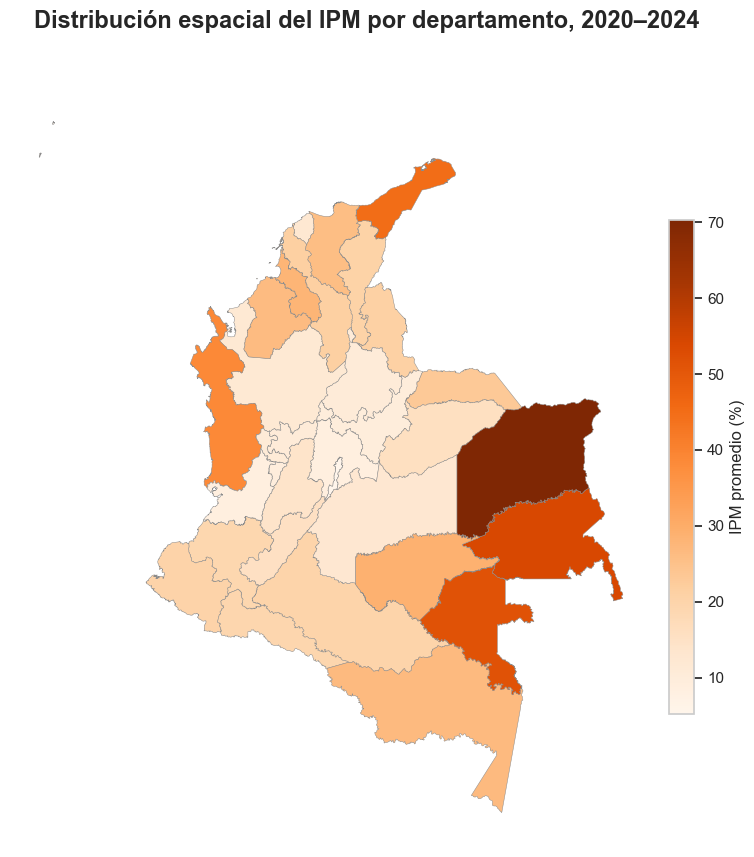

In [130]:
gdf_ipm_2020_2024 = gdf_departamentos.merge(
    ipm_departamental_2020_2024[
        ["dpto_ccdgo", "IPM_2020_2024"]
    ],
    left_on="DPTO_CCDGO",
    right_on="dpto_ccdgo",
    how="left"
)

fig, ax = plt.subplots(
    1,
    1,
    figsize=(9, 9)
)

gdf_ipm_2020_2024.plot(
    ax=ax,
    column="IPM_2020_2024",
    cmap="Oranges",
    edgecolor="#8c8c8c",
    linewidth=0.35,
    aspect=1,
    legend=True,
    legend_kwds={
        "label": "IPM promedio (%)",
        "shrink": 0.65,
        "pad": 0.02
    }
)

ax.axis("off")

fig.suptitle(
    "Distribución espacial del IPM por departamento, 2020–2024",
    fontsize=17,
    fontweight="bold",
    y=0.95
)

plt.tight_layout(rect=[0, 0, 1, 0.93])
plt.show()

### 9.8 Comparación del riesgo espacial: BYM2 base vs. BYM2 + IPM

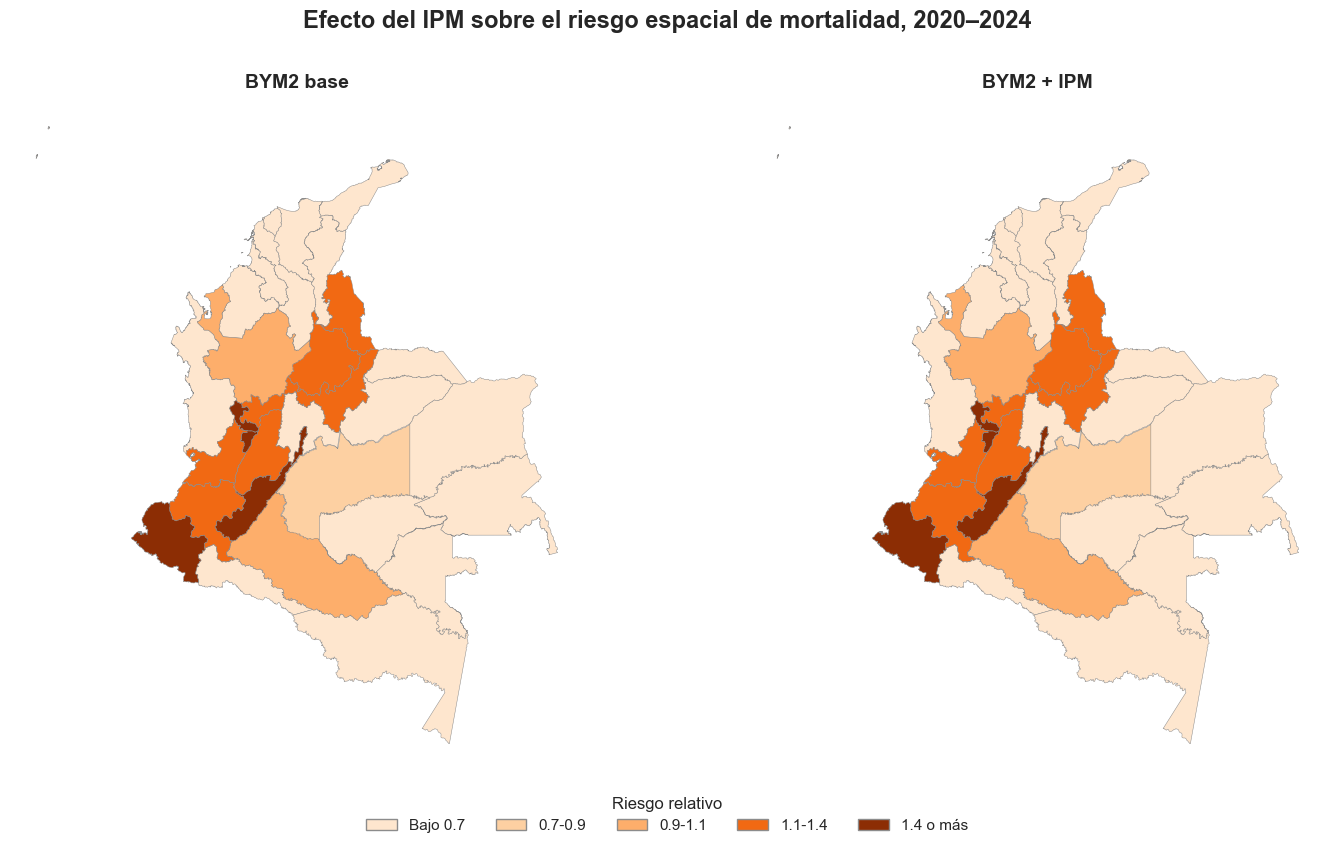

In [133]:
rr_draws_ipm_2020_2024 = (
    ajuste_bym2_ipm_2020_2024
    .stan_variable("rr")
)

rr_media_ipm_2020_2024 = (
    rr_draws_ipm_2020_2024.mean(axis=0)
)

gdf_comparacion_ipm = (
    gdf_departamentos
    .merge(
        resultados_rr[
            ["dpto_ccdgo", "RR_media"]
        ],
        left_on="DPTO_CCDGO",
        right_on="dpto_ccdgo",
        how="left"
    )
)

gdf_comparacion_ipm["RR_IPM"] = (
    rr_media_ipm_2020_2024
)

colores_comparacion = {
    "Bajo 0.7": "#fee6ce",
    "0.7-0.9": "#fdd0a2",
    "0.9-1.1": "#fdae6b",
    "1.1-1.4": "#f16913",
    "1.4 o más": "#8c2d04"
}

bins_rr = [
    -np.inf,
    0.7,
    0.9,
    1.1,
    1.4,
    np.inf
]

categorias_rr = list(
    colores_comparacion.keys()
)

gdf_comparacion_ipm["Categoria_base"] = pd.cut(
    gdf_comparacion_ipm["RR_media"],
    bins=bins_rr,
    labels=categorias_rr,
    right=False
)

gdf_comparacion_ipm["Categoria_ipm"] = pd.cut(
    gdf_comparacion_ipm["RR_IPM"],
    bins=bins_rr,
    labels=categorias_rr,
    right=False
)

fig, axes = plt.subplots(
    1,
    2,
    figsize=(15, 9)
)

for categoria, color in colores_comparacion.items():
    subset_base = gdf_comparacion_ipm[
        gdf_comparacion_ipm["Categoria_base"] == categoria
    ]

    if not subset_base.empty:
        subset_base.plot(
            ax=axes[0],
            color=color,
            edgecolor="#8c8c8c",
            linewidth=0.35,
            aspect=1
        )

    subset_ipm = gdf_comparacion_ipm[
        gdf_comparacion_ipm["Categoria_ipm"] == categoria
    ]

    if not subset_ipm.empty:
        subset_ipm.plot(
            ax=axes[1],
            color=color,
            edgecolor="#8c8c8c",
            linewidth=0.35,
            aspect=1
        )

axes[0].set_title(
    "BYM2 base",
    fontsize=14,
    fontweight="bold"
)

axes[1].set_title(
    "BYM2 + IPM",
    fontsize=14,
    fontweight="bold"
)

for ax in axes:
    ax.axis("off")

leyenda = [
    Patch(
        facecolor=color,
        edgecolor="#8c8c8c",
        label=categoria
    )
    for categoria, color in colores_comparacion.items()
]

fig.legend(
    handles=leyenda,
    title="Riesgo relativo",
    loc="lower center",
    bbox_to_anchor=(0.5, 0.03),
    ncol=5,
    frameon=False
)

fig.suptitle(
    "Efecto del IPM sobre el riesgo espacial de mortalidad, 2020–2024",
    fontsize=17,
    fontweight="bold",
    y=0.96
)

plt.tight_layout(rect=[0, 0.09, 1, 0.93])
plt.show()

## 10. Índice de Riesgo de la Calidad del Agua (IRCA)

Como segunda covariable territorial se incorpora el Índice de Riesgo de la Calidad del Agua para Consumo Humano (IRCA). Para mantener correspondencia temporal con el periodo de mortalidad analizado, se utilizan los registros comprendidos entre 2020 y 2024.

Antes de construir una medida departamental para el periodo, se evalúa la cobertura de información disponible para cada departamento y año.

### 10.1 Cobertura departamental 2020-2024

In [117]:
calidad_agua = pd.read_csv(
    RUTA_CALIDAD_AGUA
    / "Calidad_del_Agua_para_Consumo_Humano_en_Colombia_20260523.csv",
    dtype=str
)

calidad_agua["Año"] = pd.to_numeric(
    calidad_agua["Año"]
    .str.replace(",", "", regex=False)
    .str.strip(),
    errors="coerce"
)

calidad_agua["IRCA"] = pd.to_numeric(
    calidad_agua["IRCA"]
    .str.replace(",", ".", regex=False)
    .str.strip(),
    errors="coerce"
)

calidad_agua["DepartamentoCodigo"] = (
    calidad_agua["DepartamentoCodigo"]
    .str.strip()
    .str.zfill(2)
)

irca_2020_2024 = (
    calidad_agua[
        calidad_agua["Año"].between(2020, 2024)
    ]
    .copy()
)

cobertura_irca = (
    irca_2020_2024
    .groupby("Año")
    .agg(
        Departamentos=("DepartamentoCodigo", "nunique"),
        Municipios=("MunicipioCodigo", "nunique"),
        IRCA_disponibles=("IRCA", "count")
    )
    .reset_index()
)

print("Registros 2020–2024:", len(irca_2020_2024))

styled_cobertura_irca = (
    cobertura_irca
    .style
    .hide(axis="index")
    .format({
        "Año": "{:.0f}"
    })
    .set_table_styles([
        {
            "selector": "table",
            "props": [
                ("margin", "0 auto"),
                ("width", "auto"),
                ("border-collapse", "collapse")
            ]
        },
        {
            "selector": "th",
            "props": [
                ("text-align", "center"),
                ("background-color", "#f2f2f2"),
                ("color", "black"),
                ("font-weight", "bold"),
                ("border", "1px solid black"),
                ("padding", "10px")
            ]
        },
        {
            "selector": "td",
            "props": [
                ("text-align", "center"),
                ("border", "1px solid black"),
                ("padding", "10px")
            ]
        }
    ])
)

display(
    HTML(
        "<div style='text-align: center; width: 100%;'>"
        + styled_cobertura_irca.to_html()
        + "</div>"
    )
)

Registros 2020–2024: 5150


Año,Departamentos,Municipios,IRCA_disponibles
2020,32,1006,1037
2021,33,1041,1073
2022,32,962,993
2023,30,980,1009
2024,32,1007,1038


### 10.2 Disponibilidad departamental del IRCA

Para construir una medida del IRCA correspondiente al periodo 2020–2024, se evalúa la disponibilidad anual del indicador departamental. Esta revisión permite identificar los territorios con información incompleta antes de calcular el valor representativo del periodo.

La información departamental del IRCA presenta una cobertura completa para 29 de los 33 departamentos. Caquetá y Guainía cuentan con información para cuatro de los cinco años, mientras que Córdoba y Vaupés disponen de tres años. Dado que todos los departamentos cuentan con al menos tres mediciones durante el periodo, se conserva la totalidad de las unidades geográficas y se calcula el IRCA 2020–2024 como el promedio de los años disponibles, sin imputar los valores faltantes.

### 10.3 IRCA departamental 2020–2024

Para cada departamento se calcula el promedio del IRCA disponible durante 2020–2024:

$$
IRCA_{d,2020-2024}
=\frac{1}{T_d}
\sum_{t \in T_d} IRCA_{dt}
$$

donde $T_d$ corresponde al conjunto de años con información disponible para el departamento $d$.

In [120]:
irca_departamental_2020_2024 = (
    irca_departamental
    .groupby("DepartamentoCodigo")
    .agg(
        Departamento=("Departamento", "first"),
        Años_disponibles=("Año", "nunique"),
        IRCA_2020_2024=("IRCA", "mean")
    )
    .reset_index()
    .rename(
        columns={
            "DepartamentoCodigo": "dpto_ccdgo"
        }
    )
    .sort_values(
        "IRCA_2020_2024",
        ascending=False
    )
    .reset_index(drop=True)
)

tabla_irca_2020_2024 = (
    irca_departamental_2020_2024
    .rename(
        columns={
            "dpto_ccdgo": "Código",
            "Años_disponibles": "Años disponibles",
            "IRCA_2020_2024": "IRCA 2020–2024"
        }
    )
)

styled_irca_2020_2024 = (
    tabla_irca_2020_2024
    .style
    .hide(axis="index")
    .format({
        "IRCA 2020–2024": "{:.2f}"
    })
    .set_table_styles([
        {
            "selector": "table",
            "props": [
                ("margin", "0 auto"),
                ("width", "auto"),
                ("border-collapse", "collapse")
            ]
        },
        {
            "selector": "th",
            "props": [
                ("text-align", "center"),
                ("background-color", "#f2f2f2"),
                ("color", "black"),
                ("font-weight", "bold"),
                ("border", "1px solid black"),
                ("padding", "10px")
            ]
        },
        {
            "selector": "td",
            "props": [
                ("text-align", "center"),
                ("border", "1px solid black"),
                ("padding", "10px")
            ]
        }
    ])
    .set_properties(
        subset=["Departamento"],
        **{"text-align": "left"}
    )
)

display(
    HTML(
        "<div style='text-align: center; width: 100%;'>"
        + styled_irca_2020_2024.to_html()
        + "</div>"
    )
)

Código,Departamento,Años disponibles,IRCA 2020–2024
97,Vaupés,3,39.77
94,Guainía,4,36.83
52,Nariño,5,24.30
17,Caldas,5,18.68
13,Bolívar,5,18.60
91,Amazonas,5,17.14
70,Sucre,5,16.86
27,Chocó,5,16.82
73,Tolima,5,16.38
86,Putumayo,5,16.02


### 10.4 Estandarización del IRCA 2020–2024

Para incorporar el IRCA al modelo BYM2, la covariable se estandariza utilizando la media y la desviación estándar departamental:

$$
IRCA_{d}^{*}
=\frac{IRCA_d-\overline{IRCA}}{s_{IRCA}}
$$

De esta forma, el coeficiente asociado al IRCA representa el cambio en el log-riesgo relativo de mortalidad asociado con un incremento de una desviación estándar en el indicador.

In [121]:
media_irca_2020_2024 = (
    irca_departamental_2020_2024["IRCA_2020_2024"].mean()
)

sd_irca_2020_2024 = (
    irca_departamental_2020_2024["IRCA_2020_2024"].std(ddof=1)
)

irca_departamental_2020_2024["IRCA_2020_2024_std"] = (
    (
        irca_departamental_2020_2024["IRCA_2020_2024"]
        - media_irca_2020_2024
    )
    / sd_irca_2020_2024
)

print(
    "Media original:",
    round(media_irca_2020_2024, 3)
)
print(
    "DE original:",
    round(sd_irca_2020_2024, 3)
)
print(
    "Media estandarizada:",
    round(
        irca_departamental_2020_2024[
            "IRCA_2020_2024_std"
        ].mean(),
        6
    )
)
print(
    "DE estandarizada:",
    round(
        irca_departamental_2020_2024[
            "IRCA_2020_2024_std"
        ].std(ddof=1),
        6
    )
)

Media original: 11.656
DE original: 8.98
Media estandarizada: -0.0
DE estandarizada: 1.0


### 10.5 Integración del IRCA con los datos del modelo

Finalmente, la covariable estandarizada se integra con las unidades departamentales utilizadas en el modelo BYM2, verificando la correspondencia de los 33 departamentos y la ausencia de valores faltantes antes del ajuste.

In [122]:
datos_bym2_irca_2020_2024 = (
    datos_bym2_ordenados
    .merge(
        irca_departamental_2020_2024[
            [
                "dpto_ccdgo",
                "IRCA_2020_2024",
                "IRCA_2020_2024_std"
            ]
        ],
        on="dpto_ccdgo",
        how="left",
        validate="one_to_one"
    )
)

print(
    "Departamentos:",
    len(datos_bym2_irca_2020_2024)
)

print(
    "IRCA faltantes:",
    datos_bym2_irca_2020_2024[
        "IRCA_2020_2024"
    ].isna().sum()
)

print(
    "IRCA estandarizado faltantes:",
    datos_bym2_irca_2020_2024[
        "IRCA_2020_2024_std"
    ].isna().sum()
)

print(
    "Orden conservado:",
    datos_bym2_irca_2020_2024["dpto_ccdgo"].tolist()
    == datos_bym2_ordenados["dpto_ccdgo"].tolist()
)

Departamentos: 33
IRCA faltantes: 0
IRCA estandarizado faltantes: 0
Orden conservado: True


### 10.6 Modelo BYM2 con IRCA 2020–2024

Una vez preparado y estandarizado el IRCA, la covariable se incorpora al modelo BYM2 manteniendo la misma estructura espacial y configuración utilizada en los modelos anteriores.

El predictor lineal se define como:

$$
\log(\theta_i)
=\alpha
+
\beta_{IRCA}X_i
+
\sigma
\left(
\sqrt{\frac{\rho}{s}}\phi_i
+
\sqrt{1-\rho}\delta_i
\right)
$$

donde $X_i$ corresponde al IRCA 2020–2024 estandarizado y $\beta_{IRCA}$ representa su asociación con el log-riesgo relativo de mortalidad.

In [123]:
X_irca = (
    datos_bym2_irca_2020_2024["IRCA_2020_2024_std"]
    .astype(float)
    .to_numpy()
)

datos_modelo_irca_2020_2024 = {
    "N": len(datos_bym2_irca_2020_2024),
    "N_conn": len(idx_conn),
    "N_edges": len(node1),
    "Y": Y,
    "E": E,
    "Y_conn": Y_conn,
    "E_conn": E_conn,
    "Y_island": Y_island,
    "E_island": E_island,
    "node1": node1,
    "node2": node2,
    "scaling_factor": scaling_factor,
    "idx_conn": idx_conn,
    "idx_island": idx_island,
    "X_irca": X_irca
}

print("N:", datos_modelo_irca_2020_2024["N"])
print("N conectados:", datos_modelo_irca_2020_2024["N_conn"])
print("N aristas:", datos_modelo_irca_2020_2024["N_edges"])
print("Observadas:", datos_modelo_irca_2020_2024["Y"].sum())
print("Esperadas:", round(datos_modelo_irca_2020_2024["E"].sum(), 2))
print("Longitud X_irca:", len(datos_modelo_irca_2020_2024["X_irca"]))
print("Media X_irca:", round(datos_modelo_irca_2020_2024["X_irca"].mean(), 6))
print("DE X_irca:", round(datos_modelo_irca_2020_2024["X_irca"].std(ddof=1), 6))
print("Índice isla:", datos_modelo_irca_2020_2024["idx_island"])
print(
    "Departamento isla:",
    datos_bym2_irca_2020_2024.iloc[idx_island - 1]["DPNOM"]
)

N: 33
N conectados: 32
N aristas: 74
Observadas: 26418
Esperadas: 26418.0
Longitud X_irca: 33
Media X_irca: -0.0
DE X_irca: 1.0
Índice isla: 28
Departamento isla: Archipiélago de San Andrés, Providencia y Santa Catalina


#### 10.6.1 Ajuste del modelo

In [124]:
modelo_bym2_irca_2020_2024 = CmdStanModel(
    stan_file=r"C:\Users\USER\Desktop\Tesis\src\bym2_estomago_irca_2020_2024.stan"
)

ajuste_bym2_irca_2020_2024 = modelo_bym2_irca_2020_2024.sample(
    data=datos_modelo_irca_2020_2024,
    chains=4,
    parallel_chains=4,
    iter_warmup=1000,
    iter_sampling=1000,
    seed=1234,
    adapt_delta=0.99,
    max_treedepth=15,
    show_progress=True
)

10:11:28 - cmdstanpy - INFO - compiling stan file C:\Users\USER\Desktop\Tesis\src\bym2_estomago_irca_2020_2024.stan to exe file C:\Users\USER\Desktop\Tesis\src\bym2_estomago_irca_2020_2024.exe
10:12:10 - cmdstanpy - INFO - compiled model executable: C:\Users\USER\Desktop\Tesis\src\bym2_estomago_irca_2020_2024.exe
10:12:11 - cmdstanpy - INFO - CmdStan start processing


chain 1 |          | 00:00 Status

chain 2 |          | 00:00 Status

chain 3 |          | 00:00 Status

chain 4 |          | 00:00 Status

10:12:34 - cmdstanpy - INFO - CmdStan done processing.


#### 10.6.2 Parámetros globales

In [125]:
resumen_irca_2020_2024 = ajuste_bym2_irca_2020_2024.summary()

parametros_irca_2020_2024 = [
    "alpha",
    "beta_irca",
    "sigma",
    "rho"
]

filas_parametros_irca = []

for parametro in parametros_irca_2020_2024:
    draws = ajuste_bym2_irca_2020_2024.stan_variable(parametro)

    filas_parametros_irca.append({
        "Parámetro": parametro,
        "Media": np.mean(draws),
        "Mediana": np.median(draws),
        "DE": np.std(draws, ddof=1),
        "IC 2.5%": np.quantile(draws, 0.025),
        "IC 97.5%": np.quantile(draws, 0.975),
        "ESS": resumen_irca_2020_2024.loc[parametro, "N_Eff"],
        "R-hat": resumen_irca_2020_2024.loc[parametro, "R_hat"]
    })

tabla_parametros_irca_2020_2024 = pd.DataFrame(
    filas_parametros_irca
)

tabla_parametros_irca_2020_2024["Parámetro"] = (
    tabla_parametros_irca_2020_2024["Parámetro"]
    .replace({
        "alpha": "α",
        "beta_irca": "β IRCA",
        "sigma": "σ",
        "rho": "ρ"
    })
)

styled_parametros_irca_2020_2024 = (
    tabla_parametros_irca_2020_2024
    .style
    .hide(axis="index")
    .format({
        "Media": "{:.3f}",
        "Mediana": "{:.3f}",
        "DE": "{:.3f}",
        "IC 2.5%": "{:.3f}",
        "IC 97.5%": "{:.3f}",
        "ESS": "{:.2f}",
        "R-hat": "{:.2f}"
    })
    .set_table_styles([
        {
            "selector": "table",
            "props": [
                ("margin", "0 auto"),
                ("width", "auto"),
                ("border-collapse", "collapse")
            ]
        },
        {
            "selector": "th",
            "props": [
                ("text-align", "center"),
                ("background-color", "#f2f2f2"),
                ("color", "black"),
                ("font-weight", "bold"),
                ("border", "1px solid black"),
                ("padding", "10px")
            ]
        },
        {
            "selector": "td",
            "props": [
                ("text-align", "center"),
                ("border", "1px solid black"),
                ("padding", "10px")
            ]
        }
    ])
    .set_properties(
        subset=["Parámetro"],
        **{"text-align": "left"}
    )
)

display(
    HTML(
        "<div style='text-align: center; width: 100%;'>"
        + styled_parametros_irca_2020_2024.to_html()
        + "</div>"
    )
)

Parámetro,Media,Mediana,DE,IC 2.5%,IC 97.5%,ESS,R-hat
α,-0.535,-0.531,0.060,-0.662,-0.421,3695.42,1.00
β IRCA,-0.509,-0.504,0.157,-0.825,-0.211,1852.02,1.00
σ,0.755,0.743,0.110,0.568,1.006,1266.94,1.00
ρ,0.875,0.937,0.152,0.456,1.000,287.38,1.02


El modelo BYM2 con IRCA presentó una convergencia adecuada para los parámetros de interés. El intercepto posterior fue de $\alpha=-0.535$, mientras que el coeficiente asociado al IRCA fue negativo, con una media posterior de $\beta_{IRCA}=-0.509$ y un intervalo de credibilidad del 95% entre $-0.825$ y $-0.211$. Al no incluir el cero, los resultados muestran evidencia de una asociación ecológica negativa entre el IRCA y el riesgo relativo de mortalidad por cáncer de estómago.

La desviación estándar del efecto aleatorio fue $\sigma=0.755$, lo que indica que persiste una variabilidad territorial relevante después de incorporar el IRCA. Por su parte, $\rho=0.875$ señala que aproximadamente el 87.5% de la varianza del efecto aleatorio corresponde al componente espacialmente estructurado, por lo que la dependencia espacial continúa siendo predominante.

Los valores de $R\text{-hat}$ fueron cercanos a 1 y los tamaños efectivos de muestra fueron adecuados. El parámetro $\rho$ presentó el menor ESS (287.38) y un $R\text{-hat}$ de 1.02, ligeramente superior al resto, aunque los demás parámetros, incluido $\beta_{IRCA}$, mostraron un comportamiento satisfactorio.

#### 10.6.3 Efecto posterior del IRCA

Para facilitar la interpretación del coeficiente asociado al IRCA, se transforma su distribución posterior a la escala del riesgo relativo mediante $e^{\beta_{IRCA}}$. Dado que la covariable fue estandarizada, este valor representa el cambio relativo en el riesgo asociado con un incremento de una desviación estándar del IRCA.

In [126]:
beta_irca_draws = (
    ajuste_bym2_irca_2020_2024
    .stan_variable("beta_irca")
)

rr_irca_draws = np.exp(beta_irca_draws)

efecto_irca = pd.DataFrame({
    "Medida": [
        "β IRCA",
        "RR por 1 DE"
    ],
    "Media": [
        beta_irca_draws.mean(),
        rr_irca_draws.mean()
    ],
    "Mediana": [
        np.median(beta_irca_draws),
        np.median(rr_irca_draws)
    ],
    "IC 2.5%": [
        np.quantile(beta_irca_draws, 0.025),
        np.quantile(rr_irca_draws, 0.025)
    ],
    "IC 97.5%": [
        np.quantile(beta_irca_draws, 0.975),
        np.quantile(rr_irca_draws, 0.975)
    ]
})

prob_beta_irca_negativo = (
    beta_irca_draws < 0
).mean()

styled_efecto_irca = (
    efecto_irca
    .style
    .hide(axis="index")
    .format({
        "Media": "{:.3f}",
        "Mediana": "{:.3f}",
        "IC 2.5%": "{:.3f}",
        "IC 97.5%": "{:.3f}"
    })
    .set_table_styles([
        {
            "selector": "table",
            "props": [
                ("margin", "0 auto"),
                ("width", "auto"),
                ("border-collapse", "collapse")
            ]
        },
        {
            "selector": "th",
            "props": [
                ("text-align", "center"),
                ("background-color", "#f2f2f2"),
                ("color", "black"),
                ("font-weight", "bold"),
                ("border", "1px solid black"),
                ("padding", "10px")
            ]
        },
        {
            "selector": "td",
            "props": [
                ("text-align", "center"),
                ("border", "1px solid black"),
                ("padding", "10px")
            ]
        }
    ])
    .set_properties(
        subset=["Medida"],
        **{"text-align": "left"}
    )
)

display(
    HTML(
        "<div style='text-align: center; width: 100%;'>"
        + styled_efecto_irca.to_html()
        + "</div>"
    )
)

print(
    "P(β IRCA < 0):",
    round(prob_beta_irca_negativo, 4)
)

print(
    "1 DE del IRCA equivale a:",
    round(sd_irca_2020_2024, 3),
    "puntos"
)

Medida,Media,Mediana,IC 2.5%,IC 97.5%
β IRCA,-0.509,-0.504,-0.825,-0.211
RR por 1 DE,0.609,0.604,0.438,0.809


P(β IRCA < 0): 0.9992
1 DE del IRCA equivale a: 8.98 puntos


Un incremento de una desviación estándar del IRCA, equivalente a 8.98 puntos, se asoció con un RR posterior medio de 0.609 (IC95%: 0.438–0.809). La probabilidad posterior de que el coeficiente del IRCA sea negativo fue de 0.9992, mostrando una asociación ecológica negativa consistente entre el indicador y la mortalidad por cáncer de estómago.

Este resultado no implica que una peor calidad del agua tenga un efecto protector. La asociación corresponde al nivel departamental y puede reflejar diferencias territoriales, demográficas y socioeconómicas no capturadas completamente por el modelo.

In [127]:
import json
from pathlib import Path

RUTA_RESULTADOS = Path("../Resultados")
RUTA_RESULTADOS.mkdir(parents=True, exist_ok=True)

rr_draws_irca = (
    ajuste_bym2_irca_2020_2024
    .stan_variable("rr")
)

resultados_rr_irca = (
    datos_bym2_irca_2020_2024[
        [
            "dpto_ccdgo",
            "DPNOM",
            "Observadas",
            "Esperadas",
            "SMR",
            "IRCA_2020_2024",
            "IRCA_2020_2024_std"
        ]
    ]
    .copy()
)

resultados_rr_irca["RR_mean"] = rr_draws_irca.mean(axis=0)
resultados_rr_irca["RR_median"] = np.median(rr_draws_irca, axis=0)
resultados_rr_irca["RR_IC95_inf"] = np.quantile(
    rr_draws_irca,
    0.025,
    axis=0
)
resultados_rr_irca["RR_IC95_sup"] = np.quantile(
    rr_draws_irca,
    0.975,
    axis=0
)
resultados_rr_irca["P_RR_mayor_1"] = (
    rr_draws_irca > 1
).mean(axis=0)

def resumen_parametro_irca(nombre):
    draws = ajuste_bym2_irca_2020_2024.stan_variable(nombre)

    return {
        "mean": float(np.mean(draws)),
        "median": float(np.median(draws)),
        "sd": float(np.std(draws, ddof=1)),
        "q2_5": float(np.quantile(draws, 0.025)),
        "q97_5": float(np.quantile(draws, 0.975)),
        "ess": float(
            resumen_irca_2020_2024.loc[nombre, "N_Eff"]
        ),
        "rhat": float(
            resumen_irca_2020_2024.loc[nombre, "R_hat"]
        )
    }

resultado_modelo_irca = {
    "modelo": {
        "nombre": "BYM2 + IRCA 2020-2024",
        "cancer": "Estómago",
        "periodo_mortalidad": "2020-2024",
        "nivel_geografico": "Departamento",
        "stan_file": "bym2_estomago_irca_2020_2024.stan"
    },
    "mcmc": {
        "chains": 4,
        "iter_warmup": 1000,
        "iter_sampling": 1000,
        "seed": 1234,
        "adapt_delta": 0.99,
        "max_treedepth": 15
    },
    "estructura_espacial": {
        "N": 33,
        "N_conn": 32,
        "N_edges": 74,
        "scaling_factor": float(scaling_factor),
        "departamento_isla": "Archipiélago de San Andrés, Providencia y Santa Catalina",
        "idx_island": int(idx_island)
    },
    "covariable": {
        "nombre": "IRCA",
        "descripcion": "Índice de Riesgo de la Calidad del Agua",
        "periodo": "2020-2024",
        "metodo_periodo": "Promedio de los años disponibles por departamento",
        "imputacion": False,
        "departamentos": 33,
        "departamentos_5_anios": 29,
        "departamentos_4_anios": 2,
        "departamentos_3_anios": 2,
        "media": float(media_irca_2020_2024),
        "sd": float(sd_irca_2020_2024),
        "estandarizacion": "z-score con desviación estándar muestral"
    },
    "parametros": {
        "alpha": resumen_parametro_irca("alpha"),
        "beta_irca": resumen_parametro_irca("beta_irca"),
        "sigma": resumen_parametro_irca("sigma"),
        "rho": resumen_parametro_irca("rho")
    },
    "efecto_irca": {
        "beta_mean": float(beta_irca_draws.mean()),
        "beta_median": float(np.median(beta_irca_draws)),
        "beta_q2_5": float(
            np.quantile(beta_irca_draws, 0.025)
        ),
        "beta_q97_5": float(
            np.quantile(beta_irca_draws, 0.975)
        ),
        "prob_beta_menor_0": float(
            prob_beta_irca_negativo
        ),
        "rr_1_sd_mean": float(rr_irca_draws.mean()),
        "rr_1_sd_median": float(
            np.median(rr_irca_draws)
        ),
        "rr_1_sd_q2_5": float(
            np.quantile(rr_irca_draws, 0.025)
        ),
        "rr_1_sd_q97_5": float(
            np.quantile(rr_irca_draws, 0.975)
        ),
        "incremento_irca_1_sd": float(
            sd_irca_2020_2024
        )
    },
    "resultados_departamentales": (
        resultados_rr_irca
        .to_dict(orient="records")
    )
}

ruta_json_irca = (
    RUTA_RESULTADOS
    / "bym2_irca_2020_2024_estomago.json"
)

with open(
    ruta_json_irca,
    "w",
    encoding="utf-8"
) as archivo:
    json.dump(
        resultado_modelo_irca,
        archivo,
        ensure_ascii=False,
        indent=4
    )

print("Modelo guardado en:")
print(ruta_json_irca)

Modelo guardado en:
..\Resultados\bym2_irca_2020_2024_estomago.json


### 10.7 Distribución espacial del IRCA 2020–2024

La distribución espacial del IRCA permite identificar los departamentos con mayores niveles de riesgo asociados con la calidad del agua durante 2020–2024 y contrastar visualmente este patrón con la distribución territorial del riesgo de mortalidad estimada mediante el modelo BYM2 base.

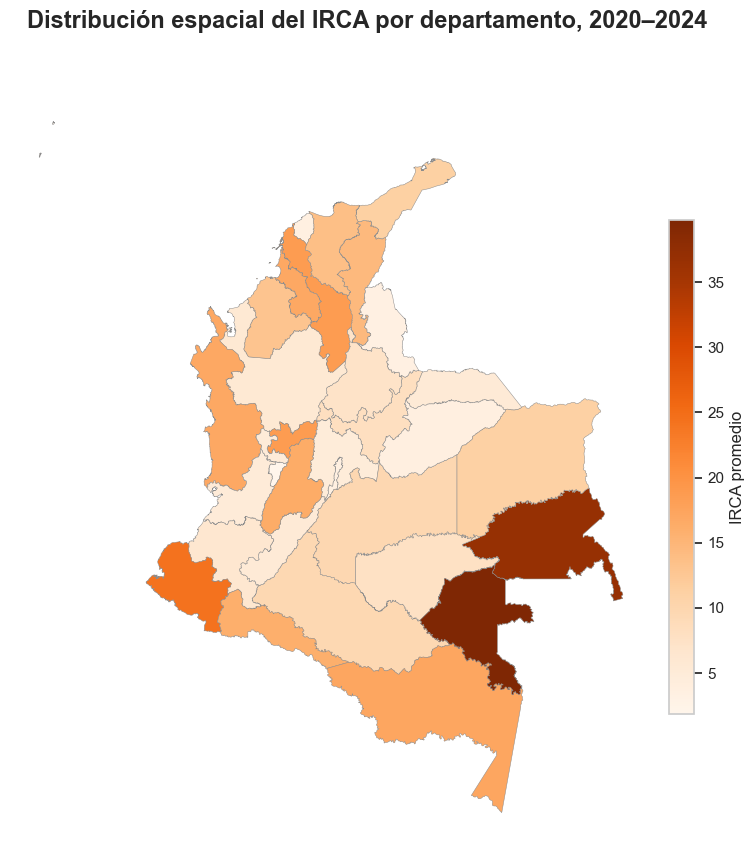

In [132]:
gdf_irca_2020_2024 = gdf_departamentos.merge(
    irca_departamental_2020_2024[
        ["dpto_ccdgo", "IRCA_2020_2024"]
    ],
    left_on="DPTO_CCDGO",
    right_on="dpto_ccdgo",
    how="left"
)

fig, ax = plt.subplots(
    1,
    1,
    figsize=(9, 9)
)

gdf_irca_2020_2024.plot(
    ax=ax,
    column="IRCA_2020_2024",
    cmap="Oranges",
    edgecolor="#8c8c8c",
    linewidth=0.35,
    aspect=1,
    legend=True,
    legend_kwds={
        "label": "IRCA promedio",
        "shrink": 0.65,
        "pad": 0.02
    }
)

ax.axis("off")

fig.suptitle(
    "Distribución espacial del IRCA por departamento, 2020–2024",
    fontsize=17,
    fontweight="bold",
    y=0.95
)

plt.tight_layout(rect=[0, 0, 1, 0.93])
plt.show()

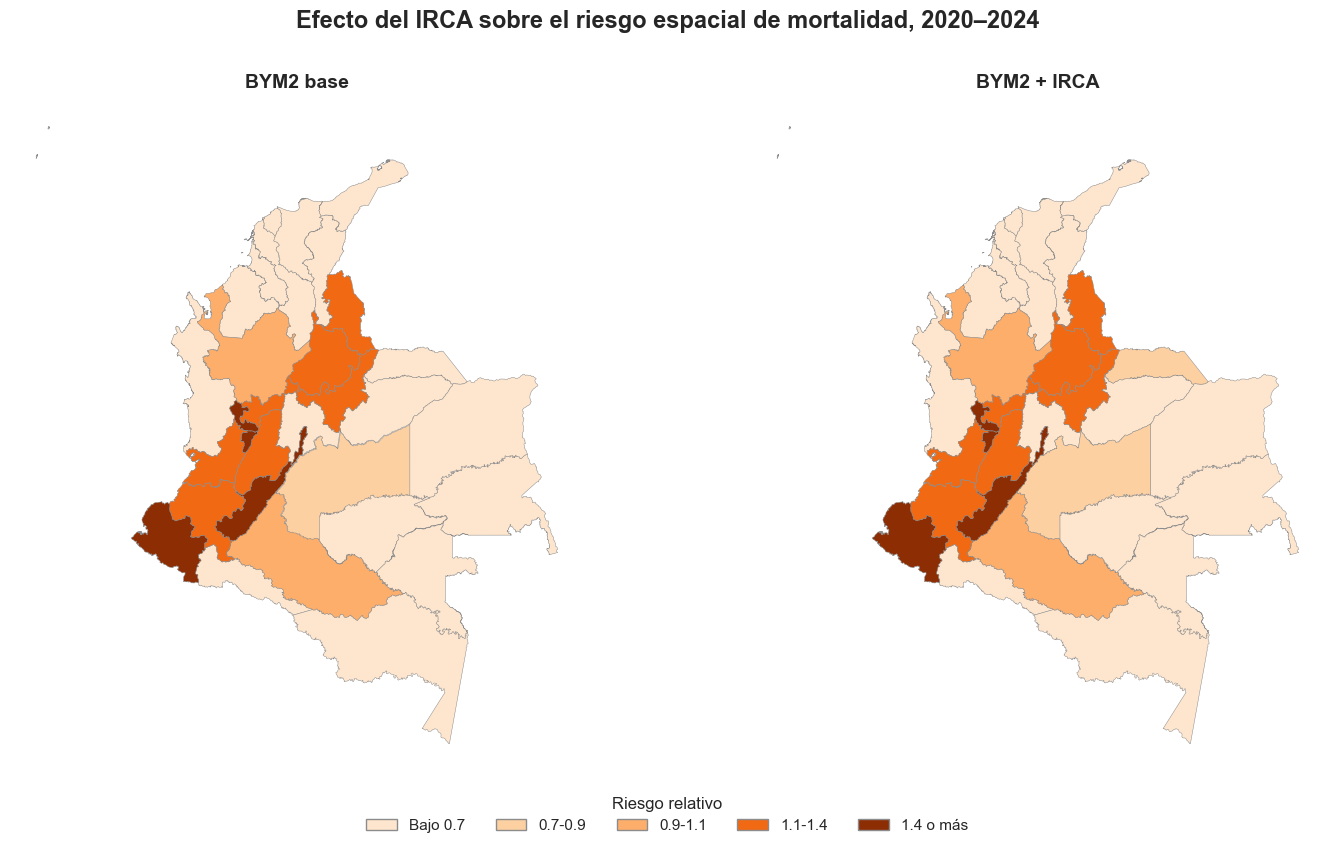

In [135]:
rr_draws_irca_2020_2024 = (
    ajuste_bym2_irca_2020_2024
    .stan_variable("rr")
)

rr_media_irca_2020_2024 = (
    rr_draws_irca_2020_2024.mean(axis=0)
)

gdf_comparacion_irca = (
    gdf_departamentos
    .merge(
        resultados_rr[
            ["dpto_ccdgo", "RR_media"]
        ],
        left_on="DPTO_CCDGO",
        right_on="dpto_ccdgo",
        how="left"
    )
)

gdf_comparacion_irca["RR_IRCA"] = (
    rr_media_irca_2020_2024
)

gdf_comparacion_irca["Categoria_base"] = pd.cut(
    gdf_comparacion_irca["RR_media"],
    bins=bins_rr,
    labels=categorias_rr,
    right=False
)

gdf_comparacion_irca["Categoria_irca"] = pd.cut(
    gdf_comparacion_irca["RR_IRCA"],
    bins=bins_rr,
    labels=categorias_rr,
    right=False
)

fig, axes = plt.subplots(
    1,
    2,
    figsize=(15, 9)
)

for categoria, color in colores_comparacion.items():
    subset_base = gdf_comparacion_irca[
        gdf_comparacion_irca["Categoria_base"] == categoria
    ]

    if not subset_base.empty:
        subset_base.plot(
            ax=axes[0],
            color=color,
            edgecolor="#8c8c8c",
            linewidth=0.35,
            aspect=1
        )

    subset_irca = gdf_comparacion_irca[
        gdf_comparacion_irca["Categoria_irca"] == categoria
    ]

    if not subset_irca.empty:
        subset_irca.plot(
            ax=axes[1],
            color=color,
            edgecolor="#8c8c8c",
            linewidth=0.35,
            aspect=1
        )

axes[0].set_title(
    "BYM2 base",
    fontsize=14,
    fontweight="bold"
)

axes[1].set_title(
    "BYM2 + IRCA",
    fontsize=14,
    fontweight="bold"
)

for ax in axes:
    ax.axis("off")

leyenda = [
    Patch(
        facecolor=color,
        edgecolor="#8c8c8c",
        label=categoria
    )
    for categoria, color in colores_comparacion.items()
]

fig.legend(
    handles=leyenda,
    title="Riesgo relativo",
    loc="lower center",
    bbox_to_anchor=(0.5, 0.03),
    ncol=5,
    frameon=False
)

fig.suptitle(
    "Efecto del IRCA sobre el riesgo espacial de mortalidad, 2020–2024",
    fontsize=17,
    fontweight="bold",
    y=0.96
)

plt.tight_layout(rect=[0, 0.09, 1, 0.93])
plt.show()

## 11. Modelo BYM2 multivariable con IPM e IRCA

Una vez evaluadas individualmente las asociaciones del IPM y el IRCA con la mortalidad por cáncer de estómago, ambas covariables se incorporan simultáneamente al modelo BYM2. Esto permite estimar la asociación de cada indicador con el riesgo relativo de mortalidad mientras se controla por la otra covariable y por la estructura espacial residual.

El predictor lineal del modelo se define como:

$$
\log(\theta_i)
=\alpha
+
\beta_{IPM}X_{IPM,i}
+
\beta_{IRCA}X_{IRCA,i}
+
\sigma
\left(
\sqrt{\frac{\rho}{s}}\phi_i
+
\sqrt{1-\rho}\delta_i
\right)
$$

donde $X_{IPM,i}$ y $X_{IRCA,i}$ corresponden a las covariables estandarizadas para el departamento $i$. Los coeficientes $\beta_{IPM}$ y $\beta_{IRCA}$ representan sus asociaciones con el log-riesgo relativo después de considerar simultáneamente ambas covariables y los efectos aleatorios espaciales.

### 11.1 Preparación de las covariables

In [136]:
datos_bym2_multivariable = (
    datos_bym2_ordenados
    .merge(
        ipm_departamental_2020_2024[
            [
                "dpto_ccdgo",
                "IPM_2020_2024",
                "IPM_2020_2024_std"
            ]
        ],
        on="dpto_ccdgo",
        how="left",
        validate="one_to_one"
    )
    .merge(
        irca_departamental_2020_2024[
            [
                "dpto_ccdgo",
                "IRCA_2020_2024",
                "IRCA_2020_2024_std"
            ]
        ],
        on="dpto_ccdgo",
        how="left",
        validate="one_to_one"
    )
)

print("Departamentos:", len(datos_bym2_multivariable))

print(
    "IPM faltantes:",
    datos_bym2_multivariable["IPM_2020_2024"].isna().sum()
)

print(
    "IRCA faltantes:",
    datos_bym2_multivariable["IRCA_2020_2024"].isna().sum()
)

print(
    "Orden conservado:",
    datos_bym2_multivariable["dpto_ccdgo"].tolist()
    == datos_bym2_ordenados["dpto_ccdgo"].tolist()
)

print(
    "Media IPM estandarizado:",
    round(datos_bym2_multivariable["IPM_2020_2024_std"].mean(), 6)
)

print(
    "DE IPM estandarizado:",
    round(datos_bym2_multivariable["IPM_2020_2024_std"].std(ddof=1), 6)
)

print(
    "Media IRCA estandarizado:",
    round(datos_bym2_multivariable["IRCA_2020_2024_std"].mean(), 6)
)

print(
    "DE IRCA estandarizado:",
    round(datos_bym2_multivariable["IRCA_2020_2024_std"].std(ddof=1), 6)
)

Departamentos: 33
IPM faltantes: 0
IRCA faltantes: 0
Orden conservado: True
Media IPM estandarizado: 0.0
DE IPM estandarizado: 1.0
Media IRCA estandarizado: -0.0
DE IRCA estandarizado: 1.0


### 11.2 Ajuste del modelo BYM2 multivariable

El modelo incorpora simultáneamente el IPM y el IRCA estandarizados, manteniendo la misma estructura espacial BYM2 utilizada en los modelos anteriores. De esta forma, cada coeficiente representa la asociación de su respectiva covariable con el riesgo de mortalidad después de considerar la otra covariable y la variabilidad espacial residual.

In [137]:
X_ipm = (
    datos_bym2_multivariable["IPM_2020_2024_std"]
    .astype(float)
    .to_numpy()
)

X_irca = (
    datos_bym2_multivariable["IRCA_2020_2024_std"]
    .astype(float)
    .to_numpy()
)

datos_modelo_multivariable = {
    "N": len(datos_bym2_multivariable),
    "N_conn": len(idx_conn),
    "N_edges": len(node1),
    "Y": Y,
    "E": E,
    "Y_conn": Y_conn,
    "E_conn": E_conn,
    "Y_island": Y_island,
    "E_island": E_island,
    "node1": node1,
    "node2": node2,
    "scaling_factor": scaling_factor,
    "idx_conn": idx_conn,
    "idx_island": idx_island,
    "X_ipm": X_ipm,
    "X_irca": X_irca
}

print("N:", datos_modelo_multivariable["N"])
print("N conectados:", datos_modelo_multivariable["N_conn"])
print("N aristas:", datos_modelo_multivariable["N_edges"])
print("Observadas:", datos_modelo_multivariable["Y"].sum())
print("Esperadas:", round(datos_modelo_multivariable["E"].sum(), 2))

print(
    "X_ipm:",
    len(X_ipm),
    "Media:",
    round(X_ipm.mean(), 6),
    "DE:",
    round(X_ipm.std(ddof=1), 6)
)

print(
    "X_irca:",
    len(X_irca),
    "Media:",
    round(X_irca.mean(), 6),
    "DE:",
    round(X_irca.std(ddof=1), 6)
)

print(
    "Correlación IPM-IRCA:",
    round(np.corrcoef(X_ipm, X_irca)[0, 1], 3)
)

print("Índice isla:", idx_island)

print(
    "Departamento isla:",
    datos_bym2_multivariable.iloc[idx_island - 1]["DPNOM"]
)

N: 33
N conectados: 32
N aristas: 74
Observadas: 26418
Esperadas: 26418.0
X_ipm: 33 Media: 0.0 DE: 1.0
X_irca: 33 Media: -0.0 DE: 1.0
Correlación IPM-IRCA: 0.597
Índice isla: 28
Departamento isla: Archipiélago de San Andrés, Providencia y Santa Catalina


#### 11.2.1 Ajuste del modelo

In [138]:
modelo_bym2_multivariable = CmdStanModel(
    stan_file=r"C:\Users\USER\Desktop\Tesis\src\bym2_estomago_ipm_irca.stan"
)

ajuste_bym2_multivariable = modelo_bym2_multivariable.sample(
    data=datos_modelo_multivariable,
    chains=4,
    parallel_chains=4,
    iter_warmup=1000,
    iter_sampling=1000,
    seed=1234,
    adapt_delta=0.99,
    max_treedepth=15,
    show_progress=True
)

10:57:51 - cmdstanpy - INFO - compiling stan file C:\Users\USER\Desktop\Tesis\src\bym2_estomago_ipm_irca.stan to exe file C:\Users\USER\Desktop\Tesis\src\bym2_estomago_ipm_irca.exe
10:58:06 - cmdstanpy - INFO - compiled model executable: C:\Users\USER\Desktop\Tesis\src\bym2_estomago_ipm_irca.exe
10:58:07 - cmdstanpy - INFO - CmdStan start processing


chain 1 |          | 00:00 Status

chain 2 |          | 00:00 Status

chain 3 |          | 00:00 Status

chain 4 |          | 00:00 Status

10:58:25 - cmdstanpy - INFO - CmdStan done processing.


### 11.3 Parámetros posteriores del modelo multivariable

Se resumen las distribuciones posteriores de los parámetros globales del modelo BYM2 multivariable, incluyendo los coeficientes asociados al IPM y al IRCA, así como los parámetros correspondientes a la variabilidad residual y su estructura espacial.

In [139]:
resumen_multivariable = ajuste_bym2_multivariable.summary()

parametros_multivariable = [
    "alpha",
    "beta_ipm",
    "beta_irca",
    "sigma",
    "rho"
]

filas_multivariable = []

for parametro in parametros_multivariable:
    draws = ajuste_bym2_multivariable.stan_variable(parametro)

    filas_multivariable.append({
        "Parámetro": parametro,
        "Media": np.mean(draws),
        "Mediana": np.median(draws),
        "DE": np.std(draws, ddof=1),
        "IC 2.5%": np.quantile(draws, 0.025),
        "IC 97.5%": np.quantile(draws, 0.975),
        "ESS": resumen_multivariable.loc[parametro, "N_Eff"],
        "R-hat": resumen_multivariable.loc[parametro, "R_hat"]
    })

tabla_parametros_multivariable = pd.DataFrame(
    filas_multivariable
)

tabla_parametros_multivariable["Parámetro"] = (
    tabla_parametros_multivariable["Parámetro"]
    .replace({
        "alpha": "α",
        "beta_ipm": "β IPM",
        "beta_irca": "β IRCA",
        "sigma": "σ",
        "rho": "ρ"
    })
)

styled_parametros_multivariable = (
    tabla_parametros_multivariable
    .style
    .hide(axis="index")
    .format({
        "Media": "{:.3f}",
        "Mediana": "{:.3f}",
        "DE": "{:.3f}",
        "IC 2.5%": "{:.3f}",
        "IC 97.5%": "{:.3f}",
        "ESS": "{:.2f}",
        "R-hat": "{:.2f}"
    })
    .set_table_styles([
        {
            "selector": "table",
            "props": [
                ("margin", "0 auto"),
                ("width", "auto"),
                ("border-collapse", "collapse")
            ]
        },
        {
            "selector": "th",
            "props": [
                ("text-align", "center"),
                ("background-color", "#f2f2f2"),
                ("color", "black"),
                ("font-weight", "bold"),
                ("border", "1px solid black"),
                ("padding", "10px")
            ]
        },
        {
            "selector": "td",
            "props": [
                ("text-align", "center"),
                ("border", "1px solid black"),
                ("padding", "10px")
            ]
        }
    ])
    .set_properties(
        subset=["Parámetro"],
        **{"text-align": "left"}
    )
)

display(
    HTML(
        "<div style='text-align: center; width: 100%;'>"
        + styled_parametros_multivariable.to_html()
        + "</div>"
    )
)

Parámetro,Media,Mediana,DE,IC 2.5%,IC 97.5%,ESS,R-hat
α,-0.526,-0.524,0.051,-0.638,-0.428,3340.13,1.00
β IPM,-0.659,-0.659,0.133,-0.916,-0.395,1875.48,1.00
β IRCA,-0.208,-0.204,0.132,-0.480,0.043,1850.66,1.00
σ,0.534,0.525,0.085,0.392,0.721,1279.80,1.00
ρ,0.822,0.895,0.200,0.278,1.000,427.44,1.00


El modelo multivariable mostró una asociación negativa entre el IPM y el riesgo relativo de mortalidad por cáncer de estómago. El coeficiente posterior del IPM fue $\beta_{IPM}=-0.659$ (IC95%: $-0.916$ a $-0.395$), manteniendo una asociación consistente incluso después de ajustar simultáneamente por el IRCA y por la estructura espacial.

Para el IRCA, el coeficiente posterior también fue negativo ($\beta_{IRCA}=-0.208$), pero su intervalo de credibilidad del 95% ($-0.480$ a $0.043$) incluyó el cero. A diferencia del modelo individual, la asociación del IRCA pierde claridad al incorporar simultáneamente el IPM, lo que indica que parte de la señal observada inicialmente puede estar compartida con las diferencias territoriales de pobreza multidimensional.

La desviación estándar del efecto aleatorio fue $\sigma=0.534$, mientras que $\rho=0.822$, indicando que la mayor parte de la variabilidad residual continúa asociada al componente espacialmente estructurado. Todos los parámetros presentaron valores de $R\text{-hat}=1.00$ y tamaños efectivos de muestra adecuados.

### 11.4 Efectos posteriores de las covariables

Los coeficientes posteriores del IPM y del IRCA se transforman mediante $e^\beta$ para expresar sus asociaciones en términos de riesgo relativo. Debido a que ambas covariables fueron estandarizadas, cada estimación representa el cambio relativo en el riesgo asociado con un incremento de una desviación estándar de la covariable correspondiente, manteniendo constante la otra covariable.

In [140]:
beta_ipm_multi_draws = (
    ajuste_bym2_multivariable
    .stan_variable("beta_ipm")
)

beta_irca_multi_draws = (
    ajuste_bym2_multivariable
    .stan_variable("beta_irca")
)

rr_ipm_multi_draws = np.exp(beta_ipm_multi_draws)
rr_irca_multi_draws = np.exp(beta_irca_multi_draws)

prob_beta_ipm_negativo = (
    beta_ipm_multi_draws < 0
).mean()

prob_beta_irca_negativo_multi = (
    beta_irca_multi_draws < 0
).mean()

efectos_multivariable = pd.DataFrame({
    "Covariable": [
        "IPM",
        "IRCA"
    ],
    "β media": [
        beta_ipm_multi_draws.mean(),
        beta_irca_multi_draws.mean()
    ],
    "β IC 2.5%": [
        np.quantile(beta_ipm_multi_draws, 0.025),
        np.quantile(beta_irca_multi_draws, 0.025)
    ],
    "β IC 97.5%": [
        np.quantile(beta_ipm_multi_draws, 0.975),
        np.quantile(beta_irca_multi_draws, 0.975)
    ],
    "RR por 1 DE": [
        rr_ipm_multi_draws.mean(),
        rr_irca_multi_draws.mean()
    ],
    "RR IC 2.5%": [
        np.quantile(rr_ipm_multi_draws, 0.025),
        np.quantile(rr_irca_multi_draws, 0.025)
    ],
    "RR IC 97.5%": [
        np.quantile(rr_ipm_multi_draws, 0.975),
        np.quantile(rr_irca_multi_draws, 0.975)
    ],
    "P(β < 0)": [
        prob_beta_ipm_negativo,
        prob_beta_irca_negativo_multi
    ]
})

styled_efectos_multivariable = (
    efectos_multivariable
    .style
    .hide(axis="index")
    .format({
        "β media": "{:.3f}",
        "β IC 2.5%": "{:.3f}",
        "β IC 97.5%": "{:.3f}",
        "RR por 1 DE": "{:.3f}",
        "RR IC 2.5%": "{:.3f}",
        "RR IC 97.5%": "{:.3f}",
        "P(β < 0)": "{:.4f}"
    })
    .set_table_styles([
        {
            "selector": "table",
            "props": [
                ("margin", "0 auto"),
                ("width", "auto"),
                ("border-collapse", "collapse")
            ]
        },
        {
            "selector": "th",
            "props": [
                ("text-align", "center"),
                ("background-color", "#f2f2f2"),
                ("color", "black"),
                ("font-weight", "bold"),
                ("border", "1px solid black"),
                ("padding", "10px")
            ]
        },
        {
            "selector": "td",
            "props": [
                ("text-align", "center"),
                ("border", "1px solid black"),
                ("padding", "10px")
            ]
        }
    ])
    .set_properties(
        subset=["Covariable"],
        **{"text-align": "left"}
    )
)

display(
    HTML(
        "<div style='text-align: center; width: 100%;'>"
        + styled_efectos_multivariable.to_html()
        + "</div>"
    )
)

print(
    "1 DE del IPM equivale a:",
    round(sd_ipm_2020_2024, 3),
    "puntos porcentuales"
)

print(
    "1 DE del IRCA equivale a:",
    round(sd_irca_2020_2024, 3),
    "puntos"
)

Covariable,β media,β IC 2.5%,β IC 97.5%,RR por 1 DE,RR IC 2.5%,RR IC 97.5%,P(β < 0)
IPM,-0.659,-0.916,-0.395,0.522,0.400,0.673,1.0000
IRCA,-0.208,-0.480,0.043,0.820,0.619,1.044,0.9453


1 DE del IPM equivale a: 14.967 puntos porcentuales
1 DE del IRCA equivale a: 8.98 puntos


En el modelo multivariable, el IPM mantuvo una asociación negativa consistente con el riesgo relativo de mortalidad por cáncer de estómago. Un incremento de una desviación estándar del IPM, equivalente a 14.97 puntos porcentuales, se asoció con un RR posterior medio de 0.522 (IC95%: 0.400–0.673), con una probabilidad posterior de asociación negativa igual a 1.

Para el IRCA, un incremento de una desviación estándar, equivalente a 8.98 puntos, presentó un RR posterior medio de 0.820 (IC95%: 0.619–1.044). Aunque la probabilidad posterior de una asociación negativa fue alta ($P(\beta_{IRCA}<0)=0.9453$), el intervalo de credibilidad incluyó el valor 1. Por tanto, al considerar simultáneamente el IPM, la evidencia de una asociación independiente del IRCA es menos concluyente que la observada en su modelo individual.

Los resultados muestran que la asociación del IPM se mantiene después del ajuste por IRCA, mientras que la asociación inicialmente observada para el IRCA se atenúa al incorporar ambas covariables simultáneamente.

### 11.5 Riesgo relativo posterior por departamento

A partir de las distribuciones posteriores del modelo multivariable se estima el riesgo relativo de mortalidad para cada departamento. Estas estimaciones incorporan simultáneamente el IPM, el IRCA y los componentes aleatorios espacialmente estructurado y no estructurado del modelo BYM2.

In [141]:
rr_multivariable_draws = (
    ajuste_bym2_multivariable
    .stan_variable("rr")
)

resultados_rr_multivariable = datos_bym2_multivariable[
    [
        "dpto_ccdgo",
        "DPNOM",
        "Observadas",
        "Esperadas",
        "SMR"
    ]
].copy()

resultados_rr_multivariable["RR_media"] = (
    rr_multivariable_draws.mean(axis=0)
)

resultados_rr_multivariable["RR_mediana"] = (
    np.median(rr_multivariable_draws, axis=0)
)

resultados_rr_multivariable["RR_IC_2.5"] = (
    np.quantile(rr_multivariable_draws, 0.025, axis=0)
)

resultados_rr_multivariable["RR_IC_97.5"] = (
    np.quantile(rr_multivariable_draws, 0.975, axis=0)
)

resultados_rr_multivariable["P_RR_mayor_1"] = (
    (rr_multivariable_draws > 1).mean(axis=0)
)

resultados_rr_multivariable = (
    resultados_rr_multivariable
    .sort_values("RR_media", ascending=False)
    .reset_index(drop=True)
)

styled_rr_multivariable = (
    resultados_rr_multivariable
    .style
    .hide(axis="index")
    .format({
        "Observadas": "{:,.0f}",
        "Esperadas": "{:,.2f}",
        "SMR": "{:.3f}",
        "RR_media": "{:.3f}",
        "RR_mediana": "{:.3f}",
        "RR_IC_2.5": "{:.3f}",
        "RR_IC_97.5": "{:.3f}",
        "P_RR_mayor_1": "{:.4f}"
    })
    .set_table_styles([
        {
            "selector": "table",
            "props": [
                ("margin", "0 auto"),
                ("width", "auto"),
                ("border-collapse", "collapse")
            ]
        },
        {
            "selector": "th",
            "props": [
                ("text-align", "center"),
                ("background-color", "#f2f2f2"),
                ("color", "black"),
                ("font-weight", "bold"),
                ("border", "1px solid black"),
                ("padding", "10px")
            ]
        },
        {
            "selector": "td",
            "props": [
                ("text-align", "center"),
                ("border", "1px solid black"),
                ("padding", "10px")
            ]
        }
    ])
    .set_properties(
        subset=["DPNOM"],
        **{"text-align": "left"}
    )
)

display(
    HTML(
        "<div style='text-align: center; width: 100%;'>"
        + styled_rr_multivariable.to_html()
        + "</div>"
    )
)

dpto_ccdgo,DPNOM,Observadas,Esperadas,SMR,RR_media,RR_mediana,RR_IC_2.5,RR_IC_97.5,P_RR_mayor_1
66,Risaralda,958,504.67,1.898,1.893,1.893,1.773,2.013,1.0000
63,Quindío,462,283.58,1.629,1.631,1.629,1.485,1.782,1.0000
41,Huila,934,596.98,1.565,1.559,1.558,1.459,1.655,1.0000
11,"Bogotá, D.C.","5,752","4,013.47",1.433,1.433,1.433,1.395,1.470,1.0000
52,Nariño,"1,214",862.37,1.408,1.405,1.404,1.325,1.484,1.0000
17,Caldas,692,532.42,1.300,1.295,1.294,1.202,1.390,1.0000
54,Norte de Santander,"1,062",848.30,1.252,1.250,1.249,1.176,1.324,1.0000
73,Tolima,870,700.46,1.242,1.239,1.239,1.159,1.321,1.0000
76,Valle del Cauca,"2,950","2,383.12",1.238,1.238,1.239,1.195,1.284,1.0000
19,Cauca,972,793.05,1.226,1.225,1.226,1.148,1.302,1.0000


In [145]:
import json
from pathlib import Path

RUTA_RESULTADOS = Path("../Resultados")
RUTA_RESULTADOS.mkdir(parents=True, exist_ok=True)

beta_ipm_draws = ajuste_bym2_multivariable.stan_variable("beta_ipm")
beta_irca_draws = ajuste_bym2_multivariable.stan_variable("beta_irca")
alpha_draws = ajuste_bym2_multivariable.stan_variable("alpha")
sigma_draws = ajuste_bym2_multivariable.stan_variable("sigma")
rho_draws = ajuste_bym2_multivariable.stan_variable("rho")
rr_draws_multi = ajuste_bym2_multivariable.stan_variable("rr")

resumen_multi = ajuste_bym2_multivariable.summary()

def resumen_posterior(draws, parametro):
    return {
        "media": float(np.mean(draws)),
        "mediana": float(np.median(draws)),
        "de": float(np.std(draws, ddof=1)),
        "ic95_inferior": float(np.quantile(draws, 0.025)),
        "ic95_superior": float(np.quantile(draws, 0.975)),
        "ess": float(resumen_multi.loc[parametro, "N_Eff"]),
        "rhat": float(resumen_multi.loc[parametro, "R_hat"])
    }

resultados_departamentales = []

for j, fila in datos_bym2_multivariable.reset_index(drop=True).iterrows():
    rr_j = rr_draws_multi[:, j]

    resultados_departamentales.append({
        "dpto_ccdgo": str(fila["dpto_ccdgo"]),
        "departamento": str(fila["DPNOM"]),
        "observadas": int(fila["Observadas"]),
        "esperadas": float(fila["Esperadas"]),
        "smr": float(fila["SMR"]),
        "ipm_2020_2024": float(fila["IPM_2020_2024"]),
        "ipm_std": float(fila["IPM_2020_2024_std"]),
        "irca_2020_2024": float(fila["IRCA_2020_2024"]),
        "irca_std": float(fila["IRCA_2020_2024_std"]),
        "rr_media": float(np.mean(rr_j)),
        "rr_mediana": float(np.median(rr_j)),
        "rr_ic95_inferior": float(np.quantile(rr_j, 0.025)),
        "rr_ic95_superior": float(np.quantile(rr_j, 0.975)),
        "prob_rr_mayor_1": float(np.mean(rr_j > 1))
    })

resultados_json = {
    "modelo": {
        "nombre": "BYM2 multivariable con IPM e IRCA",
        "cancer": "Cáncer de estómago",
        "periodo": "2020-2024",
        "unidad_espacial": "Departamento",
        "n_departamentos": 33
    },
    "mcmc": {
        "chains": 4,
        "iter_warmup": 1000,
        "iter_sampling": 1000,
        "draws_posteriores": 4000,
        "seed": 1234,
        "adapt_delta": 0.99,
        "max_treedepth": 15
    },
    "estructura_espacial": {
        "n_conectados": 32,
        "n_aristas": 74,
        "scaling_factor": float(scaling_factor),
        "departamento_isla": "Archipiélago de San Andrés, Providencia y Santa Catalina"
    },
    "covariables": {
        "IPM": {
            "periodo": "2020-2024",
            "metodo": "Promedio simple de las estimaciones departamentales anuales",
            "media_original": float(
                datos_bym2_multivariable["IPM_2020_2024"].mean()
            ),
            "de_original": float(
                datos_bym2_multivariable["IPM_2020_2024"].std(ddof=1)
            ),
            "incremento_1_de": float(
                datos_bym2_multivariable["IPM_2020_2024"].std(ddof=1)
            )
        },
        "IRCA": {
            "periodo": "2020-2024",
            "metodo": "Promedio simple de los valores departamentales anuales disponibles",
            "imputacion": False,
            "media_original": float(
                datos_bym2_multivariable["IRCA_2020_2024"].mean()
            ),
            "de_original": float(
                datos_bym2_multivariable["IRCA_2020_2024"].std(ddof=1)
            ),
            "incremento_1_de": float(
                datos_bym2_multivariable["IRCA_2020_2024"].std(ddof=1)
            )
        },
        "correlacion_ipm_irca": float(
            np.corrcoef(
                datos_bym2_multivariable["IPM_2020_2024_std"],
                datos_bym2_multivariable["IRCA_2020_2024_std"]
            )[0, 1]
        )
    },
    "parametros_globales": {
        "alpha": resumen_posterior(alpha_draws, "alpha"),
        "beta_ipm": resumen_posterior(beta_ipm_draws, "beta_ipm"),
        "beta_irca": resumen_posterior(beta_irca_draws, "beta_irca"),
        "sigma": resumen_posterior(sigma_draws, "sigma"),
        "rho": resumen_posterior(rho_draws, "rho")
    },
    "efectos_covariables": {
        "IPM": {
            "rr_1_de_media": float(np.mean(np.exp(beta_ipm_draws))),
            "rr_1_de_mediana": float(np.median(np.exp(beta_ipm_draws))),
            "rr_ic95_inferior": float(
                np.quantile(np.exp(beta_ipm_draws), 0.025)
            ),
            "rr_ic95_superior": float(
                np.quantile(np.exp(beta_ipm_draws), 0.975)
            ),
            "prob_beta_negativo": float(
                np.mean(beta_ipm_draws < 0)
            )
        },
        "IRCA": {
            "rr_1_de_media": float(np.mean(np.exp(beta_irca_draws))),
            "rr_1_de_mediana": float(np.median(np.exp(beta_irca_draws))),
            "rr_ic95_inferior": float(
                np.quantile(np.exp(beta_irca_draws), 0.025)
            ),
            "rr_ic95_superior": float(
                np.quantile(np.exp(beta_irca_draws), 0.975)
            ),
            "prob_beta_negativo": float(
                np.mean(beta_irca_draws < 0)
            )
        }
    },
    "resultados_departamentales": resultados_departamentales
}

RUTA_JSON_MULTIVARIABLE = (
    RUTA_RESULTADOS
    / "bym2_ipm_irca_2020_2024_estomago.json"
)

with open(
    RUTA_JSON_MULTIVARIABLE,
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        resultados_json,
        f,
        ensure_ascii=False,
        indent=4
    )

print("Archivo guardado en:")
print(RUTA_JSON_MULTIVARIABLE)

Archivo guardado en:
..\Resultados\bym2_ipm_irca_2020_2024_estomago.json


### 11.6 Comparación del riesgo espacial

Se compara la distribución espacial del riesgo relativo posterior estimado por el modelo BYM2 base con la obtenida mediante el modelo multivariable que incorpora simultáneamente el IPM y el IRCA. Esta comparación permite evaluar visualmente los cambios en el patrón espacial del riesgo después de considerar ambas covariables.

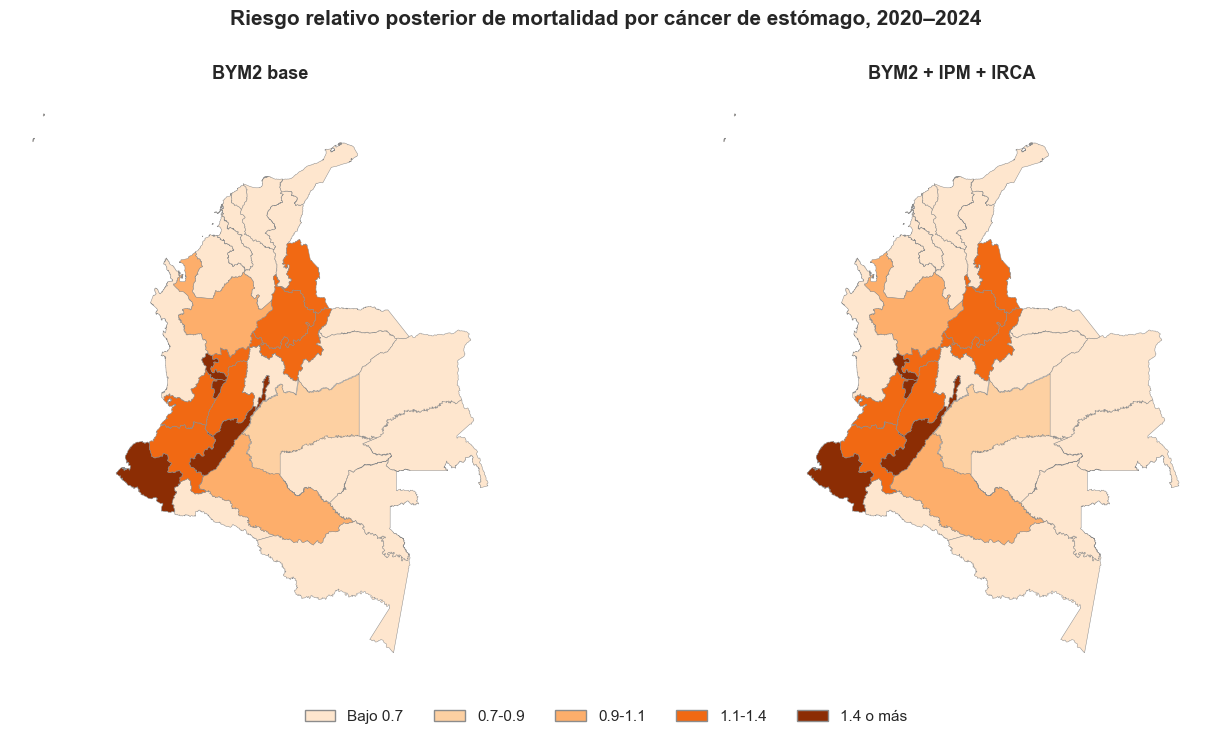

In [142]:
gdf_rr_base = gdf_departamentos.merge(
    resultados_rr[
        ["dpto_ccdgo", "RR_media"]
    ],
    left_on="DPTO_CCDGO",
    right_on="dpto_ccdgo",
    how="left"
).rename(columns={"RR_media": "RR_base"})

gdf_rr_multivariable = gdf_departamentos.merge(
    resultados_rr_multivariable[
        ["dpto_ccdgo", "RR_media"]
    ],
    left_on="DPTO_CCDGO",
    right_on="dpto_ccdgo",
    how="left"
).rename(columns={"RR_media": "RR_multivariable"})

categorias_rr = [
    "Bajo 0.7",
    "0.7-0.9",
    "0.9-1.1",
    "1.1-1.4",
    "1.4 o más"
]

bins_rr = [
    -np.inf,
    0.7,
    0.9,
    1.1,
    1.4,
    np.inf
]

colores_comparacion = {
    "Bajo 0.7": "#fee6ce",
    "0.7-0.9": "#fdd0a2",
    "0.9-1.1": "#fdae6b",
    "1.1-1.4": "#f16913",
    "1.4 o más": "#8c2d04"
}

gdf_rr_base["Categoria"] = pd.cut(
    gdf_rr_base["RR_base"],
    bins=bins_rr,
    labels=categorias_rr,
    right=False
)

gdf_rr_multivariable["Categoria"] = pd.cut(
    gdf_rr_multivariable["RR_multivariable"],
    bins=bins_rr,
    labels=categorias_rr,
    right=False
)

fig, axes = plt.subplots(
    1,
    2,
    figsize=(14, 8)
)

for categoria in categorias_rr:
    gdf_rr_base[
        gdf_rr_base["Categoria"] == categoria
    ].plot(
        ax=axes[0],
        color=colores_comparacion[categoria],
        edgecolor="#8c8c8c",
        linewidth=0.35
    )

    gdf_rr_multivariable[
        gdf_rr_multivariable["Categoria"] == categoria
    ].plot(
        ax=axes[1],
        color=colores_comparacion[categoria],
        edgecolor="#8c8c8c",
        linewidth=0.35
    )

axes[0].set_title(
    "BYM2 base",
    fontsize=13,
    fontweight="bold"
)

axes[1].set_title(
    "BYM2 + IPM + IRCA",
    fontsize=13,
    fontweight="bold"
)

for ax in axes:
    ax.set_axis_off()
    ax.set_aspect("equal")

leyenda = [
    Patch(
        facecolor=colores_comparacion[categoria],
        edgecolor="#8c8c8c",
        label=categoria
    )
    for categoria in categorias_rr
]

fig.legend(
    handles=leyenda,
    loc="lower center",
    ncol=5,
    frameon=False,
    bbox_to_anchor=(0.5, 0.03)
)

fig.suptitle(
    "Riesgo relativo posterior de mortalidad por cáncer de estómago, 2020–2024",
    fontsize=15,
    fontweight="bold",
    y=0.94
)

plt.tight_layout(rect=[0, 0.08, 1, 0.92])
plt.show()

## 12. Comparación de modelos mediante DIC

Con el fin de comparar las diferentes especificaciones bayesianas ajustadas, se empleó el criterio de información de la devianza (DIC). Este criterio combina el ajuste del modelo, medido mediante la devianza posterior, con una penalización asociada a su complejidad efectiva.

Valores menores de DIC indican un mejor compromiso entre ajuste y complejidad. La comparación se realizó entre el modelo nulo, el modelo BYM2 base y las diferentes extensiones que incorporan las covariables socioeconómicas y ambientales.

### 12.1 Cálculo del criterio DIC

El criterio de información de la devianza (DIC) permite comparar modelos bayesianos considerando simultáneamente su ajuste y su complejidad efectiva. Para cada modelo se calculó la devianza a partir de la verosimilitud Poisson utilizada en la modelación:

$$
D(\theta)=-2\log p(\mathbf{Y}\mid\theta)
$$

A partir de las muestras posteriores se obtuvo la devianza posterior media:

$$
\bar D=E[D(\theta)\mid\mathbf{Y}]
$$

La complejidad efectiva del modelo se estimó como:

$$
p_D=\bar D-D(\bar\theta)
$$

y finalmente:

$$
DIC=\bar D+p_D
$$

Valores menores de DIC representan un mejor compromiso entre ajuste y complejidad del modelo.

In [150]:
from scipy.special import gammaln

def calcular_dic(ajuste, Y, E):
    log_rr = ajuste.stan_variable("log_rr")

    Y = np.asarray(Y)
    E = np.asarray(E)

    mu_draws = E[None, :] * np.exp(log_rr)

    log_lik_draws = (
        Y[None, :] * np.log(mu_draws)
        - mu_draws
        - gammaln(Y[None, :] + 1)
    )

    deviance_draws = -2 * np.sum(log_lik_draws, axis=1)
    D_bar = np.mean(deviance_draws)

    log_rr_bar = np.mean(log_rr, axis=0)
    mu_bar = E * np.exp(log_rr_bar)

    log_lik_bar = (
        Y * np.log(mu_bar)
        - mu_bar
        - gammaln(Y + 1)
    )

    D_theta_bar = -2 * np.sum(log_lik_bar)

    p_D = D_bar - D_theta_bar
    DIC = D_bar + p_D

    return {
        "D_bar": D_bar,
        "D_theta_bar": D_theta_bar,
        "p_D": p_D,
        "DIC": DIC
    }

In [153]:
def calcular_dic_nulo(ajuste, Y, E):
    alpha = ajuste.stan_variable("alpha")

    Y = np.asarray(Y)
    E = np.asarray(E)

    log_rr = np.repeat(
        alpha[:, None],
        len(Y),
        axis=1
    )

    mu_draws = E[None, :] * np.exp(log_rr)

    log_lik_draws = (
        Y[None, :] * np.log(mu_draws)
        - mu_draws
        - gammaln(Y[None, :] + 1)
    )

    deviance_draws = -2 * np.sum(log_lik_draws, axis=1)
    D_bar = np.mean(deviance_draws)

    alpha_bar = np.mean(alpha)
    mu_bar = E * np.exp(alpha_bar)

    log_lik_bar = (
        Y * np.log(mu_bar)
        - mu_bar
        - gammaln(Y + 1)
    )

    D_theta_bar = -2 * np.sum(log_lik_bar)

    p_D = D_bar - D_theta_bar
    DIC = D_bar + p_D

    return {
        "D_bar": D_bar,
        "D_theta_bar": D_theta_bar,
        "p_D": p_D,
        "DIC": DIC
    }


modelos_dic = {
    "M1": ("Modelo nulo", ajuste_nulo),
    "M2": ("BYM2 base", ajuste_bym2),
    "M3": ("BYM2 + IPM 2018", ajuste_bym2_ipm),
    "M4": ("BYM2 + IPM 2020–2024", ajuste_bym2_ipm_2020_2024),
    "M5": ("BYM2 + IRCA 2020–2024", ajuste_bym2_irca_2020_2024),
    "M6": ("BYM2 + IPM + IRCA", ajuste_bym2_multivariable)
}

resultados_dic = []

for codigo, (nombre, ajuste) in modelos_dic.items():
    if codigo == "M1":
        metricas = calcular_dic_nulo(
            ajuste,
            Y,
            E
        )
    else:
        metricas = calcular_dic(
            ajuste,
            Y,
            E
        )

    resultados_dic.append({
        "Modelo": codigo,
        "Especificación": nombre,
        "D̄": metricas["D_bar"],
        "D(θ̄)": metricas["D_theta_bar"],
        "pD": metricas["p_D"],
        "DIC": metricas["DIC"]
    })

tabla_dic = pd.DataFrame(resultados_dic)

tabla_dic[
    ["D̄", "D(θ̄)", "pD", "DIC"]
] = tabla_dic[
    ["D̄", "D(θ̄)", "pD", "DIC"]
].round(2)

### 12.2 Comparación global de los modelos

La siguiente tabla presenta los componentes del DIC para las seis especificaciones consideradas. La comparación permite evaluar si la incorporación de estructura espacial y covariables mejora el ajuste del modelo una vez considerada su complejidad efectiva.

In [154]:
styled_dic = (
    tabla_dic
    .style
    .hide(axis="index")
    .set_table_styles([
        {
            "selector": "table",
            "props": [
                ("margin-left", "auto"),
                ("margin-right", "auto"),
                ("width", "auto"),
                ("border-collapse", "collapse")
            ]
        },
        {
            "selector": "th",
            "props": [
                ("text-align", "center"),
                ("background-color", "#f2f2f2"),
                ("color", "black"),
                ("font-weight", "bold"),
                ("border", "1px solid black"),
                ("padding", "10px")
            ]
        },
        {
            "selector": "td",
            "props": [
                ("text-align", "center"),
                ("border", "1px solid black"),
                ("padding", "10px")
            ]
        }
    ])
    .set_properties(
        subset=["Especificación"],
        **{"text-align": "left"}
    )
)

display(
    HTML(
        "<div style='text-align: center; width: 100%;'>"
        + styled_dic.to_html()
        + "</div>"
    )
)

Modelo,Especificación,D̄,D(θ̄),pD,DIC
M1,Modelo nulo,5756.230000,5755.250000,0.970000,5757.200000
M2,BYM2 base,274.280000,242.770000,31.510000,305.780000
M3,BYM2 + IPM 2018,273.550000,242.830000,30.730000,304.280000
M4,BYM2 + IPM 2020–2024,274.920000,244.570000,30.350000,305.270000
M5,BYM2 + IRCA 2020–2024,272.010000,240.650000,31.360000,303.370000
M6,BYM2 + IPM + IRCA,272.620000,242.320000,30.300000,302.920000


La incorporación de la estructura espacial produjo una mejora sustancial frente al modelo nulo, cuyo DIC disminuyó de 5757.20 en M1 a 305.78 en el modelo BYM2 base (M2). Entre los modelos espaciales, las diferencias fueron considerablemente menores. El modelo multivariable con IPM e IRCA (M6) presentó el menor DIC (302.92), seguido por el modelo con IRCA (M5; DIC = 303.37) y el modelo con IPM 2018 (M3; DIC = 304.28).

Aunque M6 obtuvo el mejor valor, su diferencia respecto a M5 fue reducida, por lo que la incorporación conjunta de IPM e IRCA representa solo una mejora modesta en términos del DIC. Por su parte, el modelo con IPM 2020–2024 (M4; DIC = 305.27) mostró un desempeño muy similar al BYM2 base (M2; DIC = 305.78). Los resultados indican que la estructura espacial explica una parte fundamental de la variación territorial del riesgo, mientras que la incorporación de las covariables produce mejoras comparativamente pequeñas. Entre las especificaciones evaluadas, M6 presentó el mejor compromiso entre ajuste y complejidad.

### 12.3 Comparación de las medias posteriores del riesgo relativo ajustado

Con el propósito de evaluar los cambios en la estimación del riesgo entre las diferentes especificaciones, se comparó la media posterior del riesgo relativo ajustado para cada departamento:

$$
E(\theta_i \mid \mathbf{Y})
$$

Esta comparación permite identificar los cambios producidos en las estimaciones departamentales al incorporar la estructura espacial y las diferentes covariables en el modelo.

In [159]:
styled_rr_modelos = (
    tabla_rr_modelos
    .rename(columns={
        "dpto_ccdgo": "Código",
        "DPNOM": "Departamento"
    })
    .style
    .hide(axis="index")
    .format({
        "M1": "{:.3f}",
        "M2": "{:.3f}",
        "M3": "{:.3f}",
        "M4": "{:.3f}",
        "M5": "{:.3f}",
        "M6": "{:.3f}"
    })
    .set_table_styles([
        {
            "selector": "table",
            "props": [
                ("margin-left", "auto"),
                ("margin-right", "auto"),
                ("width", "auto"),
                ("border-collapse", "collapse")
            ]
        },
        {
            "selector": "th",
            "props": [
                ("text-align", "center"),
                ("background-color", "#f2f2f2"),
                ("color", "black"),
                ("font-weight", "bold"),
                ("border", "1px solid black"),
                ("padding", "10px")
            ]
        },
        {
            "selector": "td",
            "props": [
                ("text-align", "center"),
                ("border", "1px solid black"),
                ("padding", "10px")
            ]
        }
    ])
    .set_properties(
        subset=["Departamento"],
        **{"text-align": "left"}
    )
)

display(
    HTML(
        "<div style='text-align: center; width: 100%;'>"
        + styled_rr_modelos.to_html()
        + "</div>"
    )
)

Código,Departamento,M1,M2,M3,M4,M5,M6
05,Antioquia,1.000,1.058,1.059,1.058,1.058,1.058
08,Atlántico,1.000,0.498,0.499,0.499,0.498,0.499
11,"Bogotá, D.C.",1.000,1.433,1.434,1.433,1.433,1.433
13,Bolívar,1.000,0.457,0.456,0.456,0.455,0.456
15,Boyacá,1.000,1.162,1.161,1.162,1.161,1.161
17,Caldas,1.000,1.298,1.299,1.297,1.295,1.295
18,Caquetá,1.000,1.082,1.068,1.073,1.083,1.076
19,Cauca,1.000,1.226,1.223,1.224,1.227,1.225
20,Cesar,1.000,0.449,0.450,0.452,0.449,0.451
23,Córdoba,1.000,0.409,0.409,0.409,0.409,0.409


In [160]:
resumen_posterior_modelos = []

for nombre, ajuste in modelos_rr.items():
    rr = ajuste.stan_variable("rr")
    rr_medio_departamento = rr.mean(axis=0)

    resumen_posterior_modelos.append({
        "Modelo": nombre,
        "Media posterior RR": rr_medio_departamento.mean(),
        "Mediana posterior RR": np.median(rr_medio_departamento),
        "DE entre departamentos": rr_medio_departamento.std(ddof=1),
        "Mínimo": rr_medio_departamento.min(),
        "Máximo": rr_medio_departamento.max()
    })

tabla_resumen_modelos = pd.DataFrame(resumen_posterior_modelos)

styled_resumen_modelos = (
    tabla_resumen_modelos
    .style
    .hide(axis="index")
    .format({
        "Media posterior RR": "{:.3f}",
        "Mediana posterior RR": "{:.3f}",
        "DE entre departamentos": "{:.3f}",
        "Mínimo": "{:.3f}",
        "Máximo": "{:.3f}"
    })
    .set_table_styles([
        {
            "selector": "table",
            "props": [
                ("margin-left", "auto"),
                ("margin-right", "auto"),
                ("width", "auto"),
                ("border-collapse", "collapse")
            ]
        },
        {
            "selector": "th",
            "props": [
                ("text-align", "center"),
                ("background-color", "#f2f2f2"),
                ("color", "black"),
                ("font-weight", "bold"),
                ("border", "1px solid black"),
                ("padding", "10px")
            ]
        },
        {
            "selector": "td",
            "props": [
                ("text-align", "center"),
                ("border", "1px solid black"),
                ("padding", "10px")
            ]
        }
    ])
)

display(
    HTML(
        "<div style='text-align: center; width: 100%;'>"
        + styled_resumen_modelos.to_html()
        + "</div>"
    )
)

Modelo,Media posterior RR,Mediana posterior RR,DE entre departamentos,Mínimo,Máximo
M1,1.000,1.000,0.000,1.000,1.000
M2,0.795,0.680,0.521,0.069,1.895
M3,0.795,0.684,0.521,0.076,1.894
M4,0.796,0.683,0.520,0.073,1.891
M5,0.794,0.677,0.523,0.042,1.895
M6,0.795,0.685,0.522,0.056,1.893


El modelo nulo (M1) asigna un riesgo relativo común de 1 a todos los departamentos, por lo que no presenta variabilidad territorial. La incorporación de la estructura espacial en M2 permite diferenciar los riesgos departamentales, con valores posteriores medios entre 0.069 y 1.895. A partir de M2, las diferentes especificaciones presentan distribuciones globales muy similares: las medias se mantienen alrededor de 0.795, la desviación estándar entre departamentos alrededor de 0.52 y los valores máximos próximos a 1.89. Esto indica que la incorporación de IPM e IRCA modifica las estimaciones de departamentos particulares, pero no altera sustancialmente la distribución general del riesgo relativo posterior entre departamentos.